# Committor from an infretis StapleTIS Run (CG permeation, many CVs)

Fits the committor with NPNEq (`CommittorNE`, CuPy) to the paths of an **infretis StapleTIS** simulation and compares it with the exact committor.

**How the paths become training data** (the same code as `load_tis_data_cupy.py`: `tis_data.prepare_data`, which switches to `infretis_data.py` for infretis runs; details in `docs/npneq_tis_notes.md`, sections 3, 9 and 15):
- **Read with infretis' own definitions:** interfaces and swap settings from `infretis.toml`, one row per finished path from `infretis_data.txt`, the order parameters from `load/<pnr>/order.txt` (or an h5 archive), and each path's core in an ensemble from infretis' `StaplePath.get_sh_region`.
- **Cut at M:** an ensemble only keeps paths that cross its middle interface M, so the frames before that crossing are conditioned on their future. Every (path, ensemble) pair gives one piece: the path from its first frame past M (searched from the core start) to its end. Optionally also the *mirrored piece*: the part before the last M crossing, read backwards (`REVERSED`).
- **Weights:** infretis records per (path, ensemble) the occupancy `path_f` and the weight `path_w` it put into the swap matrix (0.5 for LML/RMR paths in the inner staple ensembles). The weighting has to undo how the sampler used w: with swaps (infinite swap or staple swaps) that is `path_f / path_w` (`'staple'`), with shooting only `path_f` (`'rejections'`). By default the loader picks this from the run (`WEIGHTINGS = [None]`); several weightings can be fitted side by side by listing them.

**The run:** coarse-grained (Martini 3) permeation of a small solute (ALA bead) through a DPPC bilayer, GROMACS, StapleTIS with infinite swap (`CG_permeation/infstapletis`; the P2C6 system is the same with another solute). The order parameter is λ = 10 (z_ligand − z_bilayer), in Å, from the bilayer centre of mass; A is the water on one side (λ ≤ the first interface) and B the water on the other (λ ≥ the last).

**Many CVs:** `order.txt` of the newer `OP.py` has a column per CV after the time: λ, the ligand's orientation θ, the number of waters around it, vz, the lateral position (x, y), the box length, and the PO4 shift, far shift, head-group and water-core counts. `CV_NAMES` names the columns and `CV_EXCLUDE` leaves out the ones that are no CVs: the lateral position (the bilayer is translation invariant), the box length (constant) and vz (odd under time reversal, and stored with the wrong sign on backward-integrated frames, so it is wrong for the mirrored pieces and for the fit). Constant columns are dropped automatically. **Edit `CV_NAMES` to match your `order.txt`** (the notebook checks the count). Every iteration of the fit draws one of the CVs at random, so the cost per iteration does not depend on how many CVs there are, but each one needs enough draws: scale `MAX_ITER` with the number of CVs (default 1000 per CV).

**No exact committor** (section 5 sets `q_exact_of = None`). Instead section 7 shows how q depends on every CV (mean q per bin of each CV, and how much of the variance of q each CV alone explains), which is the point of fitting with many CVs: the committor of the system is a function of the solvent and lipid response, not of λ alone.

## 1. Imports

In [1]:
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Run from examples/: the CuPy optimalrcs package and the path readers of the examples
REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import tis_data
import infretis_data
import seed_runs
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Settings

**Run and data**

| Name | Meaning |
|---|---|
| `TIS_DIR` | the infretis simulation folder (`infretis.toml`, `infretis_data.txt`, `load/`) |
| `H5_FILE` | order parameters from an `inft store_txt -order` archive instead of `load/` (`None`: use `load/`) |
| `LAMBDA_A`, `LAMBDA_B` | states A (λ ≤ λ_A) and B (λ ≥ λ_B); `None`: the first and last interface |
| `BURN_IN_FRACTION` | the first part of the rows of `infretis_data.txt` (the order in which the paths ended) is skipped; the initial load paths always are |
| `PATHS_PER_ENSEMBLE`, `THIN` | at most this many paths per ensemble, evenly spaced (`None`: all), after keeping every `THIN`-th |
| `CV_NAMES`, `CV_EXCLUDE` | names of the columns of `order.txt` (after the time, λ first) and the ones that are no CVs; the rest, minus constant columns, are the fit CVs |
| `ITER_PER_CV` | main-fit iterations per CV (`MAX_ITER` = this × the number of CVs) |
| `REVERSED` | also use the mirrored pieces (time-reversible dynamics at equilibrium) |
| `WEIGHTINGS` | the weightings to fit, one fit each: `None` = the run's default, `'staple'` = path_f / path_w, `'rejections'` = path_f, `'none'` = 1 per (path, ensemble). One entry is enough; list several to compare them |

**Fit** (the same for every weighting): `SEEDS` (which CV and envelope centre each iteration draws), a warm-up of `WARMUP_ITER` iterations with a wide envelope, then `MAX_ITER` iterations, in chunks of `CHUNK` after which the plots are shown and saved. `STOPPED_ENDS` (default `True`): a piece that ends outside A and B was stopped by the path's own end (a turn); the stopped Z_q then uses q at that end for windows that pass it (`set_stopped_traj_end`), and the A/B traps are made long enough that no window is dropped. `NY` is the degree of the polynomial basis, `LAZY_BASIS` evaluates it on the fly (GPU memory).

In [4]:
TIS_DIR = f'/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/CG_P2P5'   # copy infretis.toml, infretis_data.txt and archive.h5 (or load/) of the run here
H5_FILE = f'{TIS_DIR}/paths_orderonly.h5'  # None: read load/<pnr>/order.txt
LAMBDA_A, LAMBDA_B = -24.0, 24.0    # None: first and last interface
BURN_IN_FRACTION = 0.6
PATHS_PER_ENSEMBLE = 1200          # None: all paths after the burn-in
THIN = 1
REVERSED = True
WEIGHTINGS = ['rejections']                # None: the run's default (path_f / path_w for infinite swap); e.g. ['staple', 'rejections'] to compare

# the columns of order.txt after the time (lambda first), in the order OP.py writes them; EDIT to match your order.txt
CV_NAMES = ['lambda', 'theta', 'n_water', 'vz', 'lig_x', 'lig_y', 'box_x', 'po4_shift', 'po4_shift_far', 'n_head', 'n_wcore']
#CV_NAMES = ['lambda', 'theta', 'n_water', 'vz', 'lig_x', 'lig_y', 'box_x']
CV_EXCLUDE = ['vz', 'lig_x', 'lig_y']     # no CVs: vz is odd under time reversal (and sign-flipped on backward frames), x and y translation invariant, box_x constant
CV_LABELS = {'lambda': '$\\lambda$ (z, $\\AA$)', 'theta': '$\\theta$ (deg)', 'n_water': 'waters within 0.55 nm', 'box_x': 'Width of the box (may point to membrane defects)',
             'po4_shift': 'PO4 shift', 'po4_shift_far': 'PO4 shift (far)', 'n_head': 'head-group beads', 'n_wcore': 'waters in the core'}
#CV_LABELS = {'lambda': '$\\lambda$ (z, $\\AA$)', 'theta': '$\\theta$ (deg)', 'n_water': 'waters within 0.55 nm',
#             'box_x': 'Width of the box (may point to membrane defects)'}

SEEDS = [2]
WARMUP_ITER, WARMUP_ENVELOPE = 2000, 1
ITER_PER_CV = 4000                # the main fit runs ITER_PER_CV iterations for every CV (each iteration draws one CV)
CHUNK = 2500
ENVELOPE, GAMMA = 0.01, 0.1
STOPPED_ENDS = True                # stopped Z_q: a window passing a turn end of a piece uses q at that end
NY, LAZY_BASIS = 6, True           # basis degree; evaluate the basis on the fly (GPU memory)
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred', 'obs_pred_log')         # library plots after every chunk; also possible: 'feps', 'obs_pred', 'obs_pred_log'
LABEL = 'order parameter $\\lambda$ ($\\AA$)'
N_BINS = 80                        # bins along lambda for the profiles

RUN_NAME = os.path.basename(TIS_DIR.rstrip('/'))
OUT = f'{FIG}/cg_permeation/infretis_staple/{RUN_NAME}'
print('figures and results in', OUT)


figures and results in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5


## 3. The Run

What infretis wrote: the sampling settings, and per ensemble its window (L, M, R), the number of finished paths with a nonzero occupancy, their total occupancy `path_f`, and the share of that occupancy with `path_w` ≠ 1 (where `'staple'` and `'rejections'` differ).

**Weight check** (`infretis_data.weight_consistency`, needs no committor). A path that is valid in two ensembles e and e′ should split its occupancy in the same ratio C_e / C_e′ whatever its type. So the ratio Σ weight_e / Σ weight_e′ over paths of one class (w_e, w_e′) must not depend on the class: relative to class (1, 1), the classes (0.5, 1) and (1, 0.5) should give 1 for the right weighting. Runs with swaps show which one that is. Runs with shooting only have no paths shared between ensembles, and the check is empty.

In [5]:
settings = infretis_data.read_settings(TIS_DIR)
table = infretis_data.read_infretis_data(os.path.join(TIS_DIR, 'infretis_data.txt'), len(settings['interfaces']))
default_w, why = infretis_data.default_weighting(settings)
print(f"mode {settings['mode']}, infinite swap {settings['infinite_swap']}, staple swap fraction "
      f"{settings['staple_swap_frac']}, {len(table['pnr'])} finished paths")
print(f"interfaces {settings['interfaces']}")
print(f"default weighting: {default_w} ({why})")

f, w = table['path_f'], table['path_w']
rows = []
for e in range(len(settings['interfaces'])):
    on = f[:, e] > 0
    rows.append(dict(ensemble=f'{e:03d}', window=tuple(round(v, 4) for v in infretis_data.ensemble_window(settings, e)),
                     paths=int(on.sum()), occupancy=f[on, e].sum(),
                     share_w_not_1=(f[on, e] * ~np.isclose(w[on, e], 1)).sum() / max(f[on, e].sum(), 1e-12)))
display(pd.DataFrame(rows).set_index('ensemble').round(3))

check = infretis_data.weight_consistency(table)
w_not_1 = ((f > 0) & ~np.isclose(w, 1)).any()
if not w_not_1:
    print("path_w is 1 for every occupied (path, ensemble) pair (no wire fencing, no staple weights): 'staple' (path_f / path_w) "
          "and 'rejections' (path_f) are the same weights for this run, and the weight check below has nothing to compare")
if not check:
    print('weight check: no class of paths with w != 1 that is shared by two ensembles' if not w_not_1 else
          'weight check: no pairs of ensembles with enough shared paths (expected for shooting only)')
else:
    out = []
    for row in check:
        for c in ((0.5, 1), (1, 0.5)):
            if c in row:
                out.append(dict(pair=row['pair'], cls=c, n=row['n'][c],
                                path_f=f"{row[c]['rejections'][0]:.3f} ± {row[c]['rejections'][1]:.3f}",
                                path_f_over_w=f"{row[c]['staple'][0]:.3f} ± {row[c]['staple'][1]:.3f}"))
    display(pd.DataFrame(out))

mode staple, infinite swap True, staple swap fraction 0.5, 154388 finished paths
interfaces [-24.0, -22.0, -20.0, -18.0, -16.0, -14.5, -13.0, -11.5, -10.0, -8.5, -7.0, -5.5, -4.0, -2.0, 0.0, 2.0, 4.0, 5.5, 7.0, 8.5, 10.0, 11.5, 13.0, 14.5, 16.0, 18.0, 20.0, 22.0, 24.0]
default weighting: staple (StapleTIS with infinite swap: the permanent of W splits the occupancies by w)


,window,paths,occupancy,share_w_not_1
ensemble,,,,
000,"(-34, -29.0, -24.0)",6372,238407.000,0.000
001,"(-24.0, -24.0, -22.0)",7818,232076.000,0.000
002,"(-24.0, -22.0, -20.0)",10959,213922.800,0.177
003,"(-22.0, -20.0, -18.0)",13901,213635.733,0.600
004,"(-20.0, -18.0, -16.0)",14129,214427.467,0.636
005,"(-18.0, -16.0, -14.5)",13542,215913.500,0.631
006,"(-16.0, -14.5, -13.0)",12301,215984.500,0.707
007,"(-14.5, -13.0, -11.5)",10378,217318.000,0.759
008,"(-13.0, -11.5, -10.0)",9163,218512.500,0.779


,pair,cls,n,path_f,path_f_over_w
0,"(2, 3)","(0.5, 1)",1623,0.547 ± 0.029,1.095 ± 0.057
1,"(2, 3)","(1, 0.5)",1883,2.009 ± 0.063,1.004 ± 0.032
2,"(2, 4)","(0.5, 1)",699,0.557 ± 0.063,1.114 ± 0.125
3,"(2, 4)","(1, 0.5)",1091,2.147 ± 0.235,1.073 ± 0.117
4,"(2, 5)","(0.5, 1)",286,0.584 ± 0.118,1.168 ± 0.237
...,...,...,...,...,...
188,"(26, 27)","(1, 0.5)",1663,2.044 ± 0.121,1.022 ± 0.060
189,"(26, 28)","(0.5, 1)",986,0.591 ± 0.052,1.181 ± 0.104
190,"(26, 28)","(1, 0.5)",755,2.050 ± 0.231,1.025 ± 0.116
191,"(27, 28)","(0.5, 1)",1675,0.556 ± 0.039,1.111 ± 0.078


## 4. From Paths to Frames

`tis_data.prepare_data` reads the run once per weighting in `WEIGHTINGS` (the pieces are the same, only their weights differ). It returns per frame: the CVs, λ, the time within its path (`t_traj`), its piece (`i_traj`), its path (`group_traj`, the infretis path number), the path weight (`path_weights`, mean 1) and the A/B masks.

The plots show where the frames are: the weighted number of frames along λ (the path-sampling density, high at the interfaces where pieces start, not the equilibrium distribution), and the piece lengths.

State A: order <= -24.0, state B: order >= 24.0
infretis run /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/CG_P2P5: mode staple, infinite swap True, 29 ensembles, 154388 finished paths in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/CG_P2P5/infretis_data.txt
Interfaces: [-24.0, -22.0, -20.0, -18.0, -16.0, -14.5, -13.0, -11.5, -10.0, -8.5, -7.0, -5.5, -4.0, -2.0, 0.0, 2.0, 4.0, 5.5, 7.0, 8.5, 10.0, 11.5, 13.0, 14.5, 16.0, 18.0, 20.0, 22.0, 24.0]
  path_w != 1 for 193069 (path, ensemble) pairs, 59.2% of the occupancy; path_f and path_f / path_w differ there by a factor [2.]
  Note (StapleTIS): path_f / path_w is the natural measure of the stored staple paths (crossing probabilities, rates). For committor pieces use path_f (--weights rejections): an LML/RMR core is stored twice, once with each turn (the extension's coin flip, w = 1/2 each), and path_f counts the core once; see docs/op_loop_report.md.
Order parameters from /home/staff7/fbsskr/Notebooks/Stud

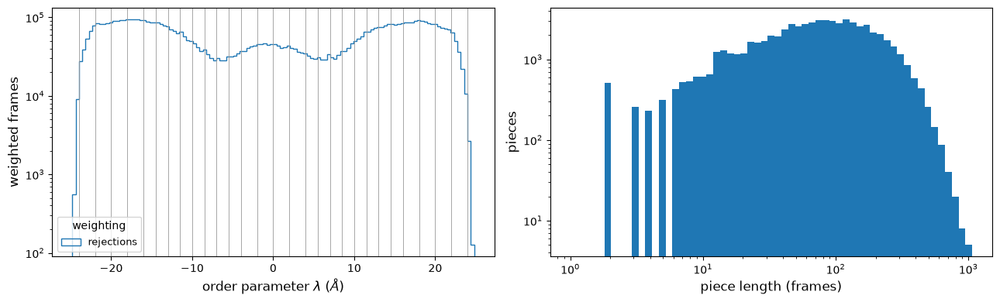

In [6]:
def select_cvs(data):
    """Names of the fit CVs: the columns of order.txt that are not excluded and not constant."""
    n_col = data.X_all.shape[1]
    if n_col != len(CV_NAMES):
        raise SystemExit(f'order.txt has {n_col} columns after the time but CV_NAMES has {len(CV_NAMES)}: edit CV_NAMES in the settings')
    fr = ~(data.boundary0 | data.boundary1)
    names = []
    for j, n in enumerate(CV_NAMES):
        if n in CV_EXCLUDE:
            continue
        if np.ptp(data.X_all[fr, j]) == 0:
            print(f'dropping the constant column {n}')
            continue
        names.append(n)
    return names


def prepare(weighting):
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--burn-in-fraction', str(BURN_IN_FRACTION), '--thin', str(THIN)]
    if weighting is not None:
        argv += ['--weights', weighting]
    if H5_FILE is not None:
        argv += ['--h5', H5_FILE]
    if LAMBDA_A is not None:
        argv += ['--lambda-a', str(LAMBDA_A)]
    if LAMBDA_B is not None:
        argv += ['--lambda-b', str(LAMBDA_B)]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE)]
    if REVERSED:
        argv += ['--reversed']
    args = parser.parse_args(argv)
    data = tis_data.prepare_data(args)
    data.cv_names = select_cvs(data)
    data.X = data.X_all[:, [CV_NAMES.index(n) for n in data.cv_names]]    # the CVs of the fit (X_all keeps every column of order.txt)
    return args.weights, args.lambda_a, args.lambda_b, data     # the weighting actually used


# None = the run's default (section 3); the same weighting twice is fitted once
names = list(dict.fromkeys(w if w is not None else default_w for w in WEIGHTINGS))
datas = {}
for weighting in names:
    name, lambda_a, lambda_b, data = prepare(weighting)
    datas[name] = data
    print(f'--> {name}: {len(data.lam)} frames, {data.i_traj.max() + 1} pieces, '
          f'{len(np.unique(data.group_traj))} paths\n')
data = next(iter(datas.values()))  # the frames are the same for every weighting
print(f'fit CVs ({data.X.shape[1]}): ' + (', '.join(data.cv_names) if hasattr(data, 'cv_names') else f'{data.X.shape[1]} column(s) of order.txt'))
free = ~(data.boundary0 | data.boundary1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
e_lam = np.linspace(data.lam.min(), data.lam.max(), 121)
for name, d in datas.items():
    ax1.hist(d.lam, bins=e_lam, weights=d.path_weights, histtype='step', label=name)
for v in settings['interfaces']:
    ax1.axvline(v, color='0.6', lw=0.6)
ax1.set(xlabel=LABEL, ylabel='weighted frames', yscale='log')
ax1.legend(title='weighting')
lengths = np.bincount(data.i_traj)
ax2.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax2.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces')
fig.tight_layout()
plt.show()

## 5. Exact Committor

None: there is no reference for an explicit-solvent MD system (the exact committor of the toy systems comes from the engine's discrete chain, which is known there). `q_exact_of = None` makes the fit skip the RMS against the exact committor; the plots then show only the fit.


In [7]:
q_exact_of = None


## 6. Fit the Committor

One fit per weighting (and per seed in `SEEDS`), on the same frames. `CommittorNE` with `group_traj` (the pieces of one path count as one unit in the error estimates), the **A/B ends as traps** (`set_fixed_traj_length_trap`: longer than any piece plus the longest Z_q lag, so no window is dropped), and the **stopped ends** (`set_stopped_traj_end`, `STOPPED_ENDS`): a piece that ends outside A and B was stopped by the path's own end (a turn), so a window that passes it uses q at that end instead of being dropped, which would condition on the path not stopping earlier.

The first cell defines the plots, the progress line and the piece ends; the second builds the committor, runs `fit_transform` for the warm-up (wide envelope) and then in chunks of `CHUNK` iterations (it continues from the current q), and `seed_runs.save_and_show` shows and saves after the warm-up and every chunk as `<OUT>/<weighting>/seed<s>/it<N>_<plot>.png`:
- `metrics`: `dr2`, `zqs_z` and `|dx|` over the iterations. **Convergence: `zqs_z`** (the worst |stopped Z_q / standard error| over q and lags) about 2 or less, with `|dx|` small. For pieces cut at M the stopped Z_q of the committor is 0 at every q and lag (notes §5, §8.1);
- `tis`: the stopped Z_q per lag, the short-lag Z_q and the stopped observed-vs-predicted;
- `feps`, `obs_pred` (if listed in `PLOTS`): the library's original plots, biased for path pieces; with `STOPPED_ENDS` the Z_q of `feps` is the stopped one;
- `q_profile`: the path-weighted mean q per λ bin next to the exact committor, and fit − exact;

The progress line gives the path-weighted RMS(fit − exact) over the frames with 0.05 < q_exact < 0.95. Each weighting's final q per frame is kept in `fits` for section 7.

In [8]:
def edges_for(d):
    return (np.linspace(lambda_a, lambda_b, N_BINS + 1),)


def extras_for(d, qe):
    # q -> figure: the path-weighted mean q per lambda bin, against the exact committor
    edges = edges_for(d)
    fr = ~(d.boundary0 | d.boundary1)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    mid = (edges[0][1:] + edges[0][:-1]) / 2
    prof_ex = None if qe is None else bm(d.path_weights * qe) / w_mean

    def q_profile(q):
        P = bm(d.path_weights * cp.asnumpy(q.r_traj)) / w_mean
        fig, axes = plt.subplots(1, 1 if qe is None else 2, figsize=(6 if qe is None else 13, 4), squeeze=False)
        axes[0, 0].plot(mid, P, label='fit')
        if qe is not None:
            axes[0, 0].plot(mid, prof_ex, 'k--', label='exact')
            t = (prof_ex > 0.05) & (prof_ex < 0.95)
            axes[0, 1].plot(mid, P - prof_ex)
            axes[0, 1].axhline(0, color='k', lw=0.8)
            axes[0, 1].set(xlabel=XLABEL, ylabel='fit $-$ exact',
                           title=f'RMS per bin (0.05 < exact < 0.95) {np.sqrt(np.nanmean((P - prof_ex)[t] ** 2)):.4f}')
            axes[0, 1].grid(alpha=0.3)
        axes[0, 0].set(xlabel=XLABEL, ylabel='$q$ (mean per bin)')
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        fig.tight_layout()
        return fig

    extras = {'q_profile': q_profile}
    return extras


def report_for(d, qe):
    # progress line: path-weighted RMS(fit - exact) over the frames with 0.05 < q_exact < 0.95
    if qe is None:
        return None
    trans = ~(d.boundary0 | d.boundary1) & (qe > 0.05) & (qe < 0.95)
    idx, qe_g, w_g = (cp.asarray(a) for a in (np.flatnonzero(trans), qe[trans], d.path_weights[trans]))

    def report(q):
        diff = q.r_traj[idx] - qe_g
        return f'| RMS(fit - exact) {float(cp.sqrt(cp.sum(w_g * diff * diff) / cp.sum(w_g))):.4f}'
    return report


XLABEL = LABEL
MAX_ITER = ITER_PER_CV * data.X.shape[1]            # the main fit: ITER_PER_CV iterations per CV
print(f'fit with {data.X.shape[1]} CVs: {WARMUP_ITER} warm-up + {MAX_ITER} main iterations')

# ---- piece ends: in A or B (trap), or stopped by the path's own end, a turn (stopped end)
# (the frames are the same for every weighting, so this is done once)
b_all = data.boundary0 | data.boundary1
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(data.i_traj) - 1]      # last frame of every piece
stop_end = np.zeros(len(b_all), bool)
stop_end[piece_end] = ~b_all[piece_end]
longest = int(np.bincount(data.i_traj - data.i_traj.min()).max())
TRAP_LEN = max(2 ** 16, longest + 2 ** 15 + 1)         # A/B trap: longer than any piece plus the longest Z_q lag (2^15)
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn (stopped), {len(piece_end) - stop_end.sum()} in A or B; '
      f'longest piece {longest} frames, A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)    # the metrics are recorded every PRINT_STEP iterations (a plot needs a record)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'delta_x']


def show_stage(q, folder, n_done, stage, extras, report):
    """Save and show the plots after a stage (<folder>/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {"" if report is None else report(q)}', flush=True)


fit with 8 CVs: 2000 warm-up + 32000 main iterations
66874 pieces: 60339 end at a turn (stopped), 6535 in A or B; longest piece 1065 frames, A/B trap 65536


===== fit, weighting rejections, seed 0 =====
#=500, dr2=325.349, zqs_z=9.9448, sdzqs=45.5745, |dx|=0.441773, time=40.0125
#=1000, dr2=331.005, zqs_z=10.8952, sdzqs=40.0743, |dx|=0.0197592, time=63.0613
#=1500, dr2=330.254, zqs_z=10.7989, sdzqs=40.1024, |dx|=0.000533587, time=83.4527
#=2000, dr2=329.946, zqs_z=10.7665, sdzqs=40.0703, |dx|=0.000265376, time=109.15
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it2000 ---


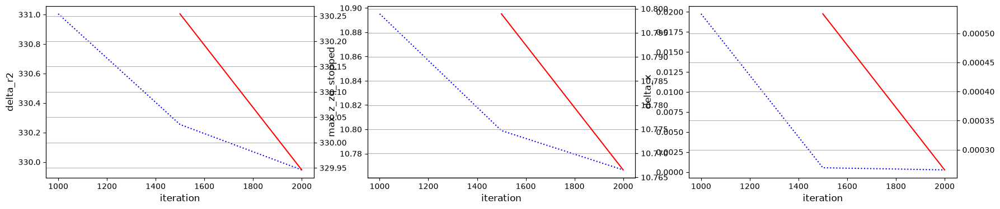

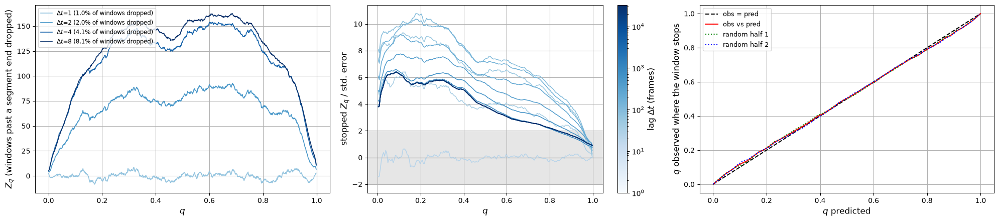

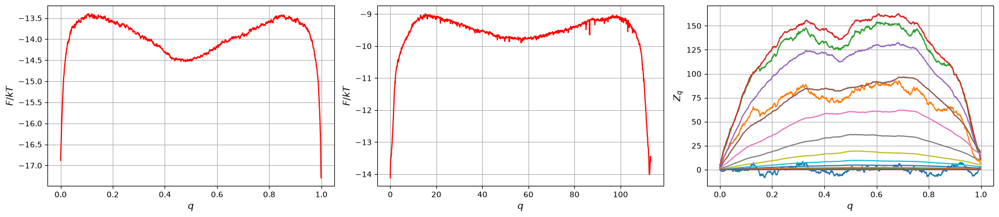

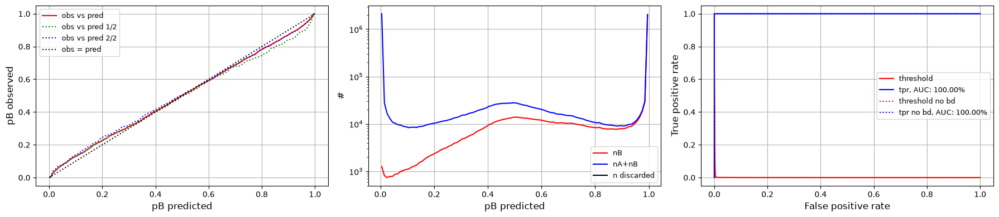

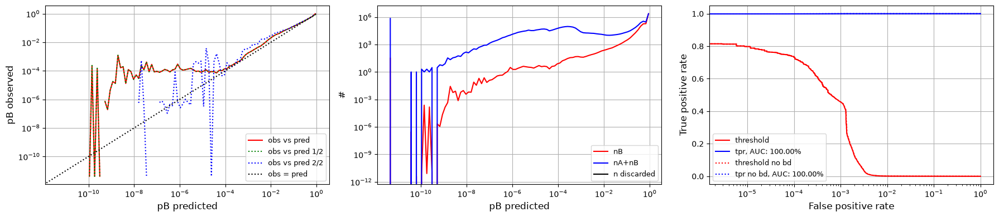

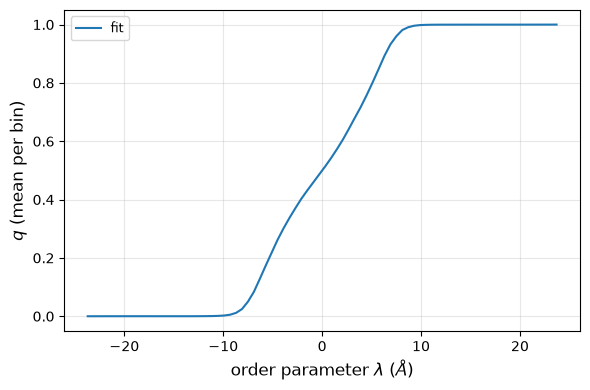

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=330.096, zqs_z=10.7564, sdzqs=39.5721, |dx|=0.00245687, time=22.0678
#=3000, dr2=329.771, zqs_z=10.7229, sdzqs=39.4313, |dx|=0.000721148, time=45.0439
#=3500, dr2=329.801, zqs_z=10.7544, sdzqs=39.3235, |dx|=0.000448628, time=69.2778
#=4000, dr2=329.846, zqs_z=10.7294, sdzqs=39.2358, |dx|=0.000424994, time=91.5584
#=4500, dr2=329.904, zqs_z=10.7374, sdzqs=39.2555, |dx|=0.00019468, time=114.982
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it4500 ---


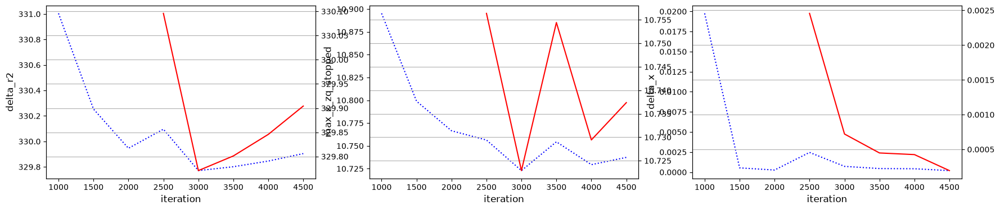

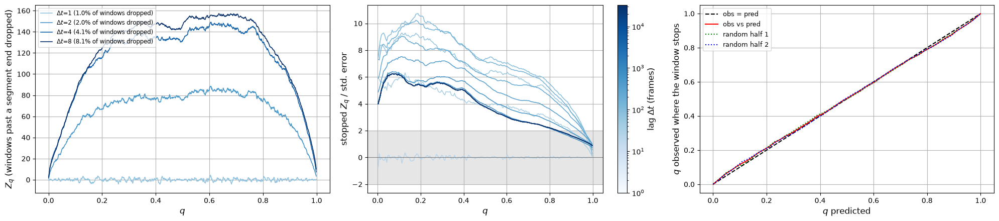

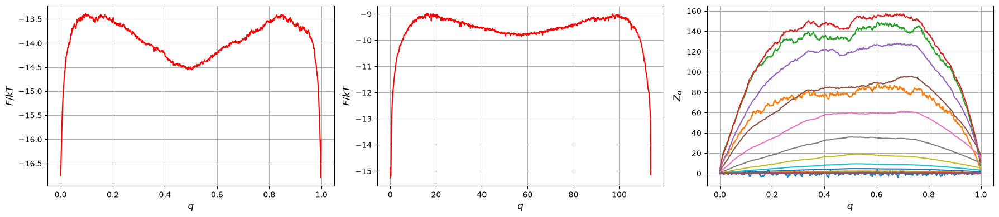

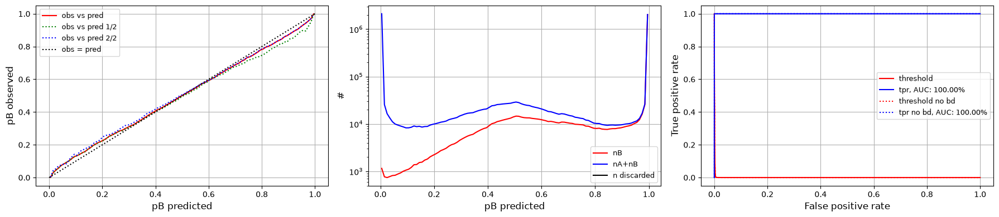

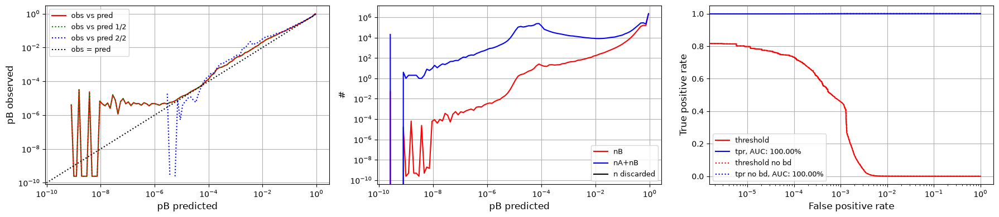

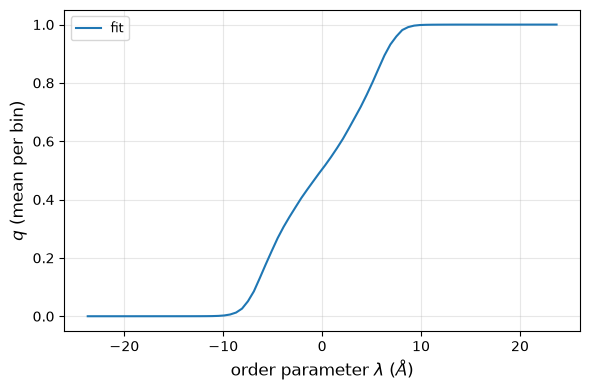

4500 iterations (main, envelope 0.01) 
#=5000, dr2=329.988, zqs_z=10.7365, sdzqs=39.2618, |dx|=0.000211337, time=22.1862
#=5500, dr2=329.983, zqs_z=10.732, sdzqs=39.247, |dx|=0.000198984, time=45.19
#=6000, dr2=329.98, zqs_z=10.7317, sdzqs=39.2989, |dx|=0.0001901, time=68.2553
#=6500, dr2=330.091, zqs_z=10.7592, sdzqs=39.2948, |dx|=0.00017064, time=91.4014
#=7000, dr2=330.024, zqs_z=10.7245, sdzqs=39.2636, |dx|=0.000144023, time=114.714
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it7000 ---


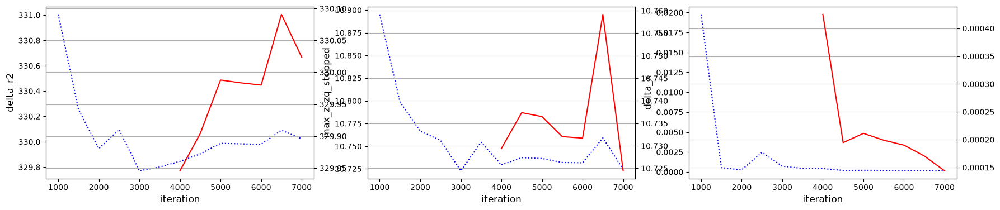

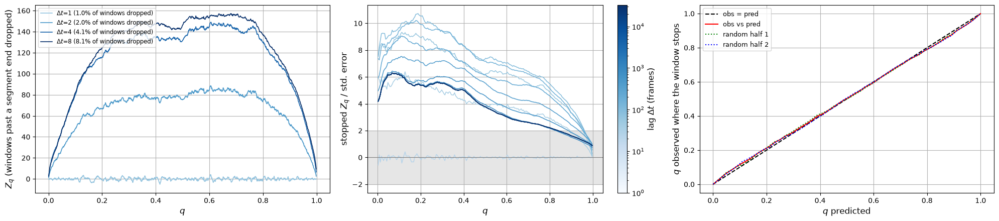

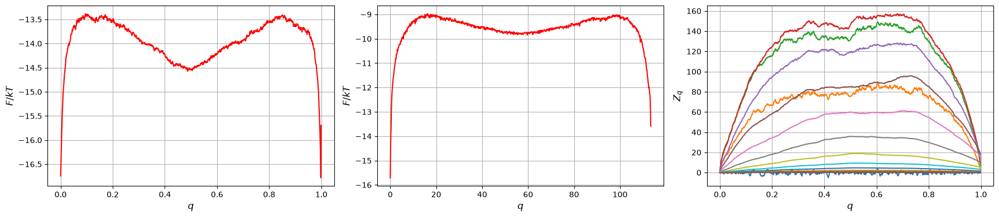

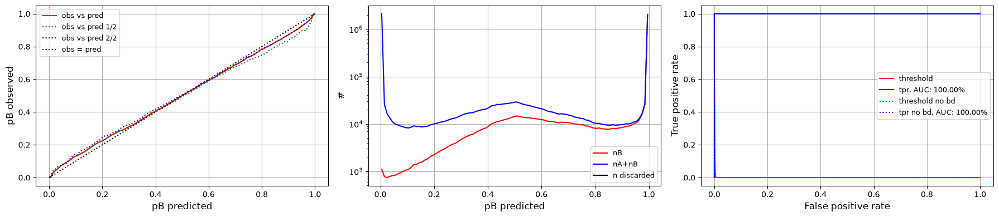

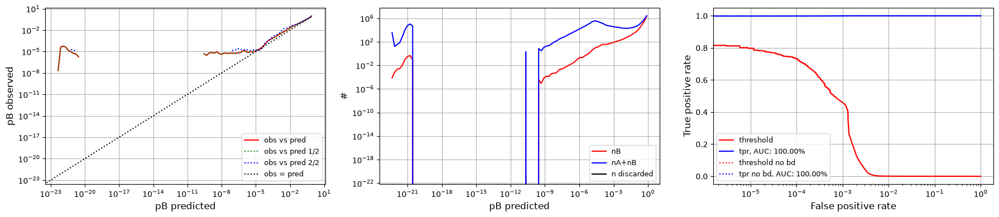

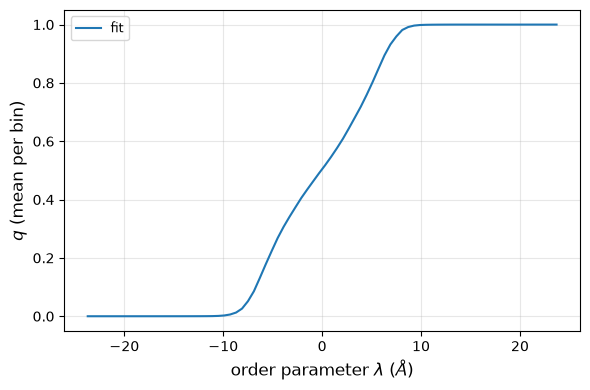

7000 iterations (main, envelope 0.01) 
#=7500, dr2=330.006, zqs_z=10.7612, sdzqs=39.2545, |dx|=0.00011005, time=23.4452
#=8000, dr2=330.014, zqs_z=10.7561, sdzqs=39.2633, |dx|=0.000100868, time=46.8182
#=8500, dr2=330.025, zqs_z=10.7572, sdzqs=39.2627, |dx|=0.000101189, time=70.358
#=9000, dr2=330.022, zqs_z=10.7565, sdzqs=39.2839, |dx|=0.000131859, time=93.5634
#=9500, dr2=330.071, zqs_z=10.7189, sdzqs=39.2839, |dx|=0.000126972, time=113.523
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it9500 ---


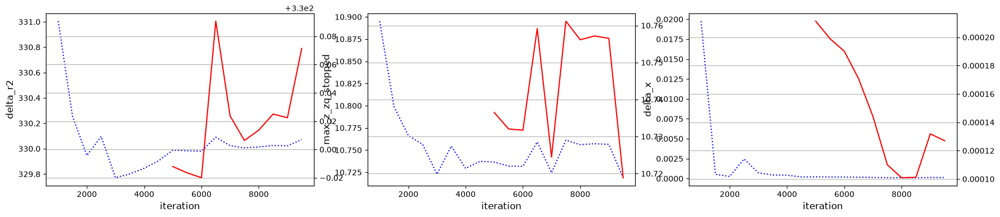

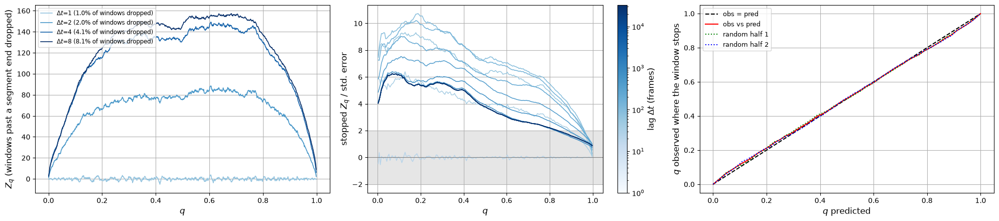

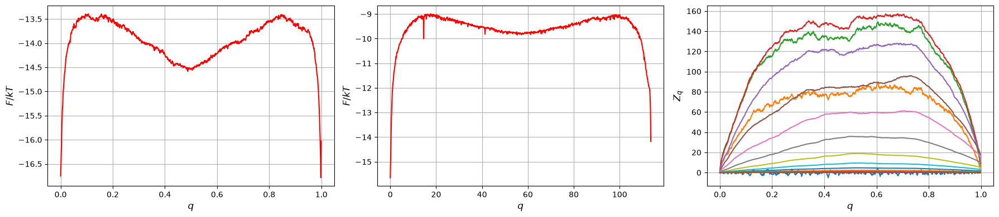

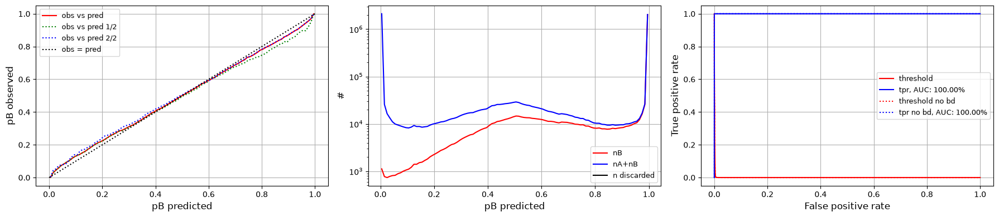

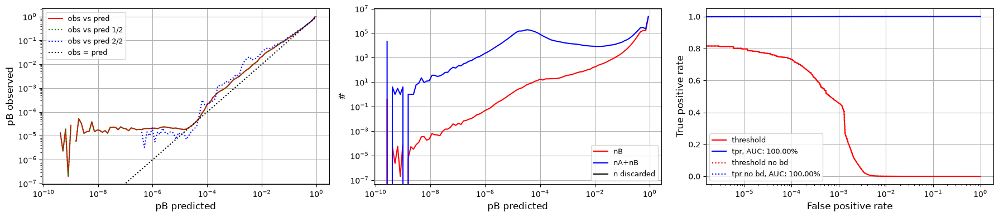

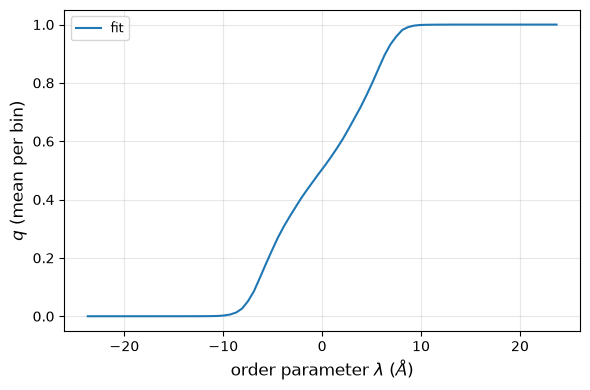

9500 iterations (main, envelope 0.01) 
#=10000, dr2=330.082, zqs_z=10.7413, sdzqs=39.2861, |dx|=0.000128492, time=21.7057
#=10500, dr2=330.102, zqs_z=10.7147, sdzqs=39.2696, |dx|=8.45376e-05, time=43.7173
#=11000, dr2=330.162, zqs_z=10.7312, sdzqs=39.2735, |dx|=0.000114595, time=66.8746
#=11500, dr2=330.13, zqs_z=10.7405, sdzqs=39.2623, |dx|=7.28892e-05, time=87.7606
#=12000, dr2=330.153, zqs_z=10.7564, sdzqs=39.2685, |dx|=8.13053e-05, time=108.066
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it12000 ---


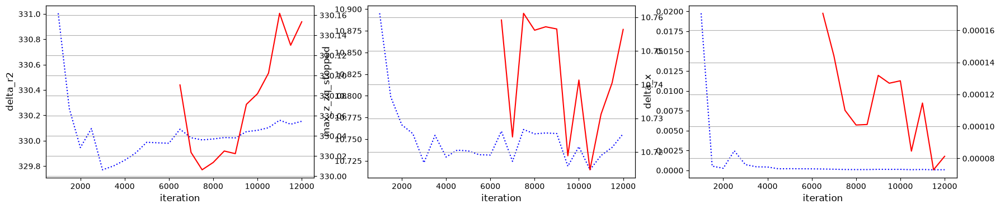

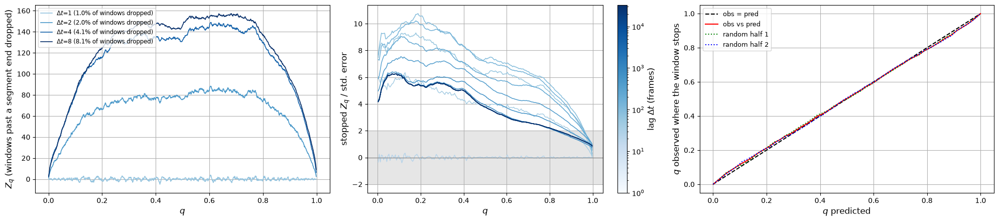

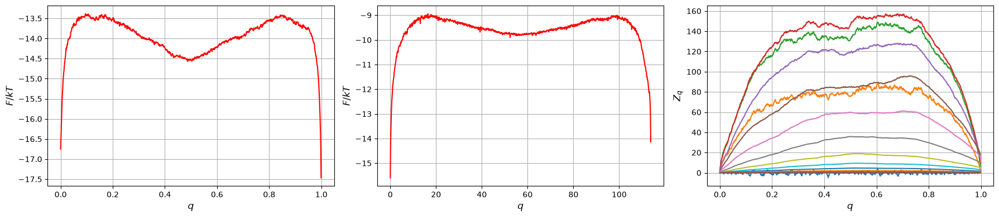

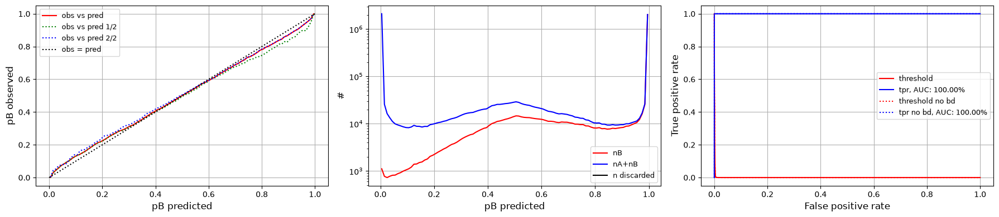

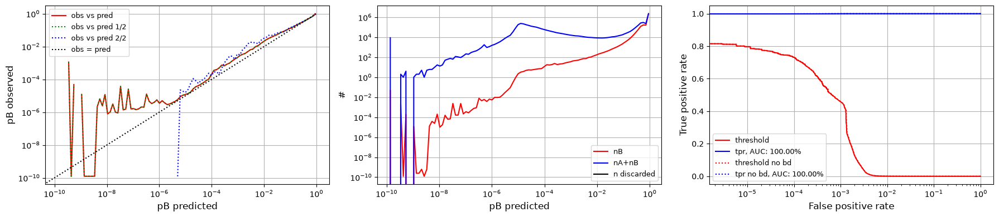

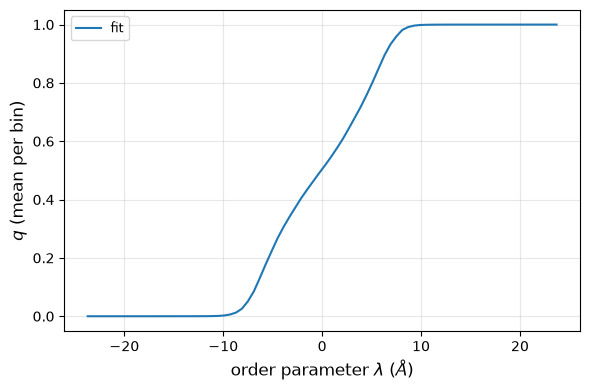

12000 iterations (main, envelope 0.01) 
#=12500, dr2=330.17, zqs_z=10.758, sdzqs=39.2663, |dx|=8.12662e-05, time=22.9043
#=13000, dr2=330.169, zqs_z=10.725, sdzqs=39.2365, |dx|=9.20248e-05, time=44.7547
#=13500, dr2=330.16, zqs_z=10.7244, sdzqs=39.2644, |dx|=8.60141e-05, time=67.9097
#=14000, dr2=330.185, zqs_z=10.745, sdzqs=39.2582, |dx|=8.94531e-05, time=98.0044
#=14500, dr2=330.17, zqs_z=10.7423, sdzqs=39.2516, |dx|=7.26102e-05, time=125.044
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it14500 ---


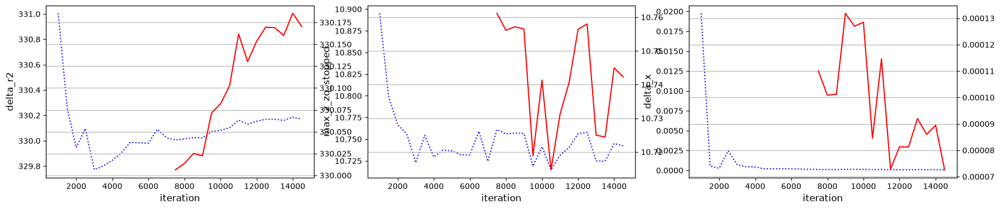

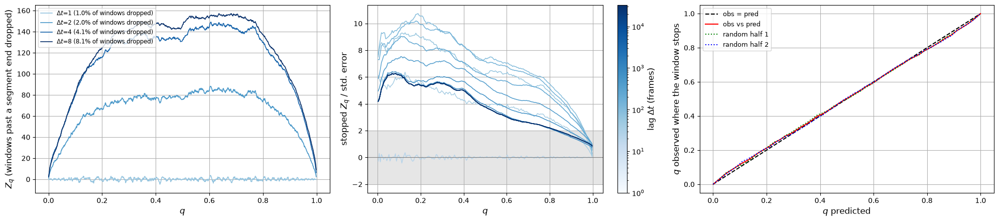

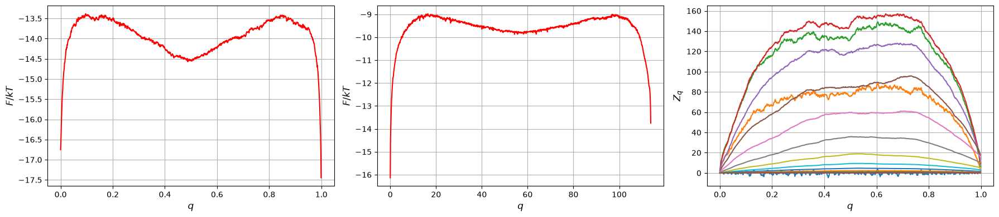

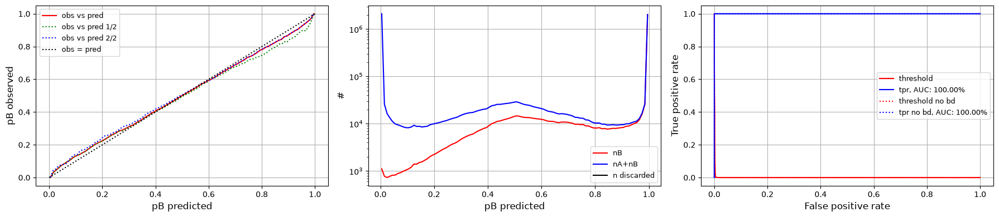

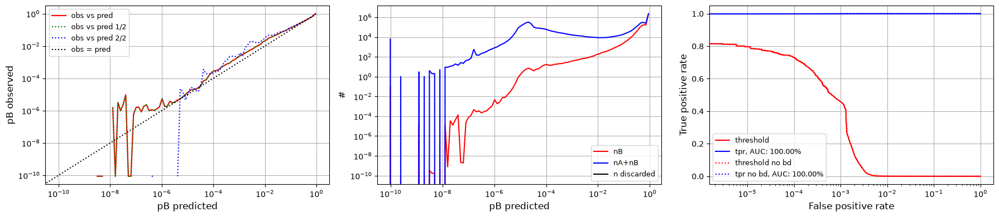

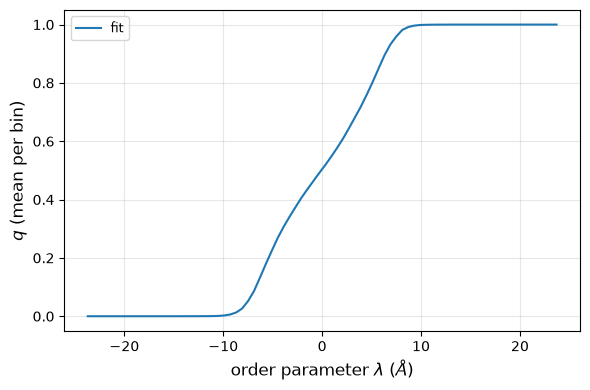

14500 iterations (main, envelope 0.01) 
#=15000, dr2=330.209, zqs_z=10.7456, sdzqs=39.2449, |dx|=7.68018e-05, time=27.7213
#=15500, dr2=330.196, zqs_z=10.7544, sdzqs=39.2213, |dx|=9.2901e-05, time=55.6395
#=16000, dr2=330.182, zqs_z=10.7452, sdzqs=39.2292, |dx|=7.93189e-05, time=80.7684
#=16500, dr2=330.24, zqs_z=10.757, sdzqs=39.2331, |dx|=7.23713e-05, time=108.758
#=17000, dr2=330.257, zqs_z=10.7535, sdzqs=39.2006, |dx|=7.24083e-05, time=135.941
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it17000 ---


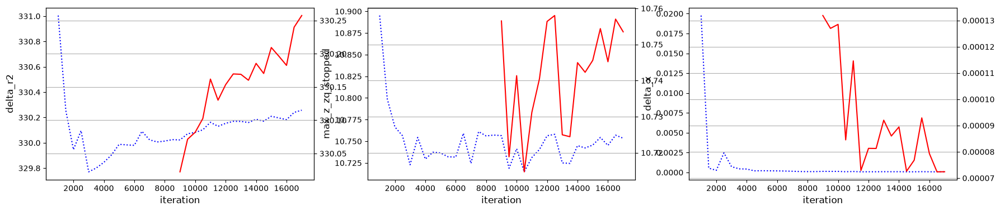

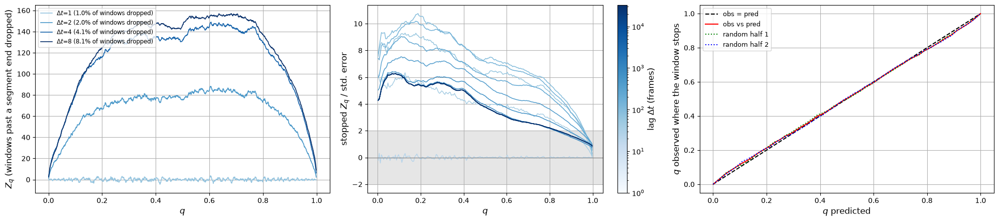

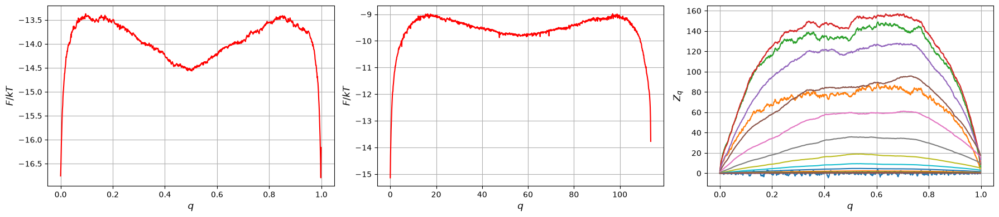

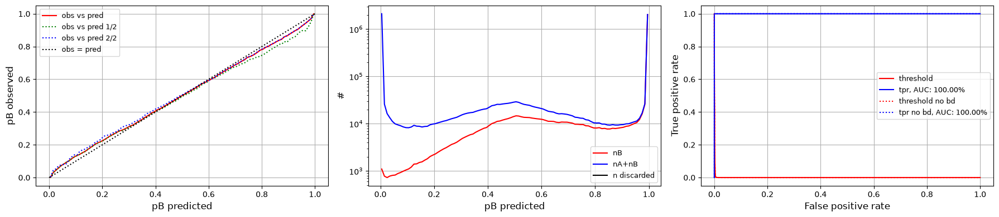

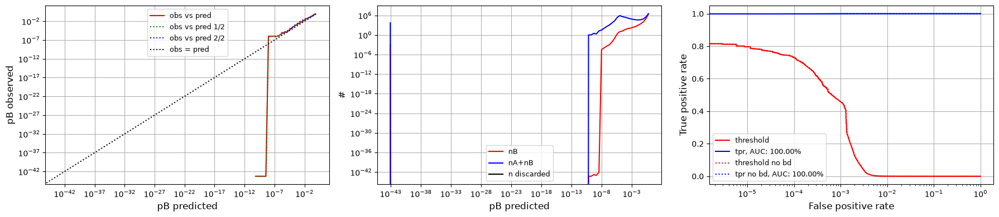

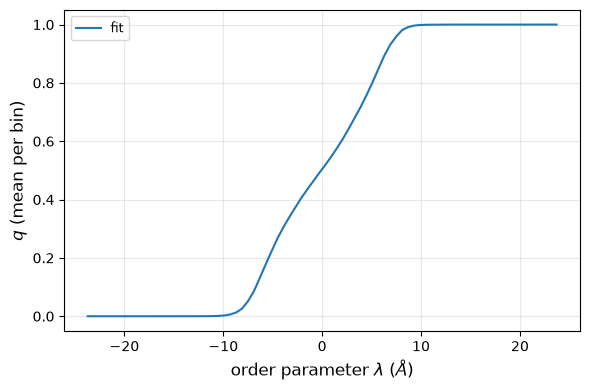

17000 iterations (main, envelope 0.01) 
#=17500, dr2=330.302, zqs_z=10.7463, sdzqs=39.2126, |dx|=6.99701e-05, time=26.5943
#=18000, dr2=330.258, zqs_z=10.7548, sdzqs=39.199, |dx|=6.35675e-05, time=49.665
#=18500, dr2=330.297, zqs_z=10.7304, sdzqs=39.2338, |dx|=6.67349e-05, time=76.5254
#=19000, dr2=330.301, zqs_z=10.7302, sdzqs=39.22, |dx|=5.56684e-05, time=103.562
#=19500, dr2=330.312, zqs_z=10.734, sdzqs=39.2049, |dx|=5.83331e-05, time=134.068
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it19500 ---


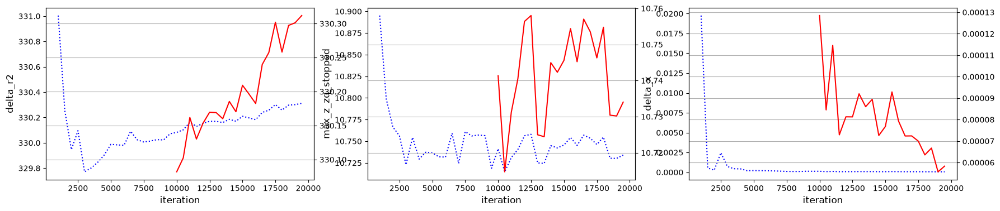

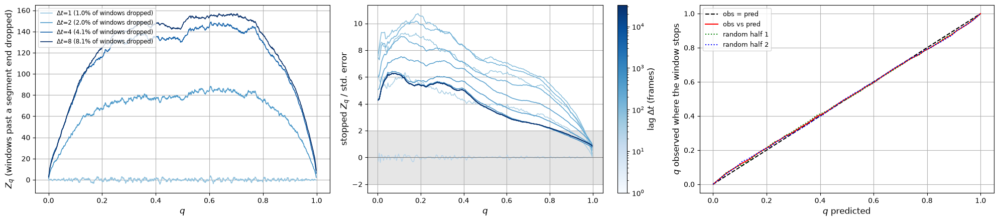

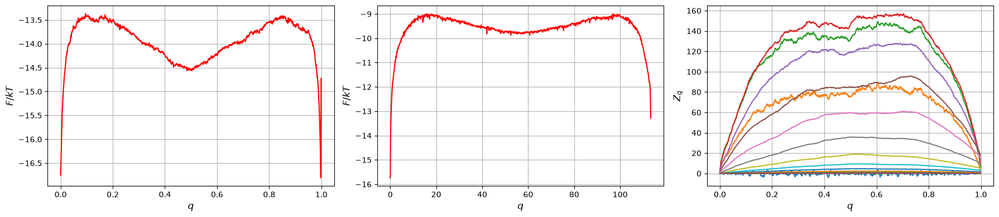

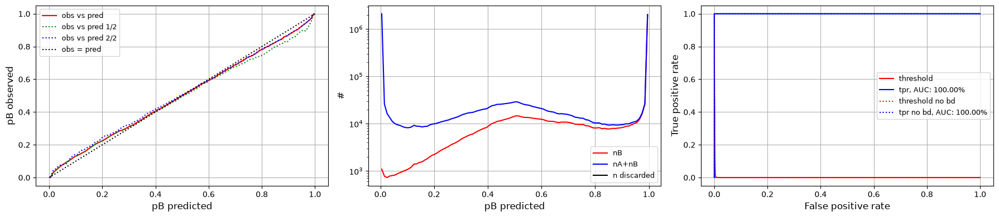

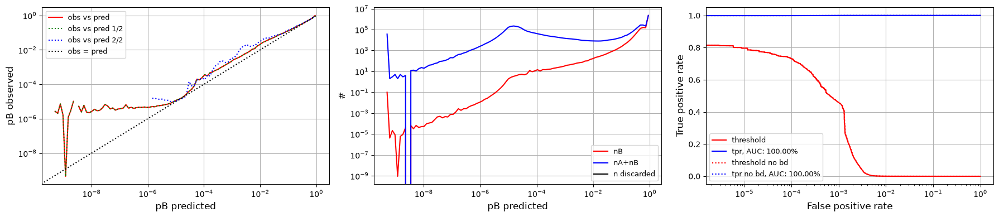

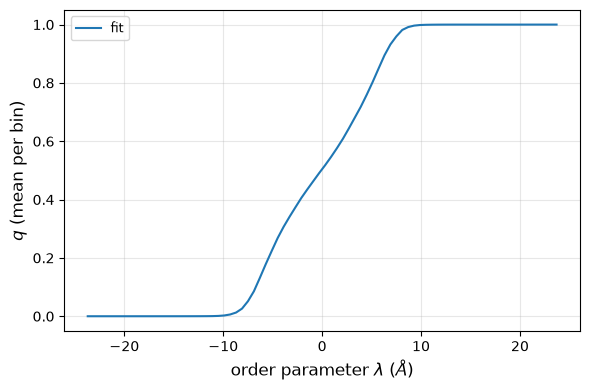

19500 iterations (main, envelope 0.01) 
#=20000, dr2=330.293, zqs_z=10.7583, sdzqs=39.2055, |dx|=9.52411e-05, time=23.5875
#=20500, dr2=330.297, zqs_z=10.7573, sdzqs=39.1966, |dx|=5.79233e-05, time=50.1671
#=21000, dr2=330.291, zqs_z=10.7693, sdzqs=39.2251, |dx|=5.02845e-05, time=78.1342
#=21500, dr2=330.302, zqs_z=10.7441, sdzqs=39.1935, |dx|=4.76604e-05, time=104.921
#=22000, dr2=330.281, zqs_z=10.7551, sdzqs=39.2137, |dx|=6.21341e-05, time=131.006
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it22000 ---


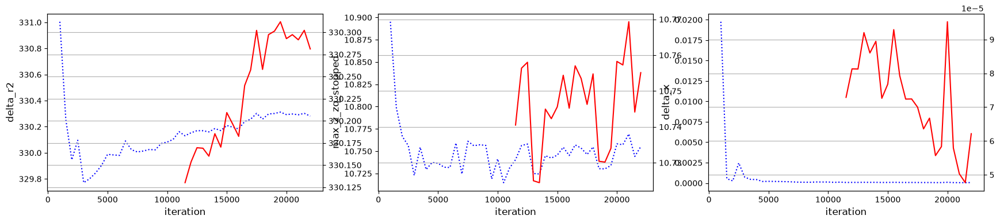

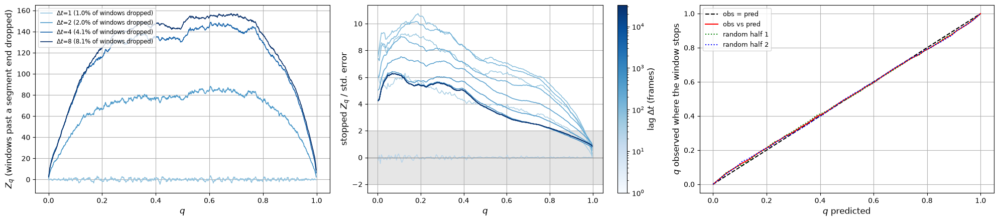

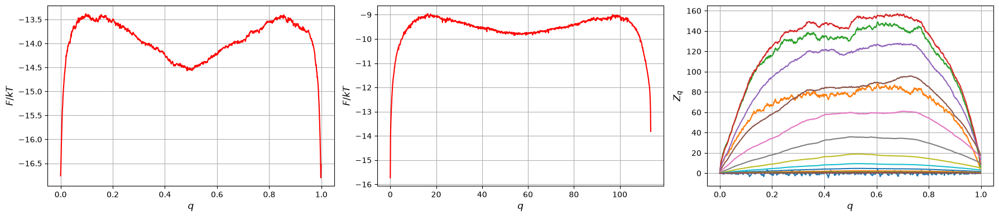

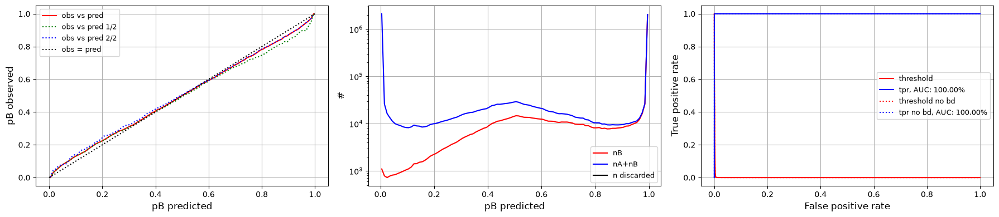

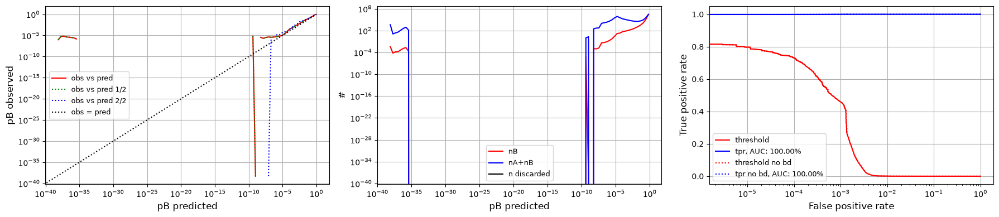

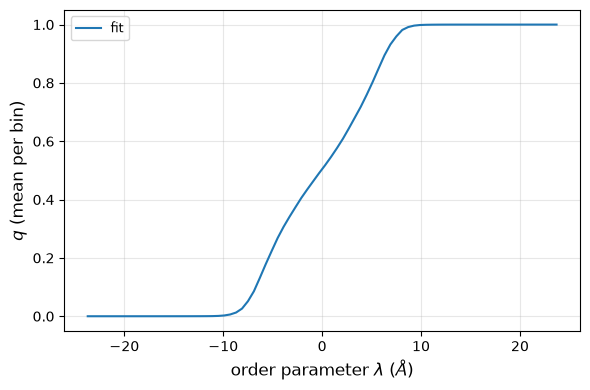

22000 iterations (main, envelope 0.01) 
#=22500, dr2=330.287, zqs_z=10.7501, sdzqs=39.1945, |dx|=4.43209e-05, time=20.9587
#=23000, dr2=330.301, zqs_z=10.7609, sdzqs=39.1841, |dx|=3.30549e-05, time=41.7662
#=23500, dr2=330.3, zqs_z=10.7612, sdzqs=39.1914, |dx|=4.29622e-05, time=64.1727
#=24000, dr2=330.32, zqs_z=10.7499, sdzqs=39.1881, |dx|=6.59756e-05, time=87.5433
#=24500, dr2=330.336, zqs_z=10.7522, sdzqs=39.189, |dx|=3.74132e-05, time=109.838
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it24500 ---


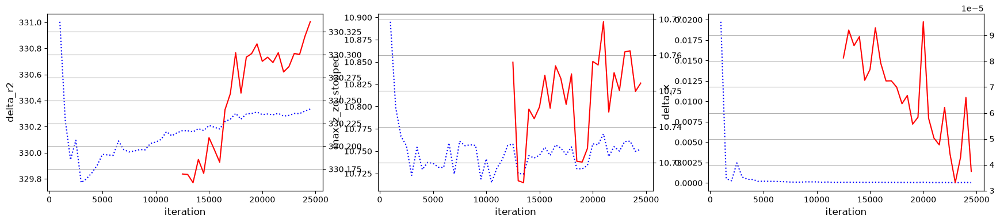

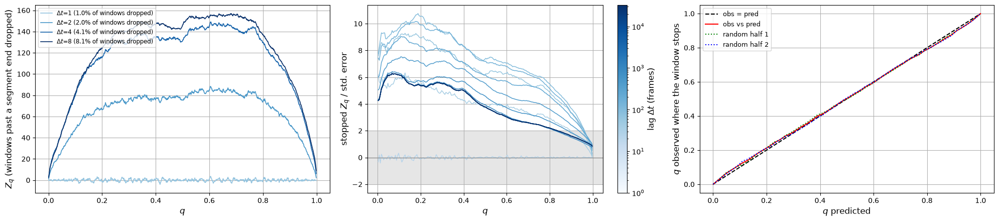

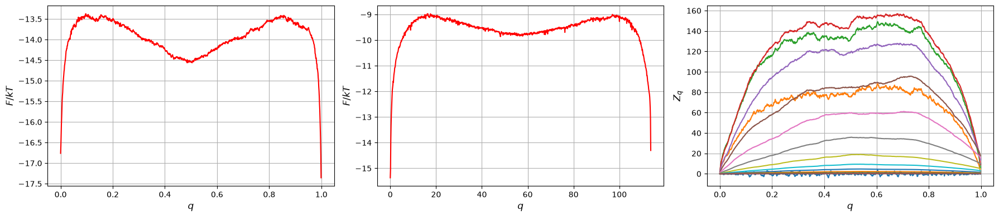

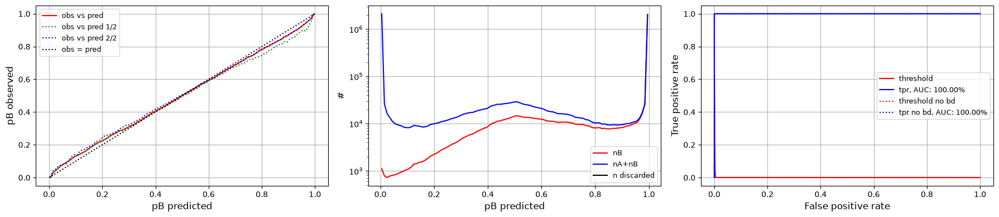

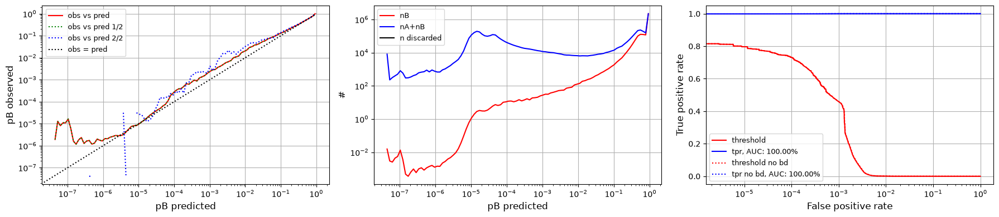

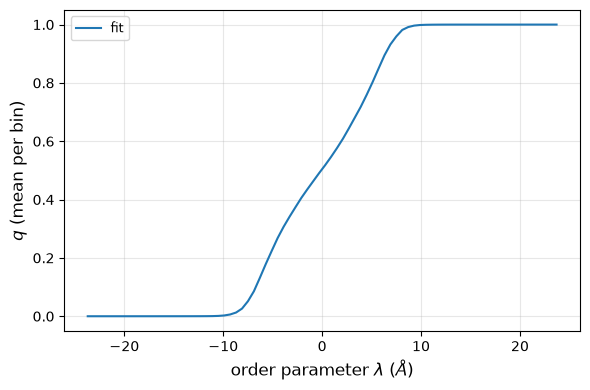

24500 iterations (main, envelope 0.01) 
#=25000, dr2=330.336, zqs_z=10.7566, sdzqs=39.2011, |dx|=4.71019e-05, time=22.3828
#=25500, dr2=330.344, zqs_z=10.7544, sdzqs=39.1849, |dx|=3.78959e-05, time=42.2762
#=26000, dr2=330.348, zqs_z=10.7531, sdzqs=39.1762, |dx|=4.03794e-05, time=64.4971
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seed0/it26000 ---


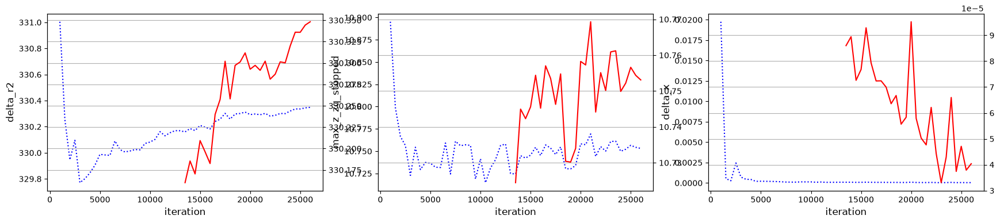

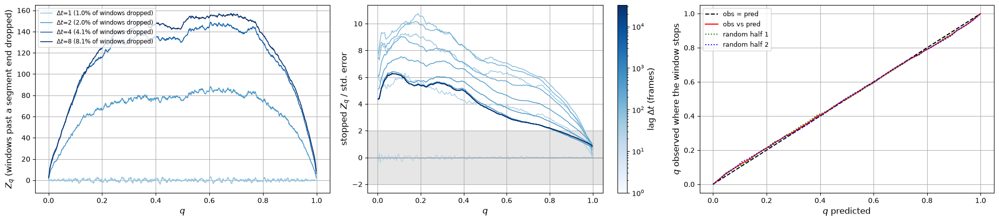

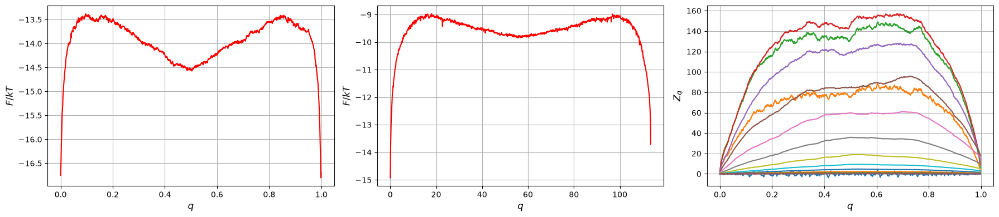

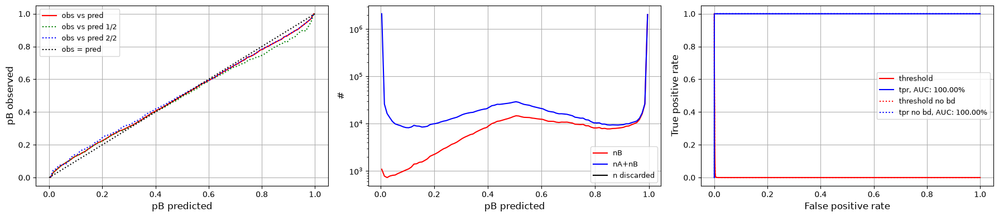

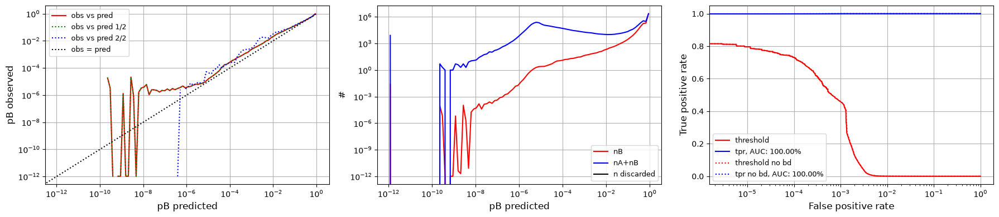

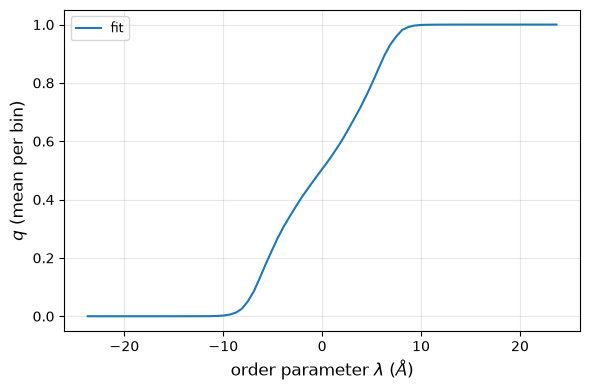

26000 iterations (main, envelope 0.01) 


In [7]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seed{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

===== fit, weighting rejections, seed 0 =====
#=500, dr2=715.129, zqs_z=19.8789, sdzqs=30.3415, |dx|=0.409869, time=23.5911
#=1000, dr2=750.757, zqs_z=14.2934, sdzqs=22.0701, |dx|=0.0155337, time=43.3461
#=1500, dr2=737.821, zqs_z=14.5418, sdzqs=21.4946, |dx|=0.00119456, time=62.8077
#=2000, dr2=738.648, zqs_z=14.5716, sdzqs=21.7198, |dx|=0.000663473, time=86.1973
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it2000 ---


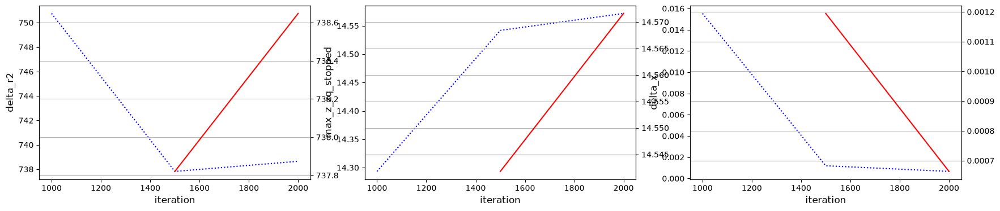

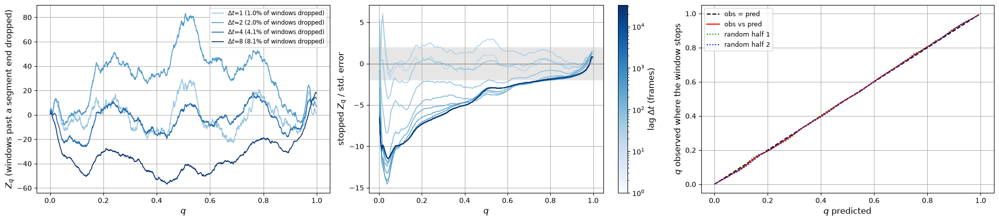

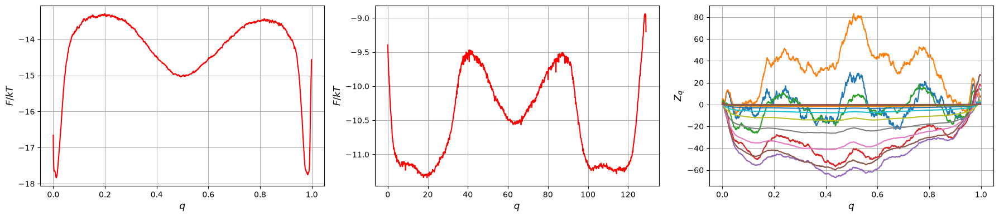

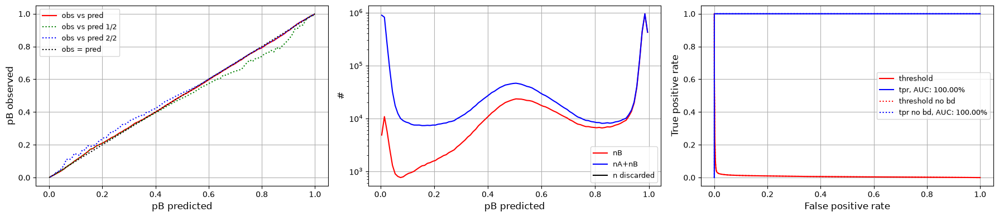

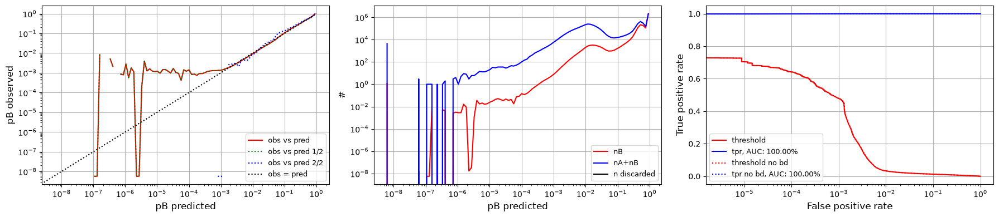

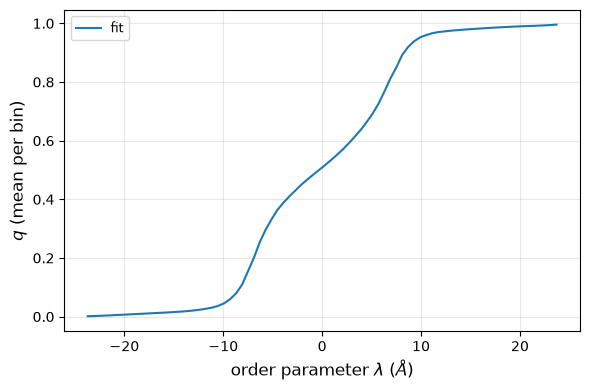

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=749.731, zqs_z=12.9893, sdzqs=19.0008, |dx|=0.00457001, time=23.1597
#=3000, dr2=751.942, zqs_z=12.9788, sdzqs=18.9875, |dx|=0.00133973, time=44.8514
#=3500, dr2=744.261, zqs_z=12.0867, sdzqs=18.321, |dx|=0.00111023, time=64.4877
#=4000, dr2=746.338, zqs_z=12.8234, sdzqs=18.2926, |dx|=0.000854697, time=87.9591
#=4500, dr2=744.451, zqs_z=12.9212, sdzqs=18.0165, |dx|=0.00049501, time=111.283
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it4500 ---


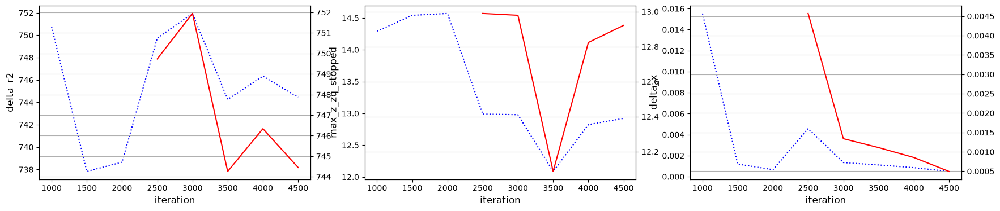

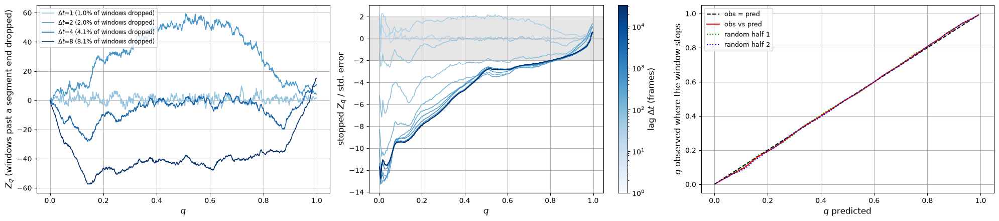

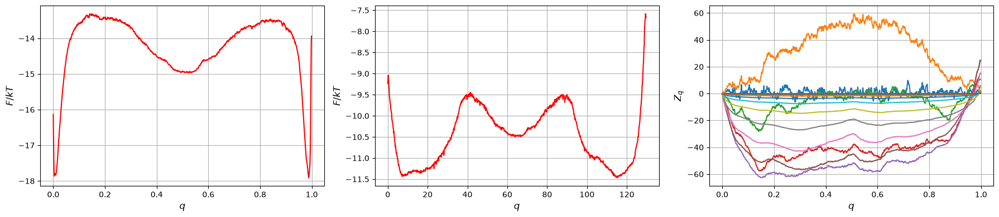

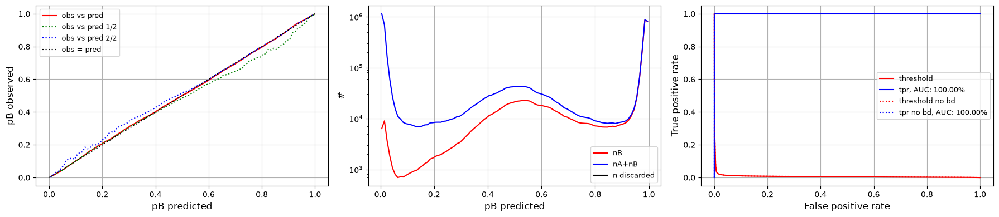

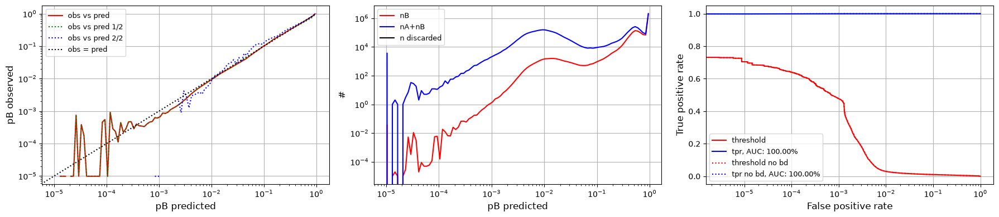

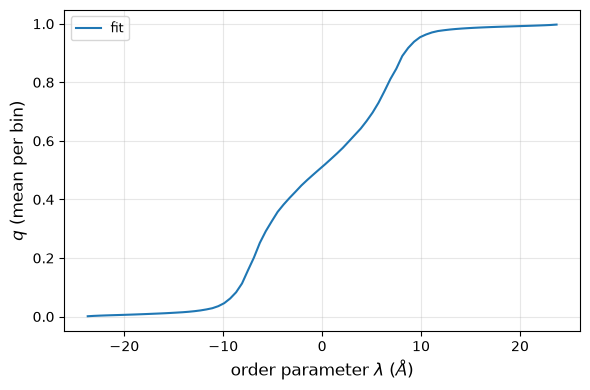

4500 iterations (main, envelope 0.01) 
#=5000, dr2=743.495, zqs_z=12.5318, sdzqs=17.9284, |dx|=0.000870618, time=20.8676
#=5500, dr2=743.973, zqs_z=12.8288, sdzqs=18.3545, |dx|=0.000452589, time=38.6202
#=6000, dr2=743.94, zqs_z=12.4924, sdzqs=18.1484, |dx|=0.000618896, time=61.7122
#=6500, dr2=742.653, zqs_z=12.5039, sdzqs=17.9381, |dx|=0.000366515, time=84.6867
#=7000, dr2=742.848, zqs_z=12.4752, sdzqs=18.0862, |dx|=0.000443317, time=107.507
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it7000 ---


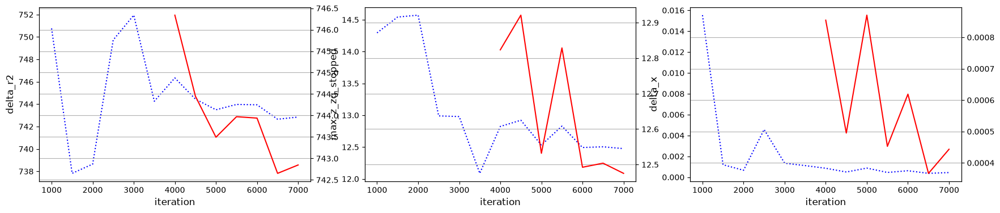

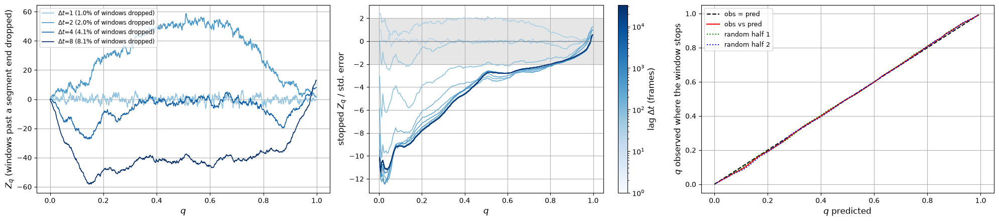

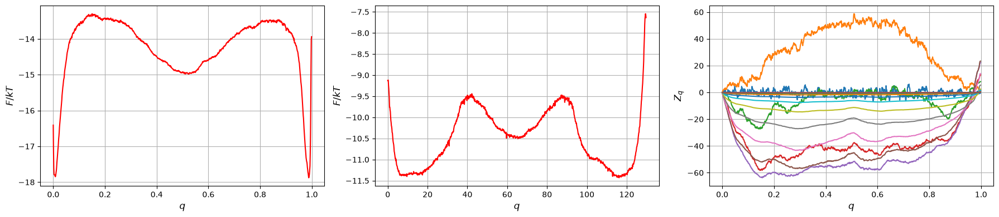

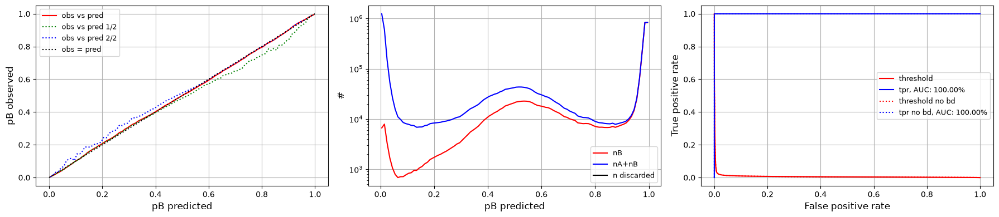

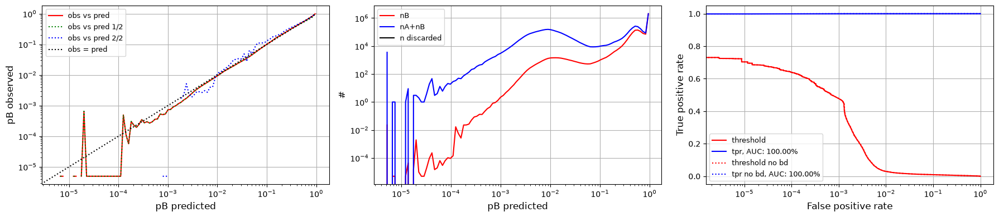

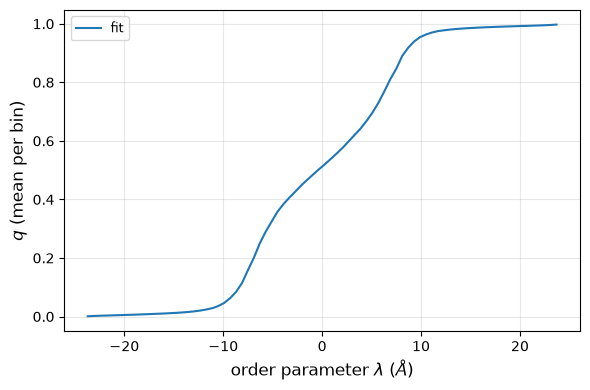

7000 iterations (main, envelope 0.01) 
#=7500, dr2=743.096, zqs_z=12.4678, sdzqs=18.0649, |dx|=0.000357373, time=21.09
#=8000, dr2=742.158, zqs_z=12.3947, sdzqs=18.0769, |dx|=0.000289459, time=43.995
#=8500, dr2=742.531, zqs_z=12.0837, sdzqs=17.8003, |dx|=0.000315535, time=66.6142
#=9000, dr2=741.463, zqs_z=12.6555, sdzqs=17.8979, |dx|=0.000474127, time=89.6716
#=9500, dr2=742.092, zqs_z=12.6244, sdzqs=17.9418, |dx|=0.000296638, time=112.71
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it9500 ---


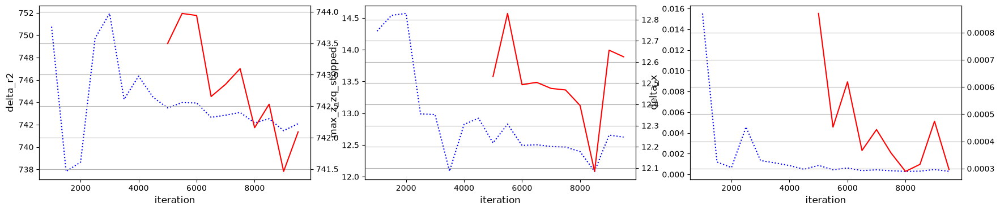

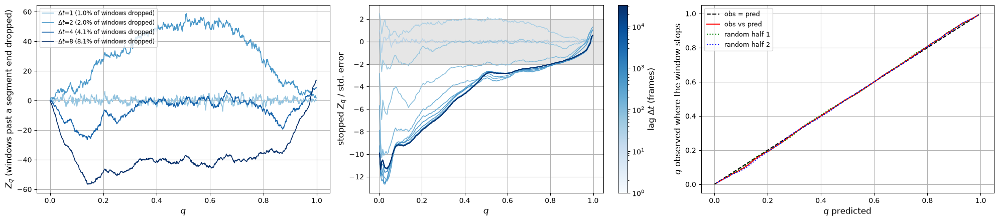

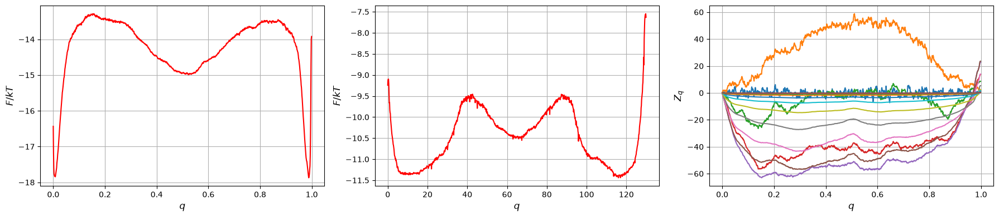

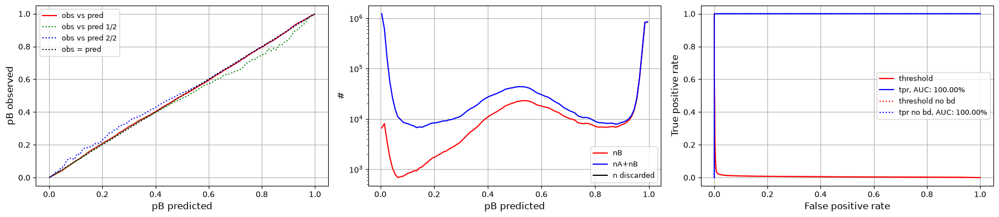

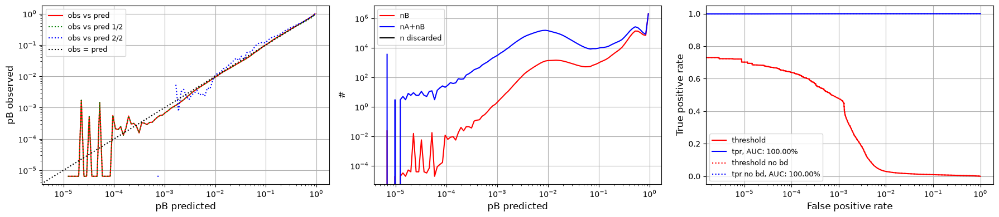

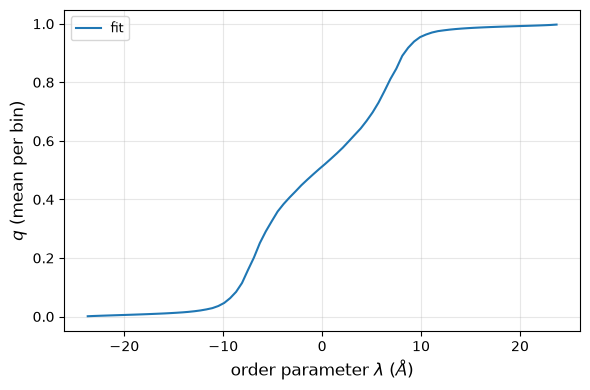

9500 iterations (main, envelope 0.01) 
#=10000, dr2=742.048, zqs_z=12.4563, sdzqs=17.9612, |dx|=0.000327147, time=17.3858
#=10500, dr2=741.783, zqs_z=12.4815, sdzqs=18.0802, |dx|=0.000203052, time=39.8566
#=11000, dr2=741.566, zqs_z=12.7293, sdzqs=18.0713, |dx|=0.000228539, time=62.407
#=11500, dr2=740.513, zqs_z=12.6487, sdzqs=18.043, |dx|=0.000267895, time=84.3725
#=12000, dr2=741.123, zqs_z=12.6008, sdzqs=18.1436, |dx|=0.000225546, time=104.658
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it12000 ---


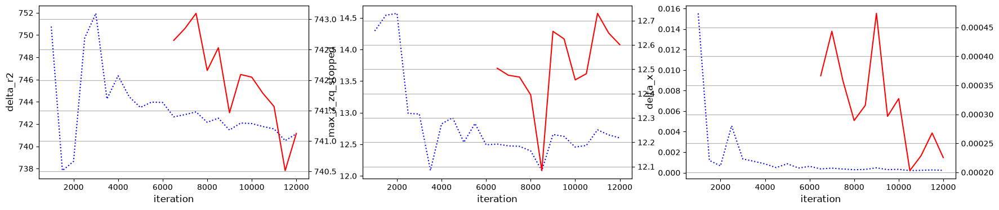

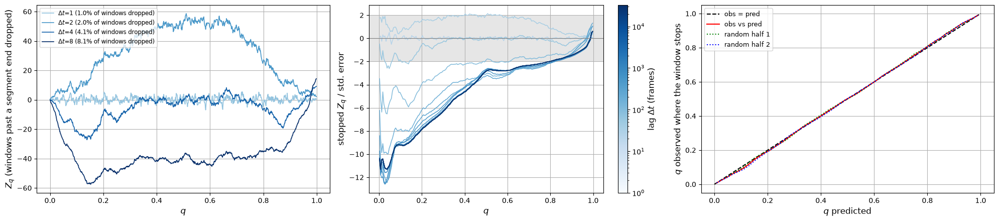

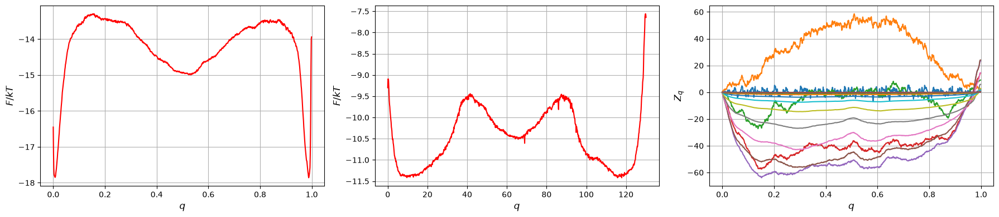

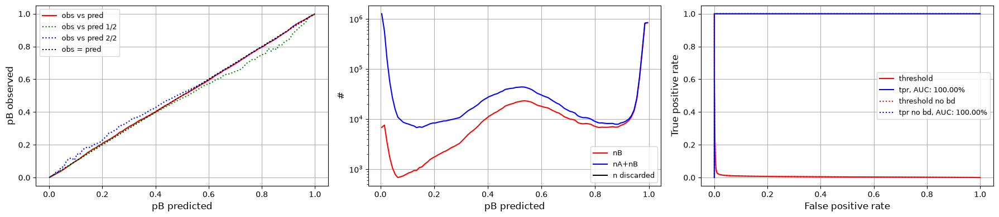

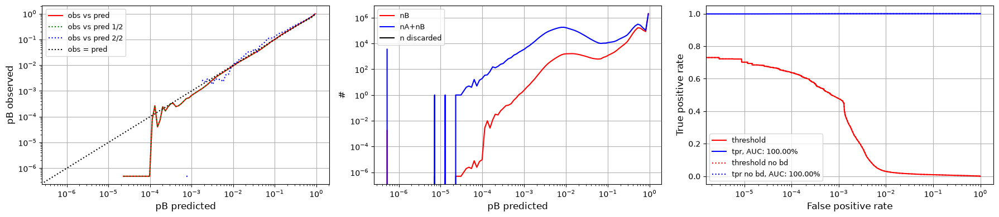

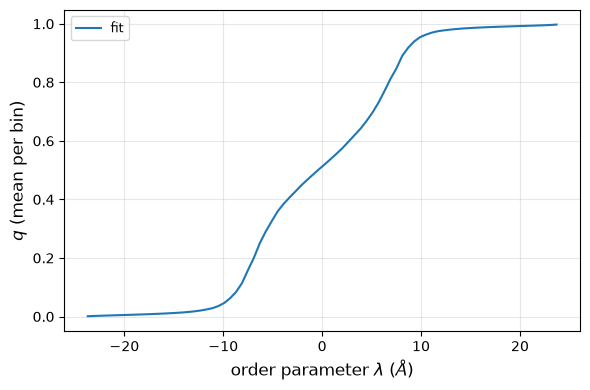

12000 iterations (main, envelope 0.01) 
#=12500, dr2=741.052, zqs_z=12.6591, sdzqs=18.1342, |dx|=0.000194785, time=14.2085
#=13000, dr2=741.035, zqs_z=12.471, sdzqs=18.1056, |dx|=0.000197604, time=28.9902
#=13500, dr2=740.74, zqs_z=12.5452, sdzqs=18.1093, |dx|=0.000232795, time=39.5266
#=14000, dr2=740.56, zqs_z=12.5445, sdzqs=18.0325, |dx|=0.000264762, time=50.7873
#=14500, dr2=740.566, zqs_z=12.5835, sdzqs=18.1142, |dx|=0.000189246, time=62.0299
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it14500 ---


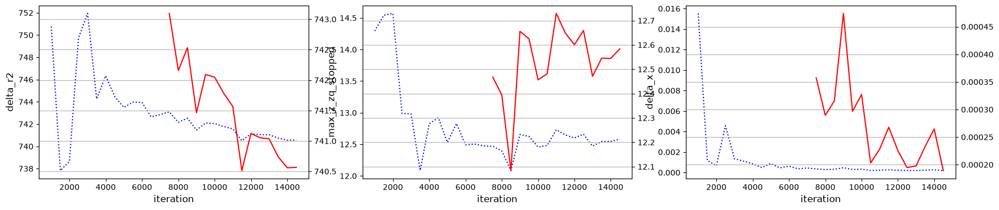

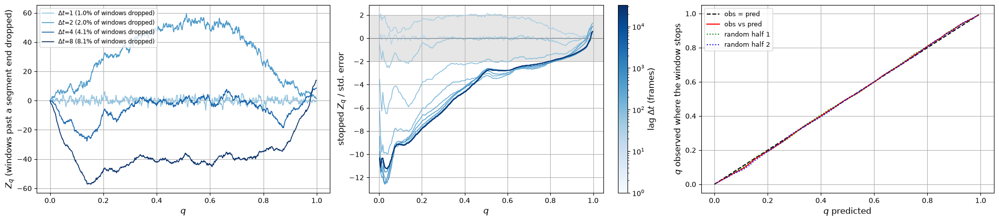

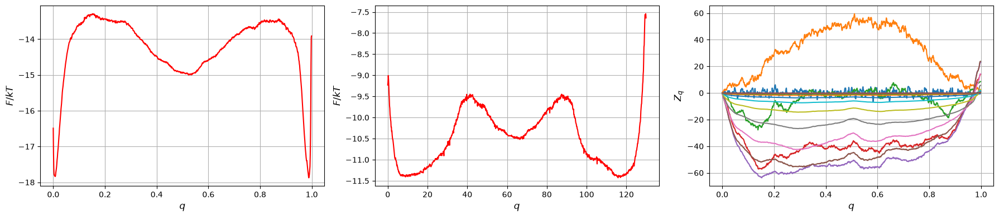

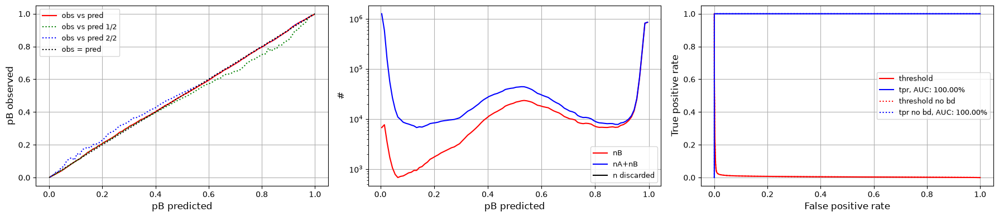

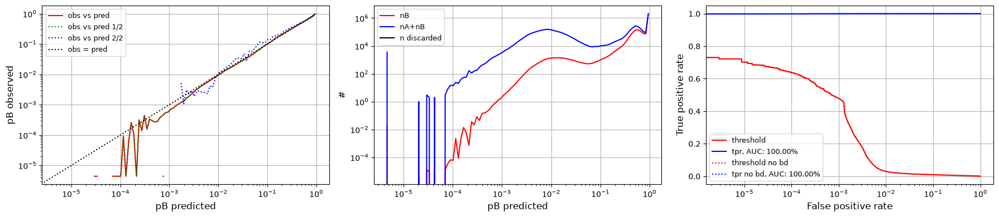

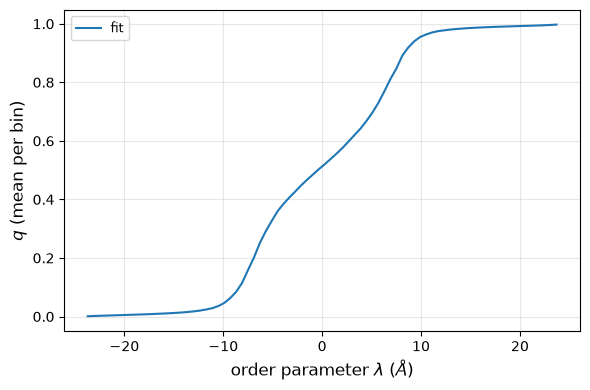

14500 iterations (main, envelope 0.01) 
#=15000, dr2=740.006, zqs_z=12.6874, sdzqs=18.1234, |dx|=0.000290582, time=11.2498
#=15500, dr2=740.892, zqs_z=12.6285, sdzqs=18.0377, |dx|=0.000173056, time=22.5986
#=16000, dr2=741.152, zqs_z=12.7021, sdzqs=18.1621, |dx|=0.000174935, time=33.9505
#=16500, dr2=741.07, zqs_z=12.6747, sdzqs=18.1912, |dx|=0.000119187, time=45.2617
#=17000, dr2=740.843, zqs_z=12.7844, sdzqs=18.1975, |dx|=0.000133683, time=56.5865
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it17000 ---


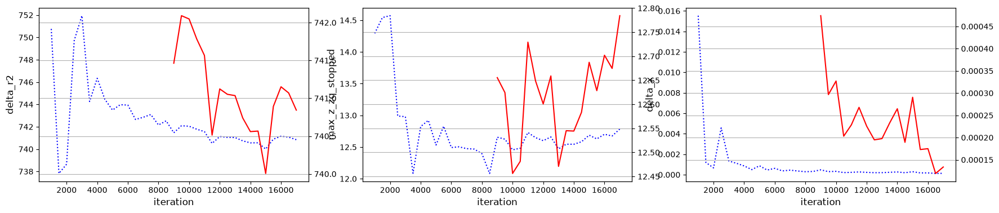

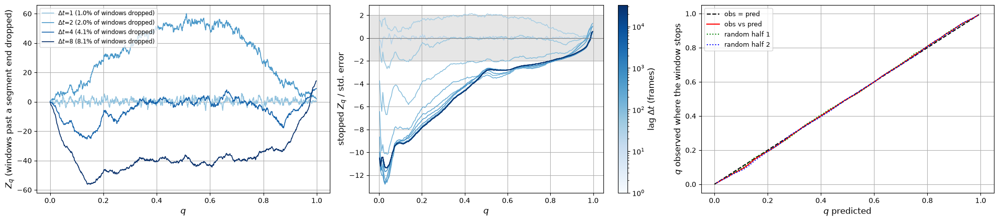

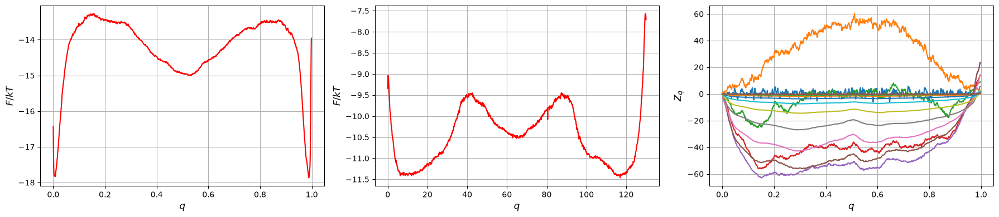

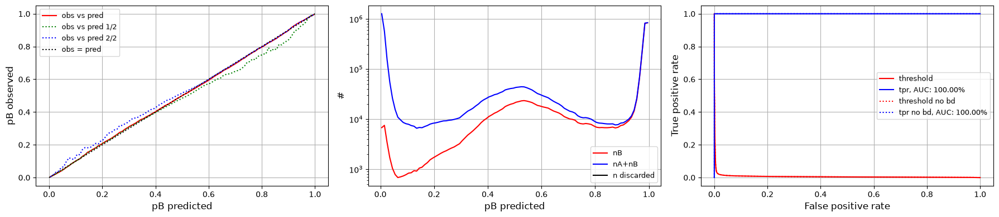

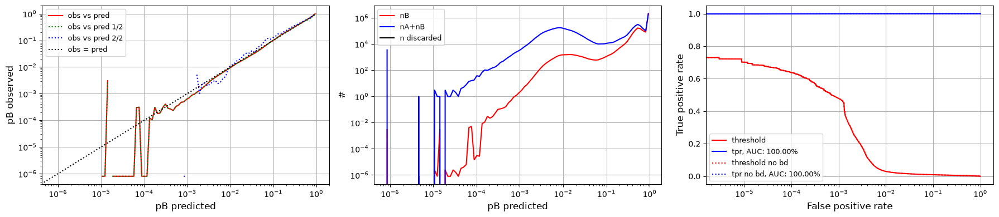

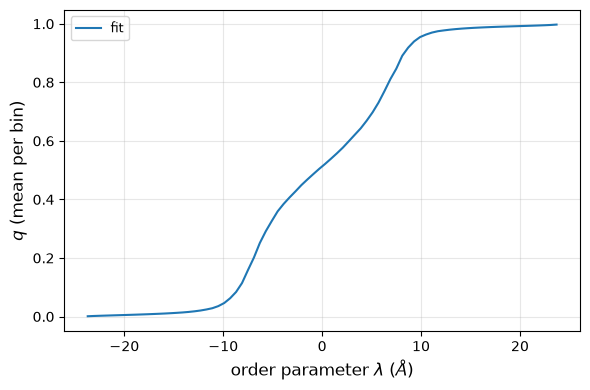

17000 iterations (main, envelope 0.01) 
#=17500, dr2=740.23, zqs_z=12.7094, sdzqs=18.1392, |dx|=0.000174613, time=11.2622
#=18000, dr2=739.775, zqs_z=12.924, sdzqs=18.1001, |dx|=0.000212969, time=22.5749
#=18500, dr2=739.794, zqs_z=12.8471, sdzqs=18.1208, |dx|=0.000171082, time=33.8834
#=19000, dr2=740.118, zqs_z=12.9364, sdzqs=18.1647, |dx|=0.00017293, time=44.8082
#=19500, dr2=740.086, zqs_z=12.9163, sdzqs=18.0915, |dx|=0.000165352, time=56.143
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it19500 ---


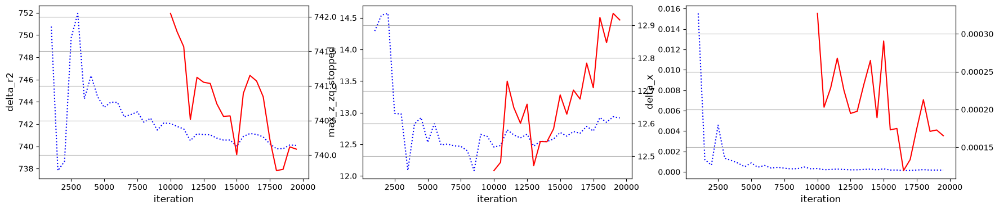

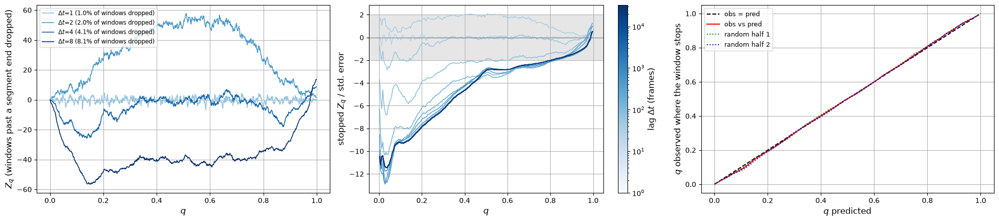

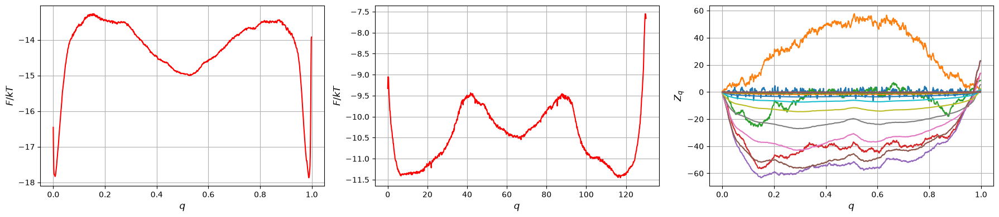

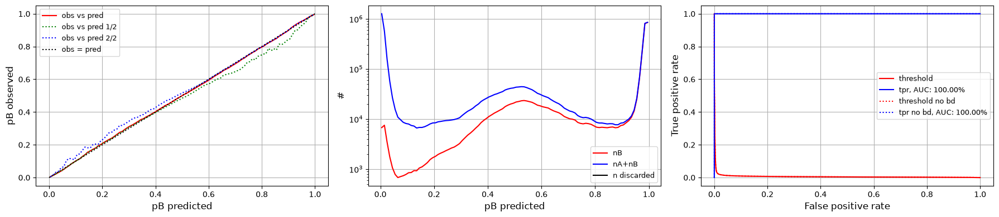

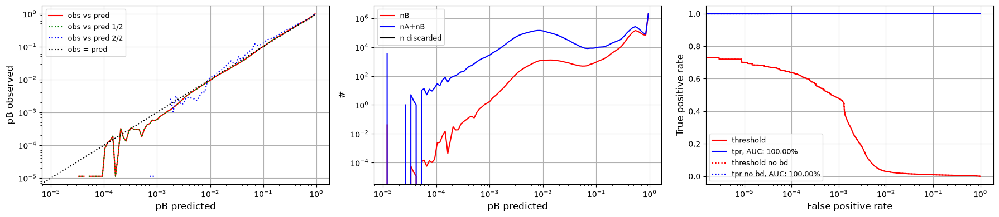

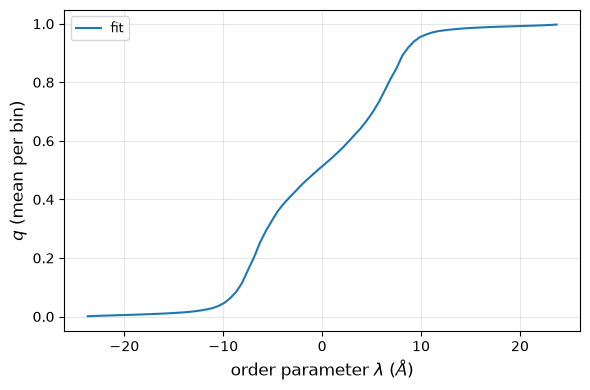

19500 iterations (main, envelope 0.01) 
#=20000, dr2=740.287, zqs_z=12.9162, sdzqs=18.1416, |dx|=0.000143451, time=11.0921
#=20500, dr2=740.36, zqs_z=12.9065, sdzqs=18.0439, |dx|=0.000174871, time=22.3352
#=21000, dr2=740.164, zqs_z=12.925, sdzqs=18.1949, |dx|=0.000136577, time=33.6907
#=21500, dr2=740.417, zqs_z=12.9345, sdzqs=18.2174, |dx|=0.000144518, time=44.5782
#=22000, dr2=740.208, zqs_z=12.8804, sdzqs=18.1755, |dx|=0.000125641, time=55.7965
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it22000 ---


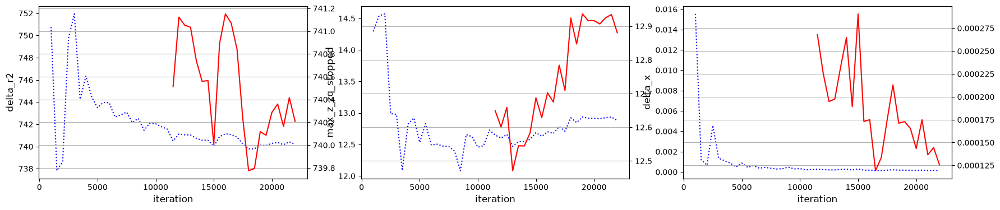

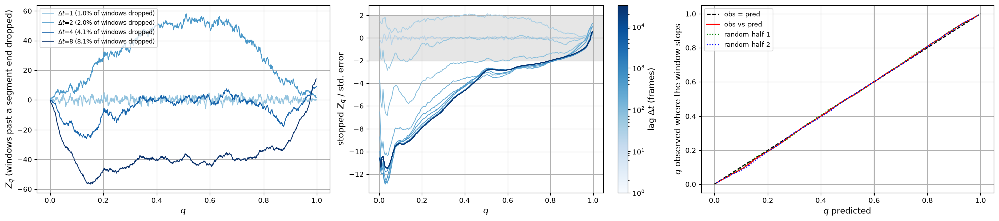

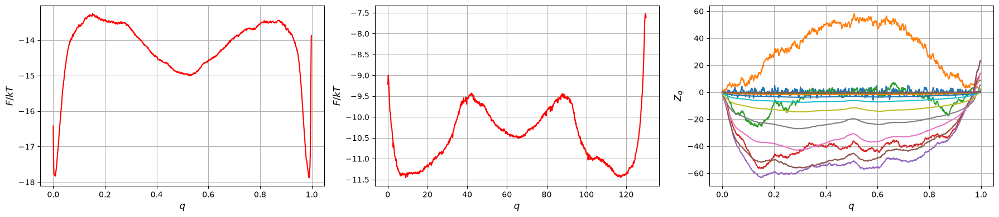

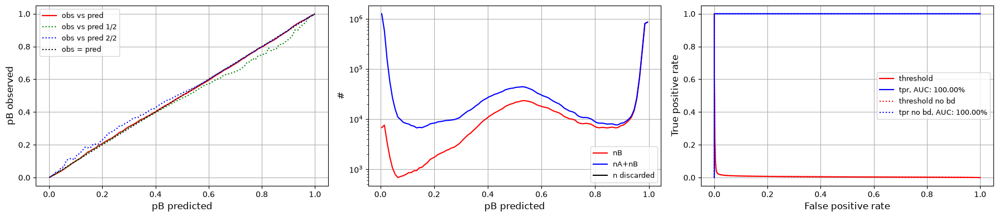

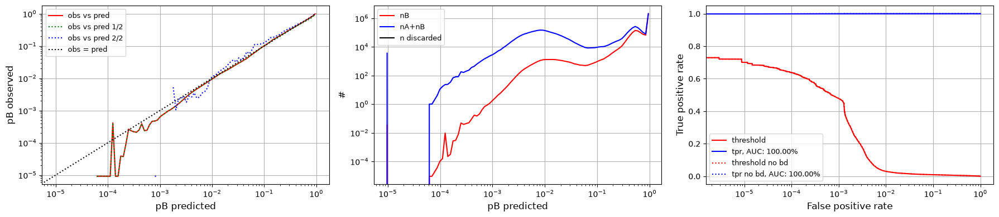

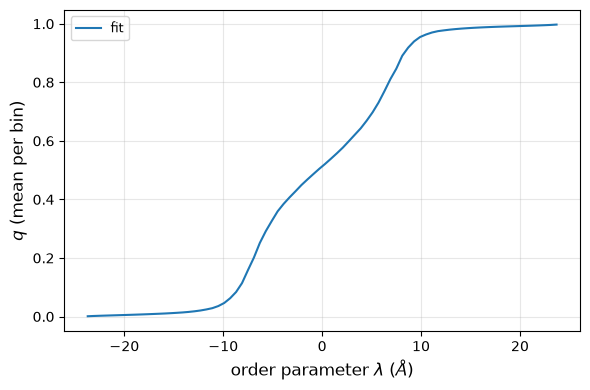

22000 iterations (main, envelope 0.01) 
#=22500, dr2=740.169, zqs_z=12.8771, sdzqs=18.0926, |dx|=0.000166894, time=11.1899
#=23000, dr2=739.922, zqs_z=12.8517, sdzqs=18.1466, |dx|=0.000179474, time=22.4142
#=23500, dr2=739.983, zqs_z=12.9098, sdzqs=18.1462, |dx|=0.000136663, time=33.6791
#=24000, dr2=739.933, zqs_z=12.8358, sdzqs=18.1273, |dx|=9.90799e-05, time=44.9348
#=24500, dr2=740.037, zqs_z=12.8608, sdzqs=18.1838, |dx|=0.000107521, time=54.9215
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it24500 ---


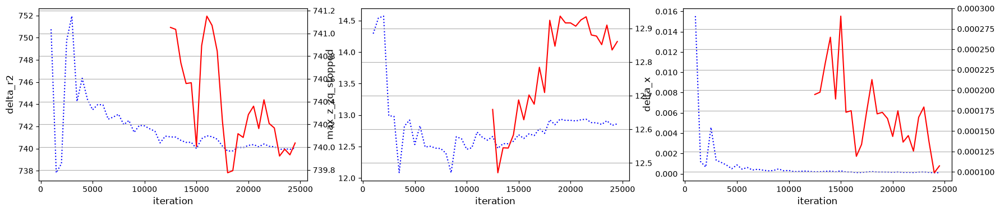

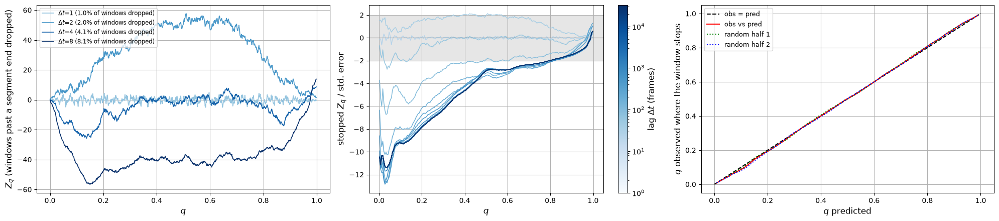

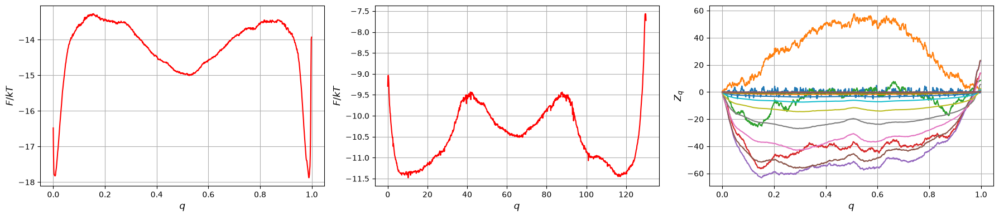

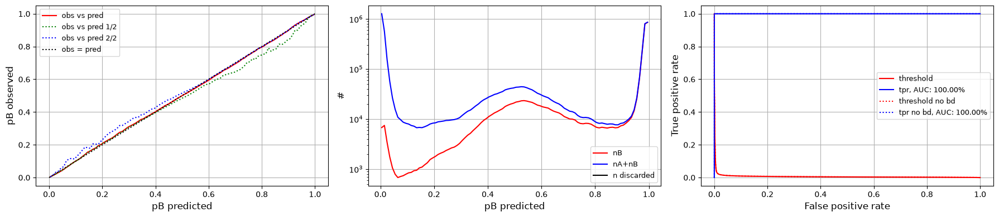

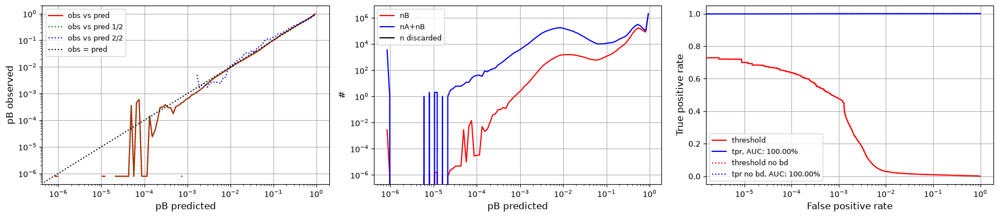

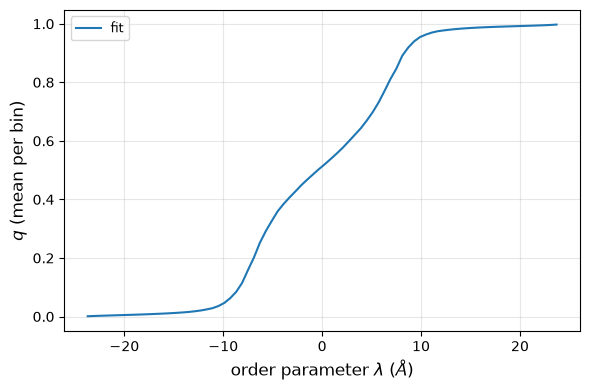

24500 iterations (main, envelope 0.01) 
#=25000, dr2=740.158, zqs_z=12.8348, sdzqs=18.1298, |dx|=0.00016287, time=9.741
#=25500, dr2=740.142, zqs_z=12.8876, sdzqs=18.1409, |dx|=0.00019764, time=19.6239
#=26000, dr2=739.956, zqs_z=13.0303, sdzqs=18.1438, |dx|=0.000131651, time=29.5064
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist01_0/it26000 ---


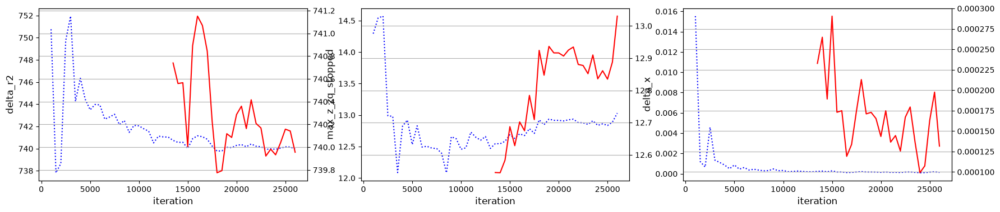

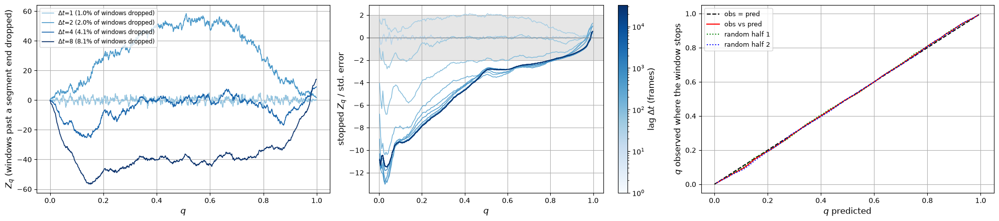

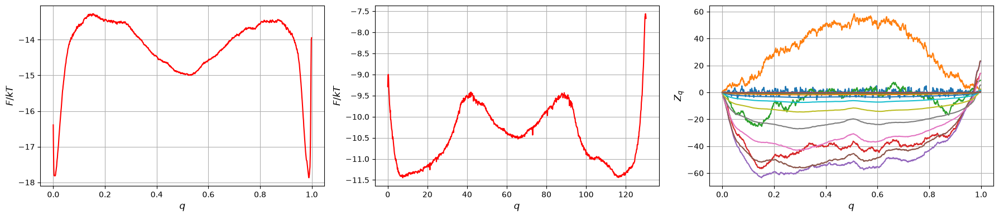

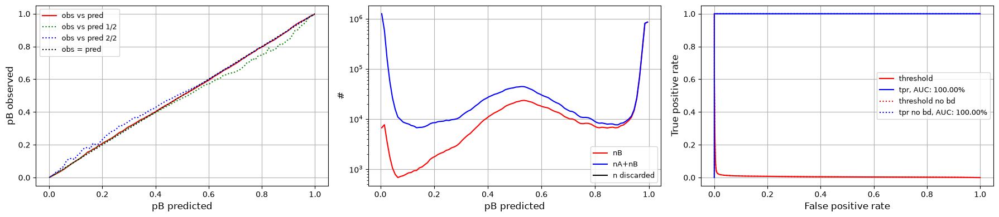

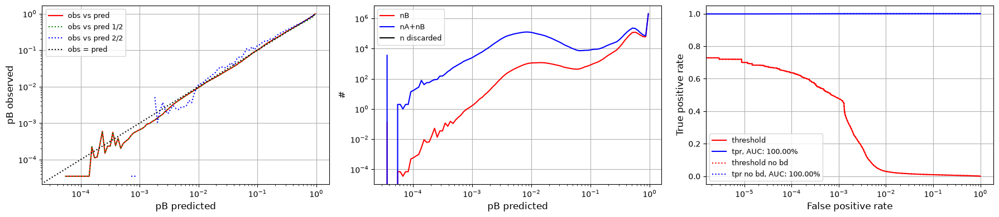

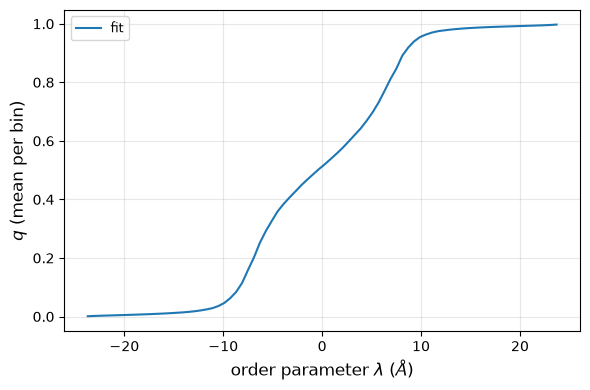

26000 iterations (main, envelope 0.01) 


In [8]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}      # weighting -> final q per seed, exact committor, fit time, zqs_z history

history=[0,1]
yr_type=['y(t-d),y(t)']

for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist01_{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            delta_r2_max_change_allowed=10000,max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj_hist01.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

===== fit, weighting rejections, seed 0 =====
#=500, dr2=409.341, zqs_z=27.6577, sdzqs=76.9556, |dx|=0.388668, time=9.83739
#=1000, dr2=549.62, zqs_z=12.5023, sdzqs=14.6528, |dx|=0.0510871, time=19.7418
#=1500, dr2=560.02, zqs_z=6.83252, sdzqs=12.1422, |dx|=0.00375473, time=29.7917
#=2000, dr2=565.57, zqs_z=7.04293, sdzqs=11.5659, |dx|=0.00124499, time=39.7093
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it2000 ---


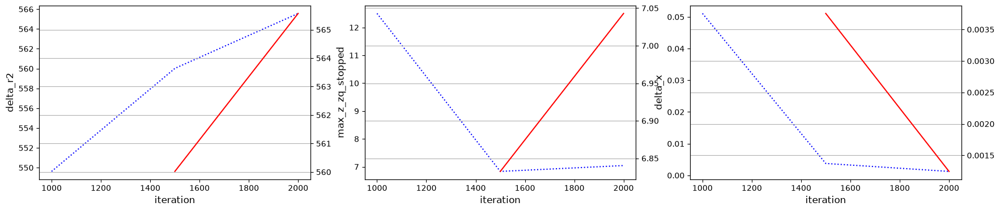

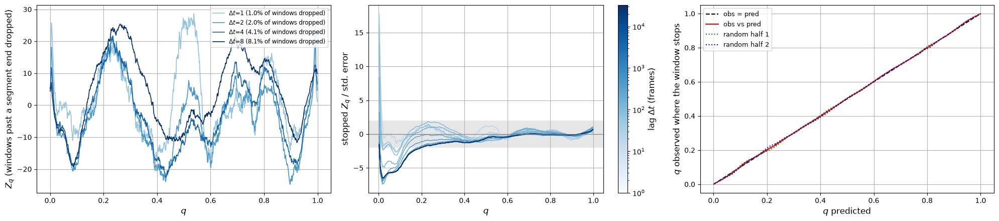

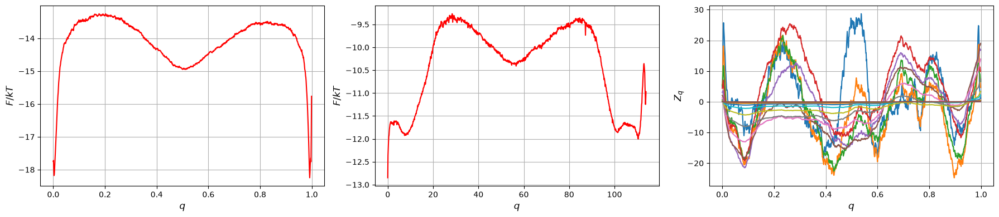

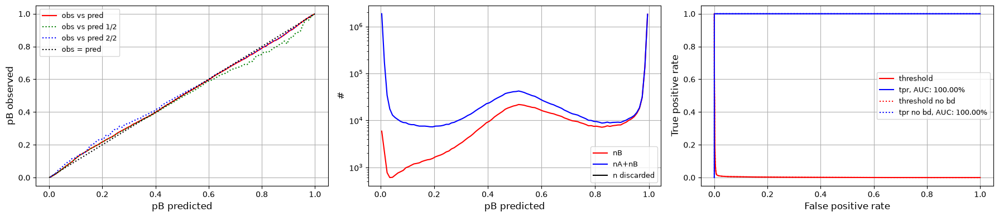

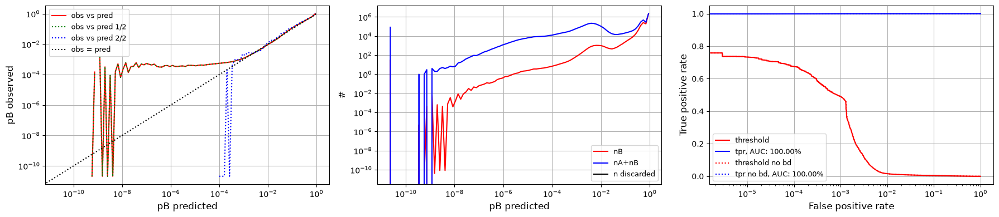

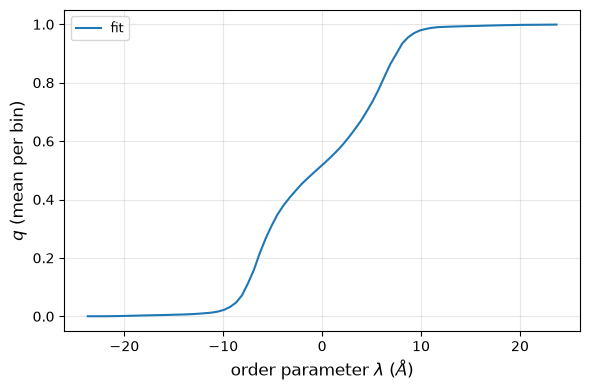

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=560.536, zqs_z=7.78345, sdzqs=7.44926, |dx|=0.00481807, time=9.89522
#=3000, dr2=561.969, zqs_z=6.79466, sdzqs=8.64952, |dx|=0.001829, time=19.8027
#=3500, dr2=557.074, zqs_z=6.49839, sdzqs=8.3425, |dx|=0.00194456, time=29.7171
#=4000, dr2=553.843, zqs_z=5.68143, sdzqs=7.58563, |dx|=0.00130299, time=39.6268
#=4500, dr2=553.124, zqs_z=5.40847, sdzqs=7.64472, |dx|=0.00085195, time=49.5362
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it4500 ---


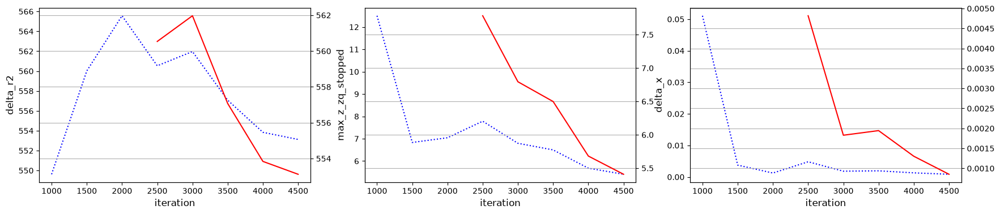

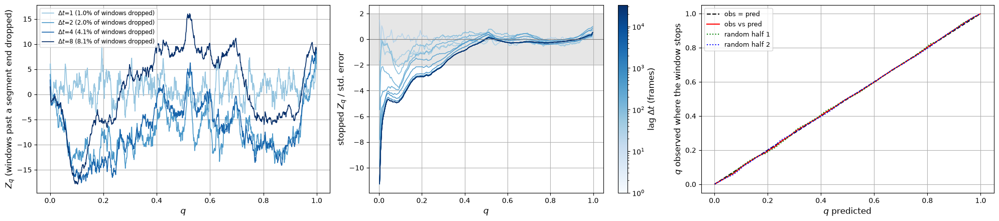

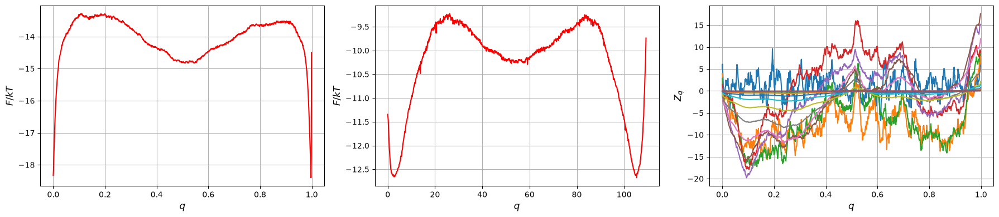

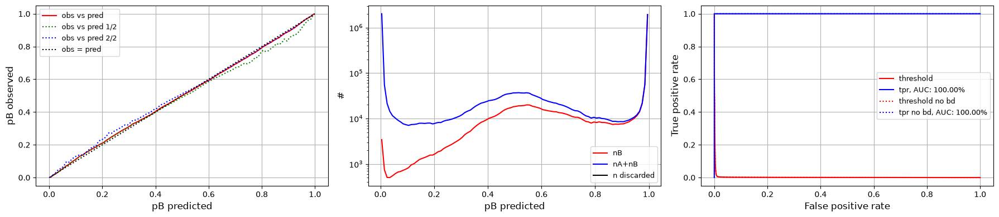

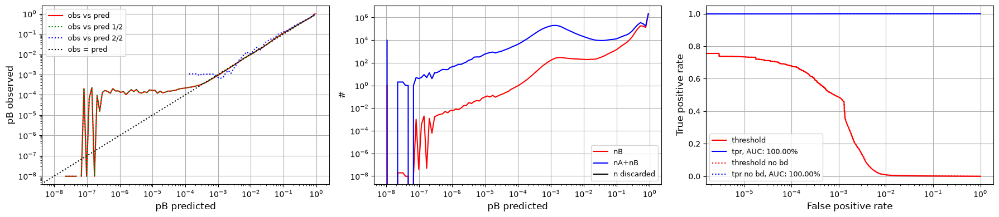

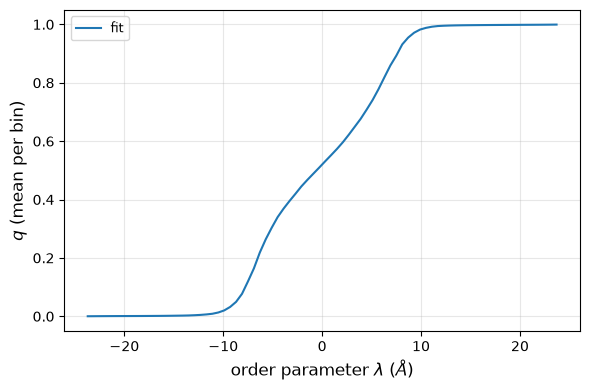

4500 iterations (main, envelope 0.01) 
#=5000, dr2=549.148, zqs_z=4.40725, sdzqs=7.69255, |dx|=0.00128703, time=9.87254
#=5500, dr2=547.098, zqs_z=4.50083, sdzqs=7.50281, |dx|=0.000915514, time=19.7702
#=6000, dr2=545.858, zqs_z=4.76487, sdzqs=6.81868, |dx|=0.00125764, time=29.6756
#=6500, dr2=546.282, zqs_z=4.15932, sdzqs=6.75288, |dx|=0.000821862, time=39.5847
#=7000, dr2=545.477, zqs_z=4.34961, sdzqs=6.88335, |dx|=0.000733945, time=49.4929
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it7000 ---


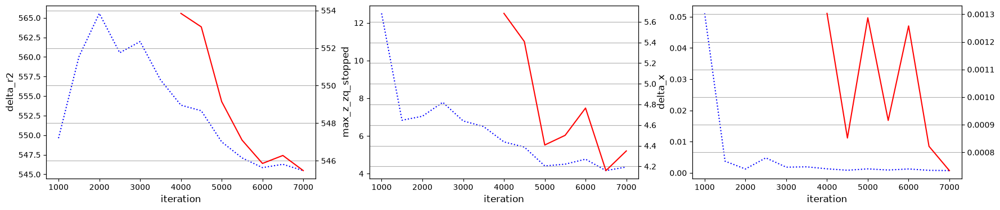

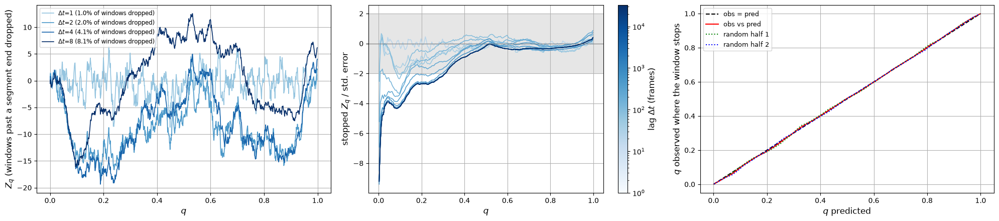

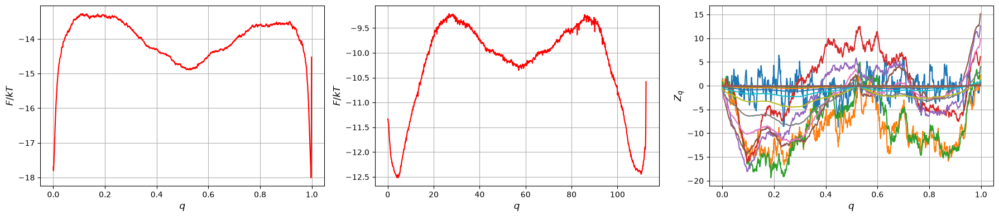

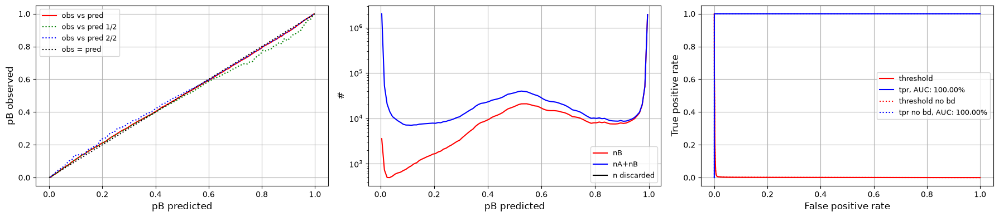

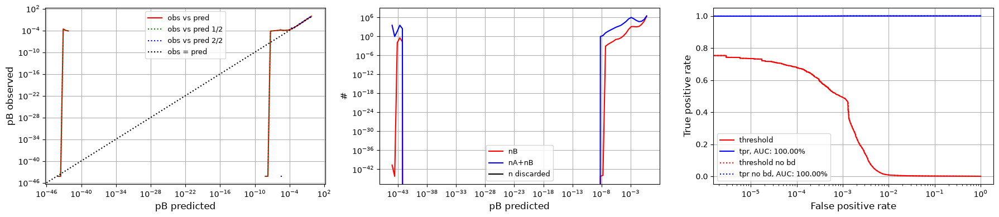

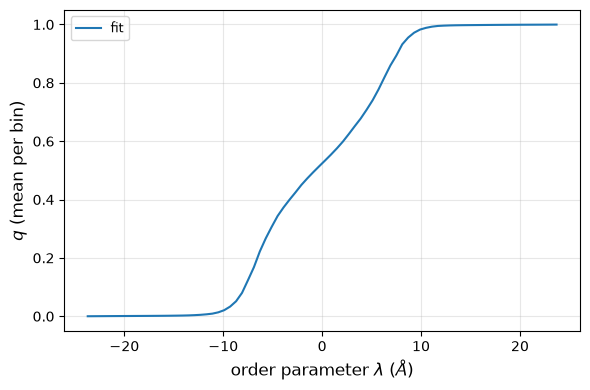

7000 iterations (main, envelope 0.01) 
#=7500, dr2=544.308, zqs_z=4.30836, sdzqs=6.46166, |dx|=0.000624891, time=9.86925
#=8000, dr2=543.91, zqs_z=4.29426, sdzqs=6.72702, |dx|=0.000609069, time=19.7771
#=8500, dr2=544.346, zqs_z=4.89718, sdzqs=7.03799, |dx|=0.000818089, time=29.6916
#=9000, dr2=543.046, zqs_z=4.34328, sdzqs=6.93369, |dx|=0.000987029, time=39.6079
#=9500, dr2=543.824, zqs_z=4.52467, sdzqs=6.50163, |dx|=0.000544252, time=49.5241
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it9500 ---


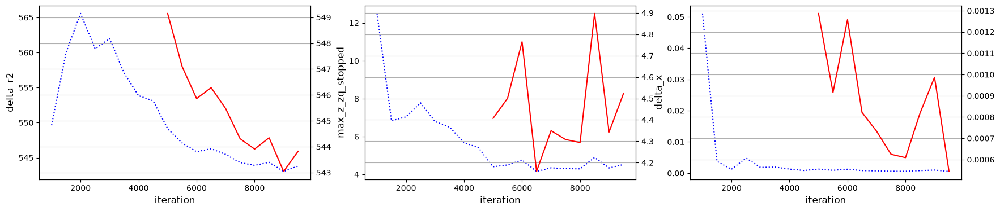

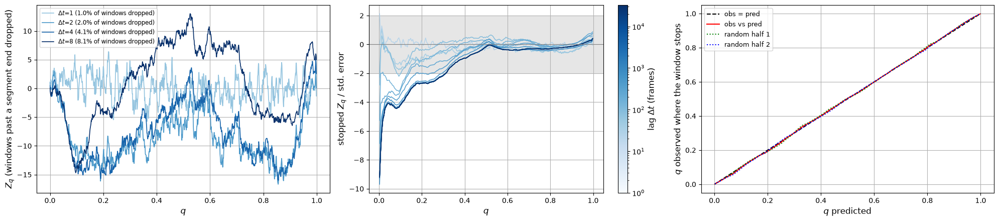

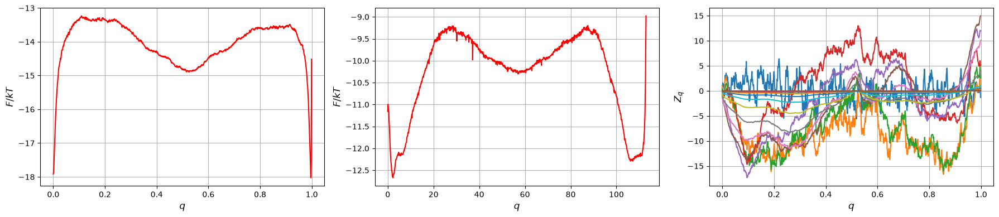

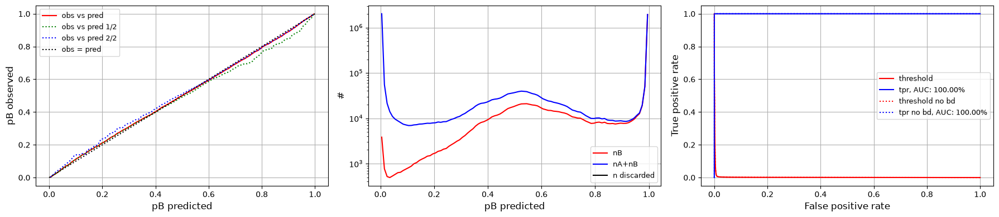

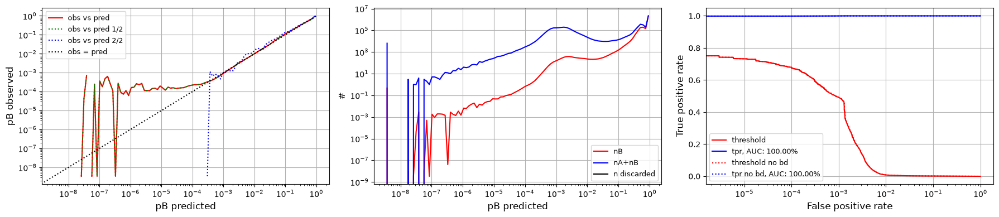

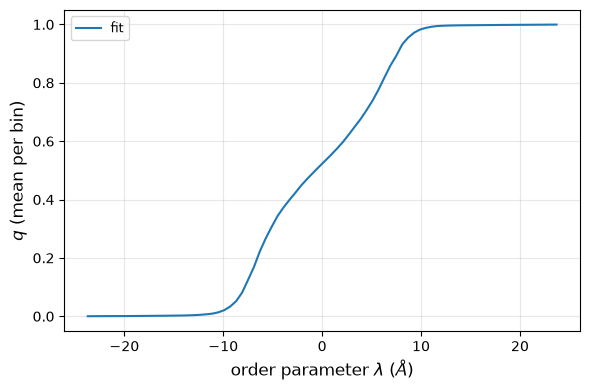

9500 iterations (main, envelope 0.01) 
#=10000, dr2=542.222, zqs_z=4.86913, sdzqs=6.63618, |dx|=0.000454026, time=9.8529
#=10500, dr2=540.641, zqs_z=4.72413, sdzqs=6.81736, |dx|=0.00049691, time=19.7848
#=11000, dr2=540.902, zqs_z=4.21461, sdzqs=6.51891, |dx|=0.000497749, time=29.7119
#=11500, dr2=540.911, zqs_z=4.67699, sdzqs=6.59302, |dx|=0.000574069, time=39.632
#=12000, dr2=540.907, zqs_z=4.91452, sdzqs=6.70095, |dx|=0.0003589, time=49.5534
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it12000 ---


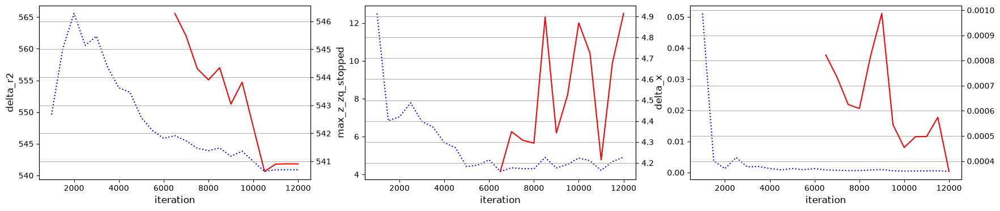

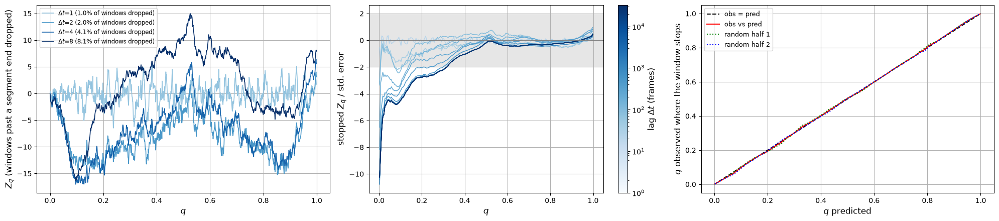

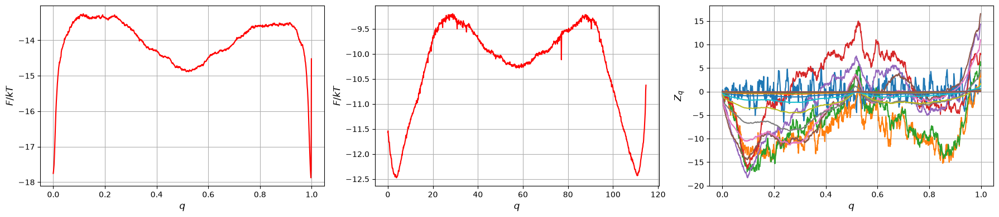

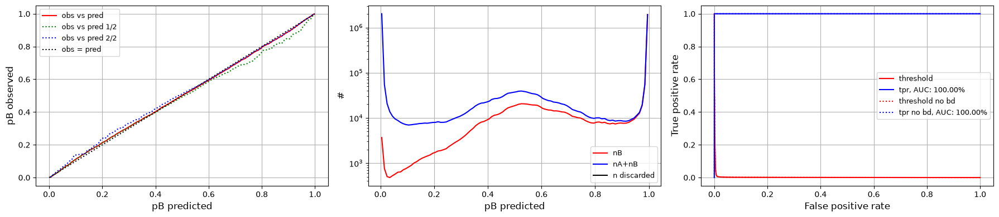

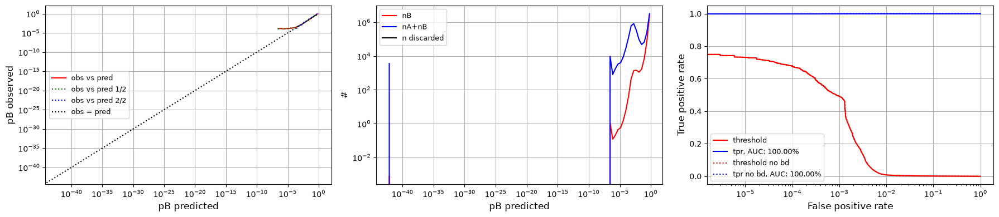

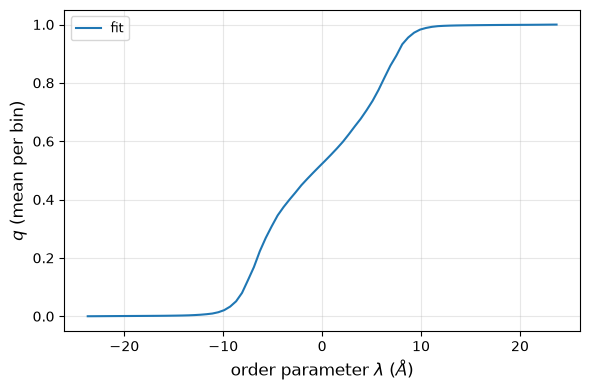

12000 iterations (main, envelope 0.01) 
#=12500, dr2=542.016, zqs_z=4.19701, sdzqs=6.78955, |dx|=0.000494573, time=9.83489
#=13000, dr2=540.739, zqs_z=4.38991, sdzqs=6.91103, |dx|=0.000392646, time=19.7365
#=13500, dr2=542.103, zqs_z=4.17333, sdzqs=6.63237, |dx|=0.000360582, time=29.6415
#=14000, dr2=542.139, zqs_z=4.16072, sdzqs=7.06454, |dx|=0.000475636, time=39.5481
#=14500, dr2=541.884, zqs_z=4.31987, sdzqs=6.96508, |dx|=0.000400375, time=49.4511
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it14500 ---


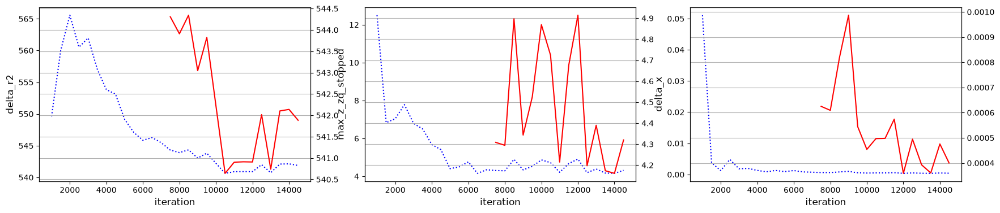

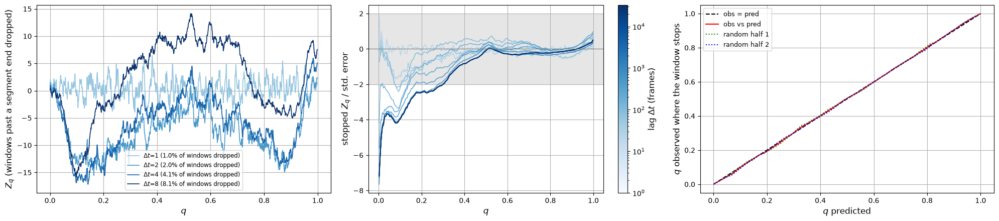

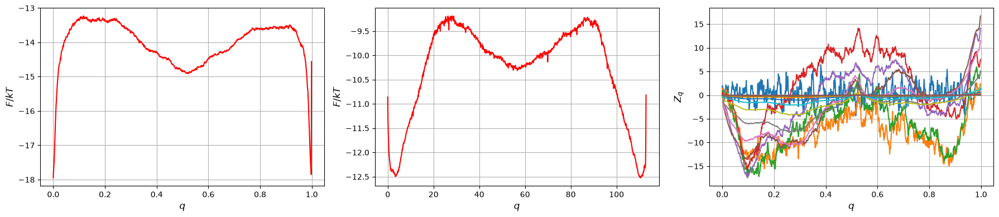

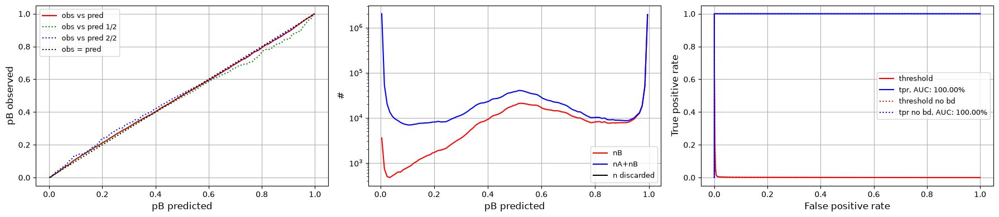

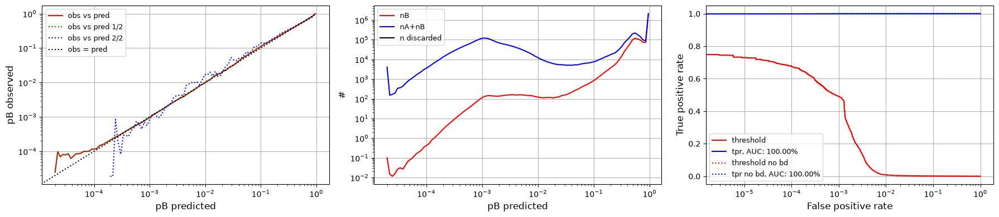

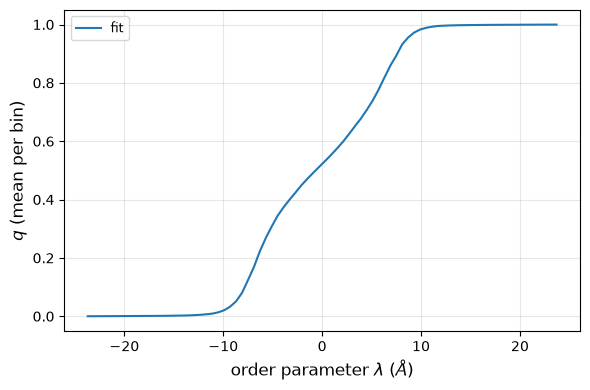

14500 iterations (main, envelope 0.01) 
#=15000, dr2=540.955, zqs_z=4.9611, sdzqs=6.83633, |dx|=0.000387645, time=9.83663
#=15500, dr2=542.002, zqs_z=4.41842, sdzqs=6.95052, |dx|=0.000582418, time=19.7565
#=16000, dr2=541.633, zqs_z=4.2461, sdzqs=6.80194, |dx|=0.0002781, time=29.6774
#=16500, dr2=541.872, zqs_z=4.41033, sdzqs=6.96908, |dx|=0.000320614, time=39.595
#=17000, dr2=541.134, zqs_z=4.32969, sdzqs=6.85594, |dx|=0.000371214, time=49.5366
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it17000 ---


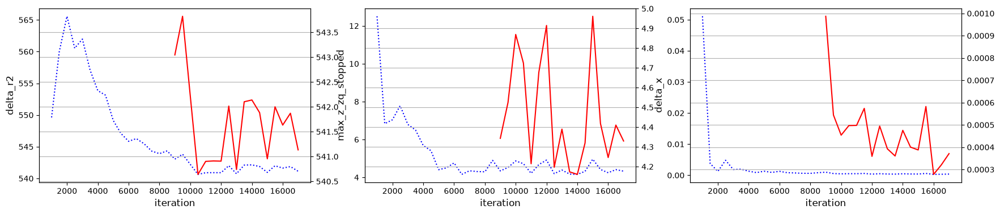

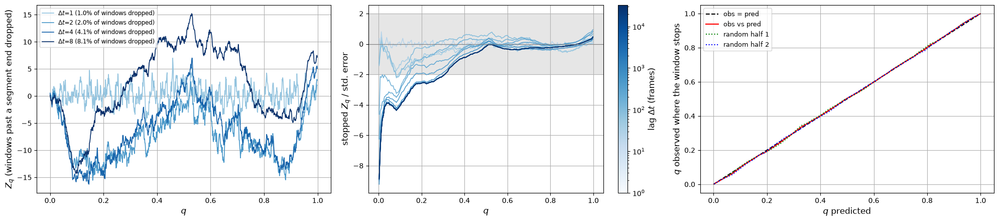

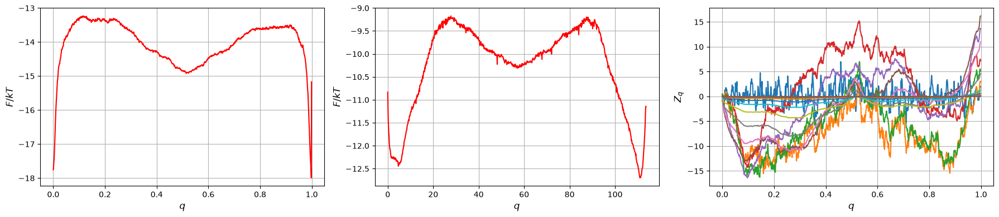

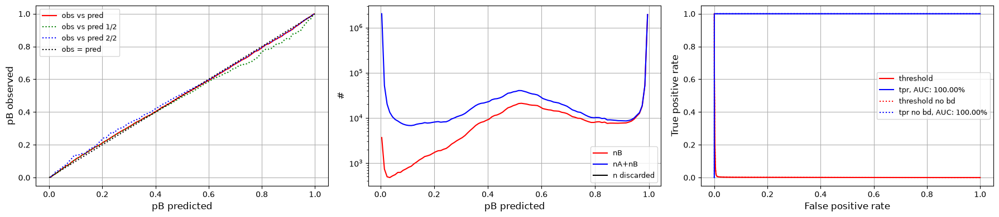

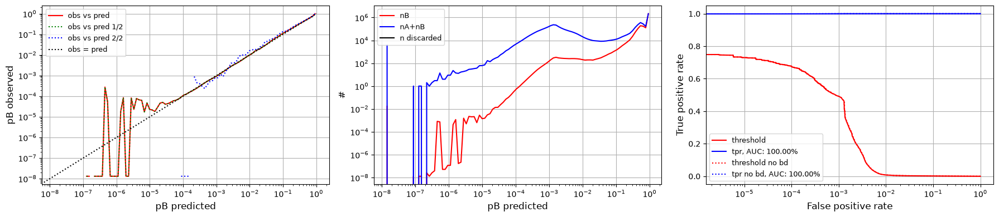

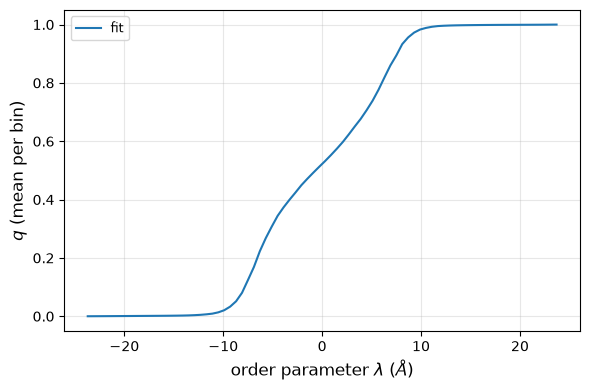

17000 iterations (main, envelope 0.01) 
#=17500, dr2=540.436, zqs_z=4.37795, sdzqs=6.69444, |dx|=0.000281473, time=9.99065
#=18000, dr2=541.955, zqs_z=4.38169, sdzqs=6.79892, |dx|=0.000446741, time=19.916
#=18500, dr2=541.111, zqs_z=4.39763, sdzqs=7.05266, |dx|=0.000270473, time=29.8435
#=19000, dr2=541.167, zqs_z=4.60669, sdzqs=6.62409, |dx|=0.000438042, time=39.7593
#=19500, dr2=542.672, zqs_z=4.50083, sdzqs=6.9419, |dx|=0.000494906, time=49.6862
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it19500 ---


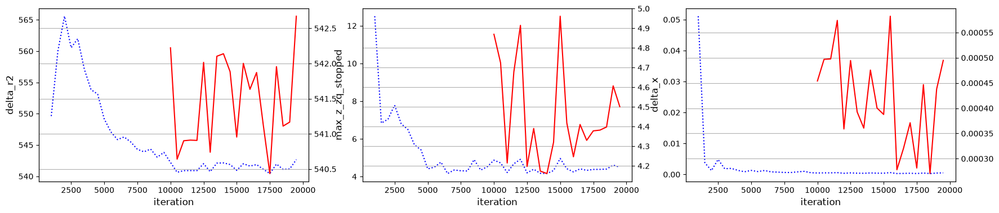

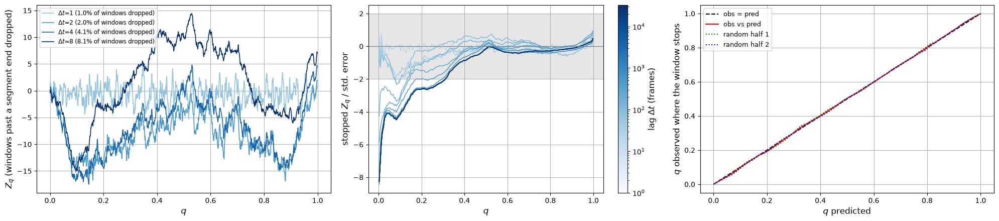

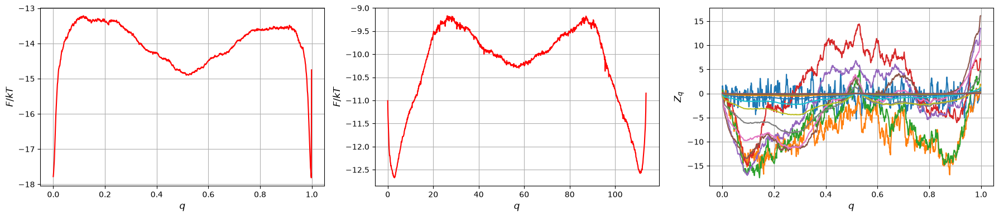

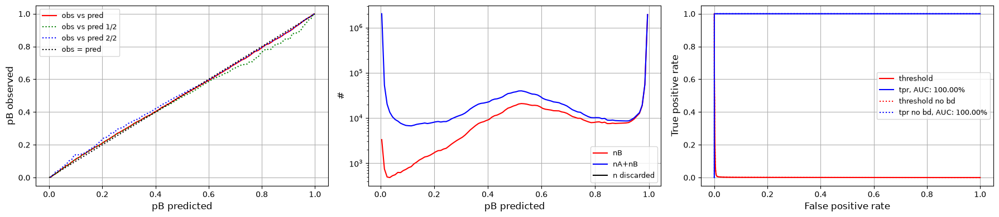

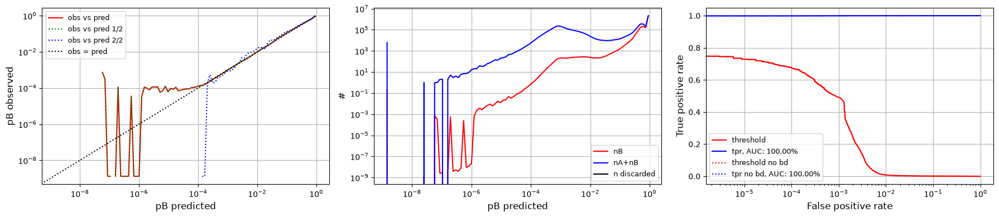

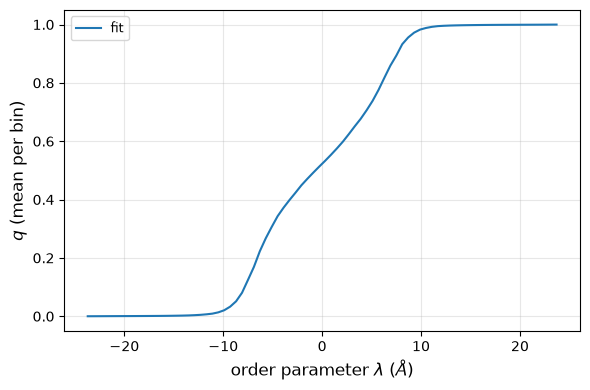

19500 iterations (main, envelope 0.01) 
#=20000, dr2=540.116, zqs_z=4.50425, sdzqs=6.36368, |dx|=0.000513156, time=9.79861
#=20500, dr2=541.18, zqs_z=4.31919, sdzqs=6.95138, |dx|=0.000478545, time=19.7178
#=21000, dr2=541.777, zqs_z=4.34767, sdzqs=7.02271, |dx|=0.000313033, time=30.279
#=21500, dr2=540.466, zqs_z=4.60591, sdzqs=6.962, |dx|=0.000270446, time=41.484
#=22000, dr2=540.983, zqs_z=4.16652, sdzqs=6.7994, |dx|=0.000251007, time=52.6879
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it22000 ---


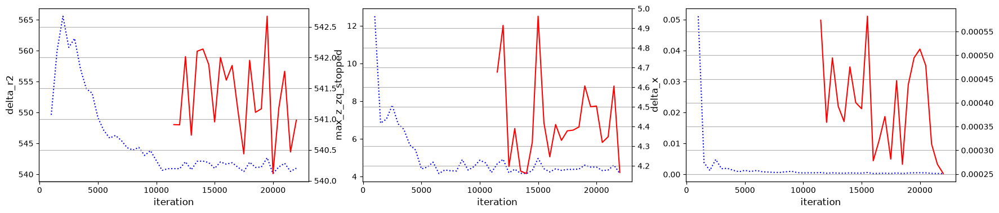

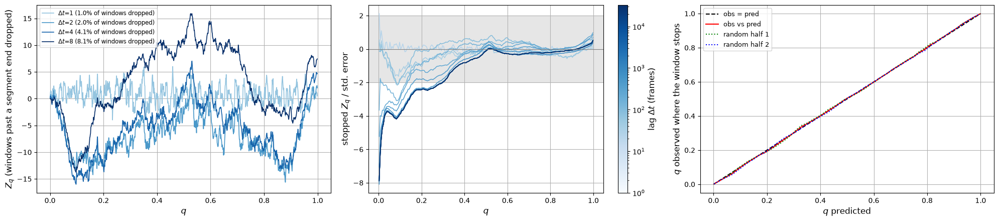

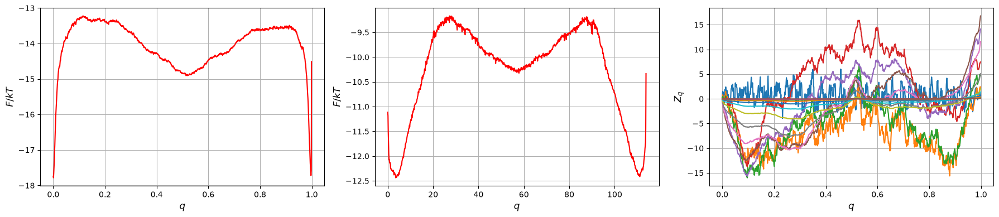

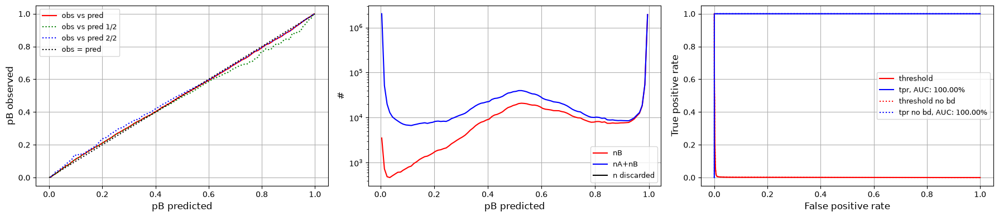

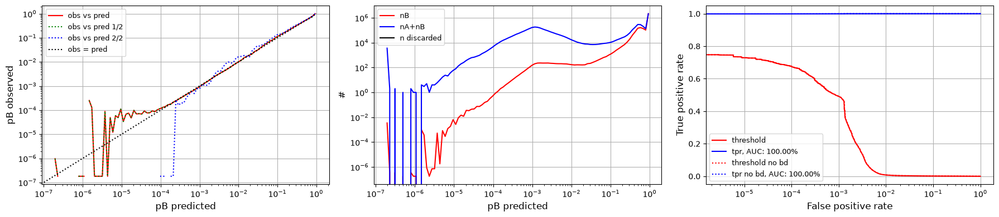

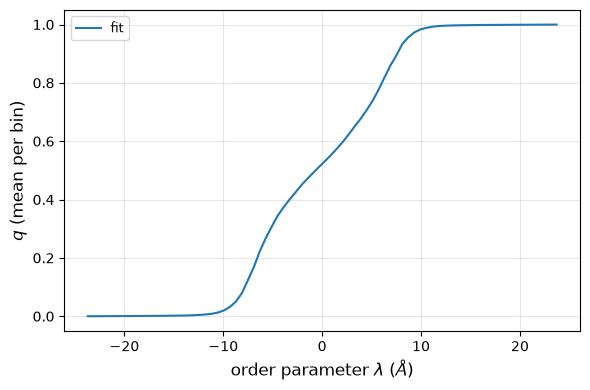

22000 iterations (main, envelope 0.01) 
#=22500, dr2=540.525, zqs_z=4.79921, sdzqs=6.80982, |dx|=0.000242125, time=11.2965
#=23000, dr2=540.787, zqs_z=4.24355, sdzqs=6.81012, |dx|=0.000331792, time=22.7076
#=23500, dr2=540.167, zqs_z=4.46283, sdzqs=6.8274, |dx|=0.000267007, time=34.1198
#=24000, dr2=541.089, zqs_z=4.5501, sdzqs=6.90732, |dx|=0.000220578, time=45.5781
#=24500, dr2=540.994, zqs_z=4.66563, sdzqs=6.80883, |dx|=0.000268624, time=57.0017
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it24500 ---


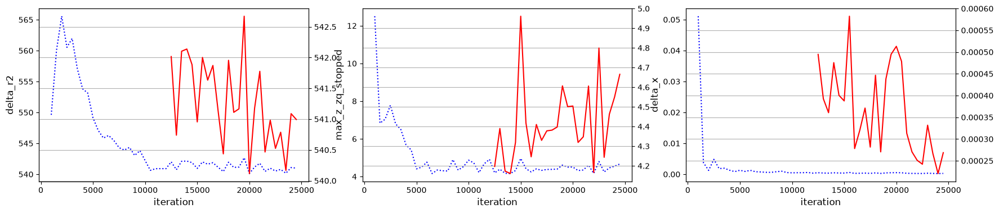

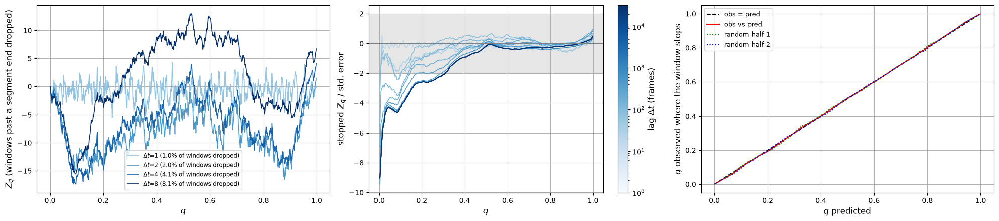

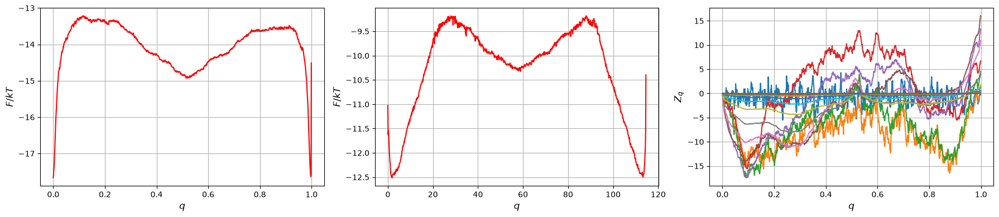

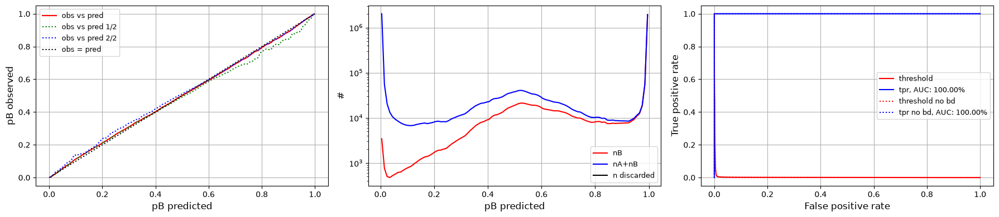

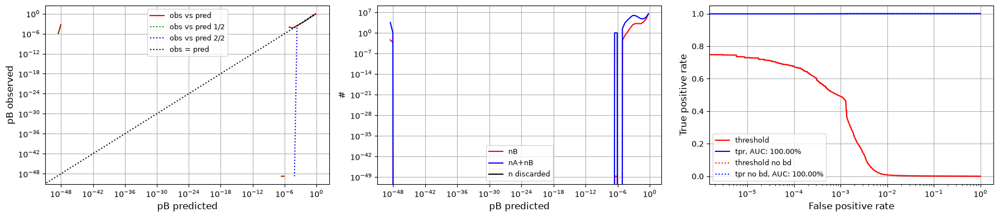

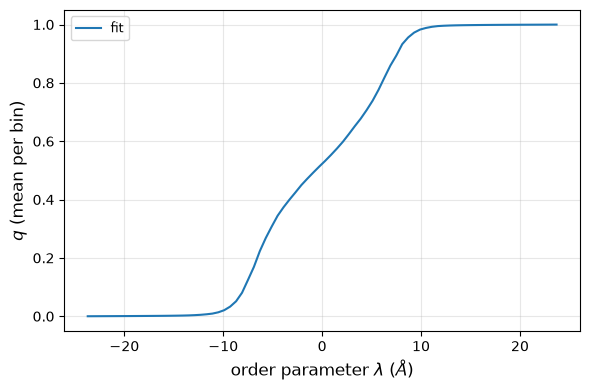

24500 iterations (main, envelope 0.01) 
#=25000, dr2=541.162, zqs_z=4.47683, sdzqs=6.78917, |dx|=0.000244658, time=11.1392
#=25500, dr2=541.511, zqs_z=4.38859, sdzqs=7.02981, |dx|=0.000388035, time=22.4282
#=26000, dr2=541.736, zqs_z=4.53061, sdzqs=6.77048, |dx|=0.000313786, time=33.748
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it26000 ---


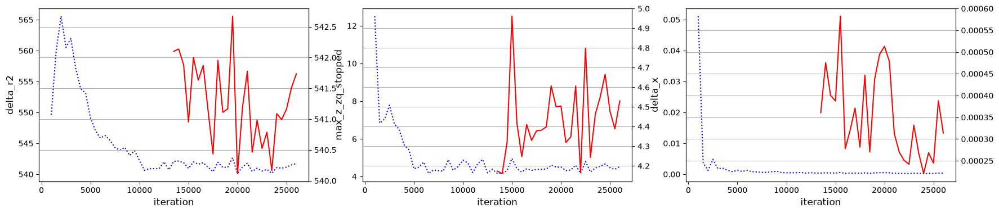

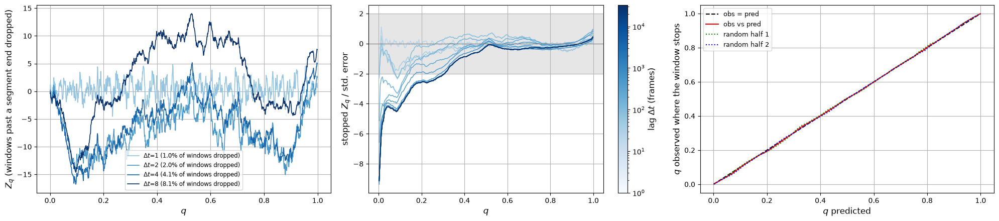

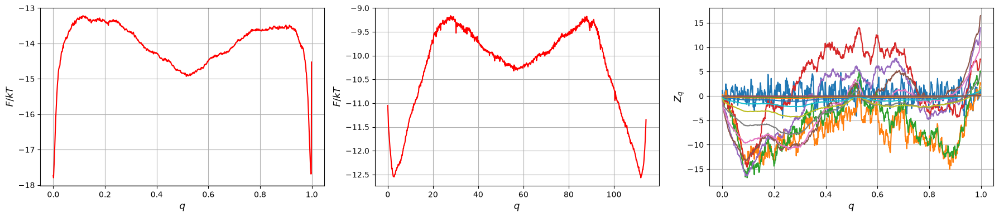

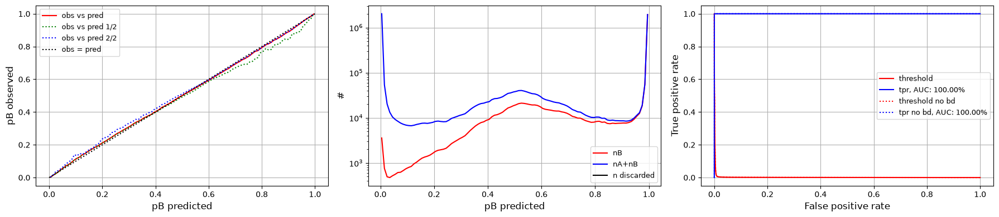

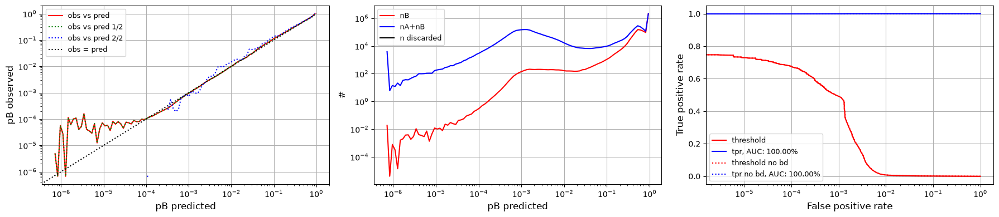

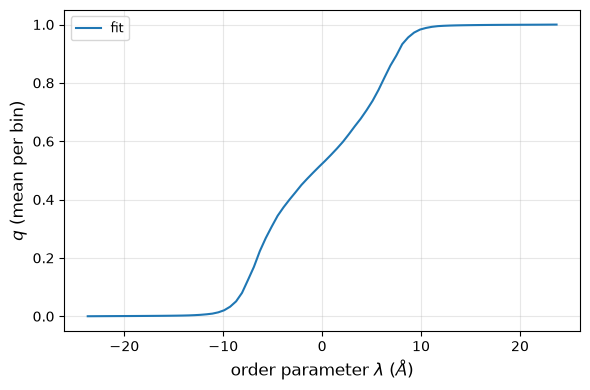

26000 iterations (main, envelope 0.01) 


In [9]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}      # weighting -> final q per seed, exact committor, fit time, zqs_z history

history=[0,1,2,4]
yr_type=['y(t-d),y(t)']

for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist0124_{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            delta_r2_max_change_allowed=10000,max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj_hist0124.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

===== fit, weighting rejections, seed 0 =====
#=500, dr2=400.68, zqs_z=11.5409, sdzqs=33.4147, |dx|=0.433616, time=11.4705
#=1000, dr2=457.92, zqs_z=8.26076, sdzqs=27.4359, |dx|=0.0101785, time=23.191
#=1500, dr2=496.165, zqs_z=7.12487, sdzqs=21.9998, |dx|=0.00216445, time=34.7062
#=2000, dr2=502.699, zqs_z=7.40542, sdzqs=20.5789, |dx|=0.00312636, time=46.3614
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it2000 ---


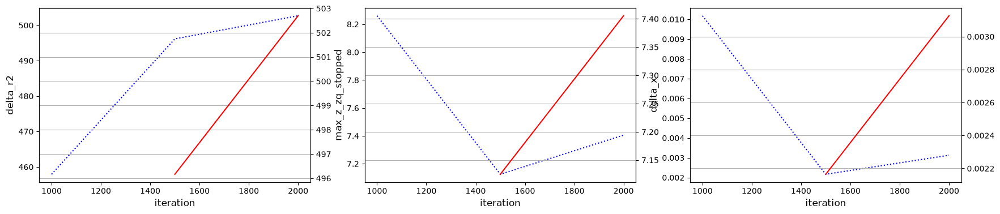

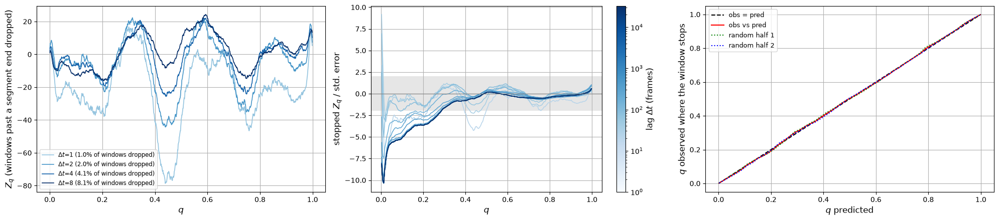

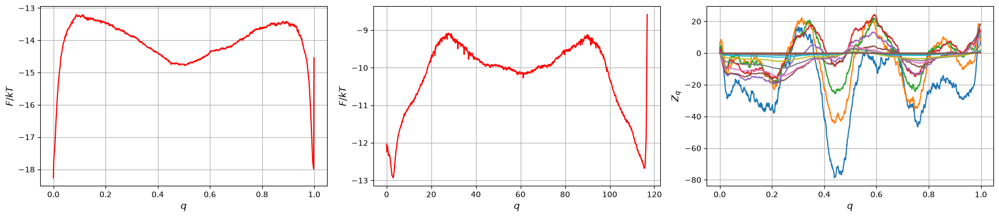

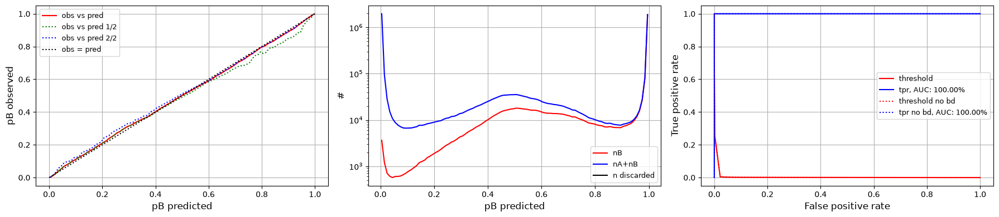

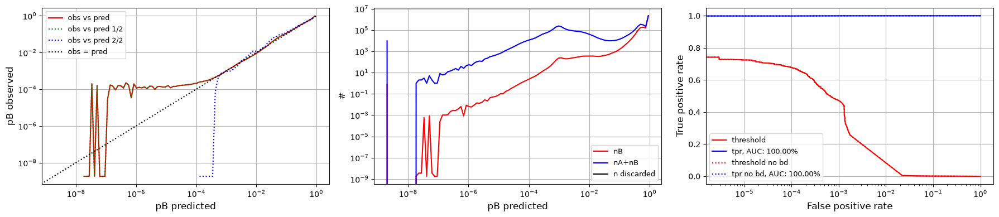

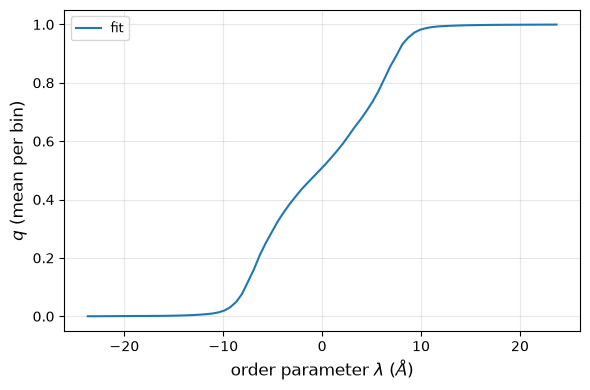

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=554.445, zqs_z=6.86527, sdzqs=8.01736, |dx|=0.00451276, time=11.6427
#=3000, dr2=539.2, zqs_z=6.83912, sdzqs=7.98041, |dx|=0.00333986, time=23.773
#=3500, dr2=547.577, zqs_z=7.08686, sdzqs=7.25921, |dx|=0.00225353, time=45.4329
#=4000, dr2=546.165, zqs_z=7.5024, sdzqs=7.01736, |dx|=0.00169562, time=62.5848
#=4500, dr2=554.443, zqs_z=8.00238, sdzqs=7.33943, |dx|=0.00174007, time=80.327
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it4500 ---


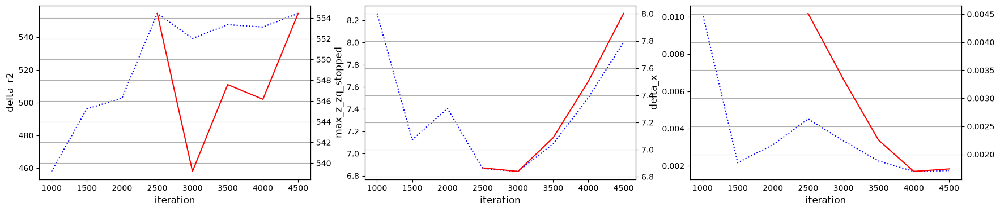

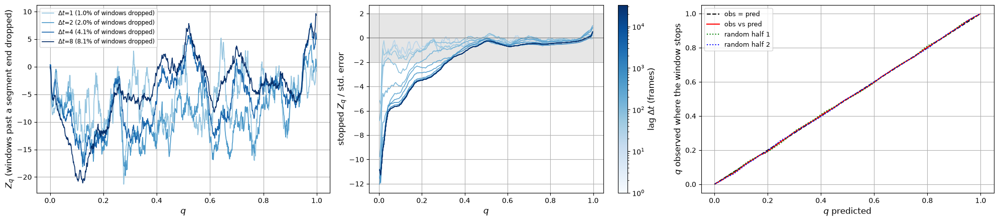

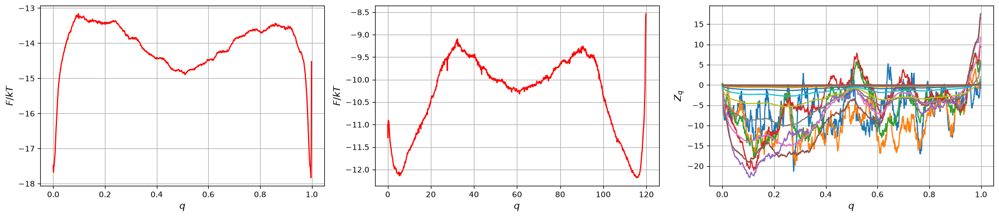

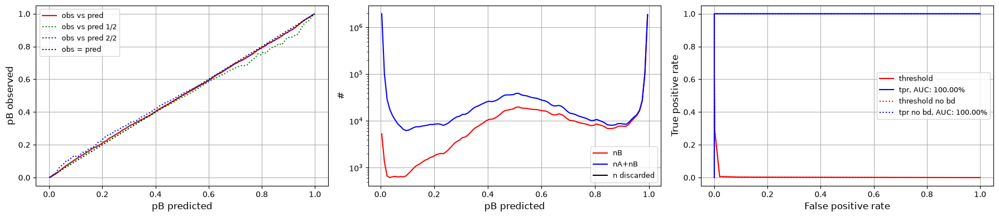

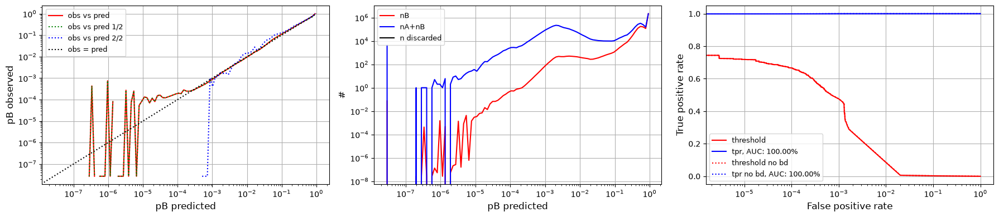

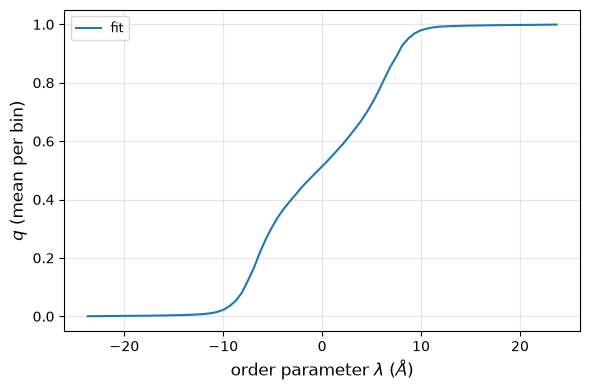

4500 iterations (main, envelope 0.01) 
#=5000, dr2=555.62, zqs_z=8.12131, sdzqs=7.40288, |dx|=0.00160785, time=14.295
#=5500, dr2=559.705, zqs_z=7.89536, sdzqs=7.0907, |dx|=0.00132602, time=34.5229
#=6000, dr2=557.499, zqs_z=7.55912, sdzqs=6.72951, |dx|=0.00117469, time=55.9469
#=6500, dr2=563.869, zqs_z=7.93446, sdzqs=7.03626, |dx|=0.00113082, time=69.2408
#=7000, dr2=561.44, zqs_z=7.34164, sdzqs=7.33706, |dx|=0.00135923, time=91.0449
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it7000 ---


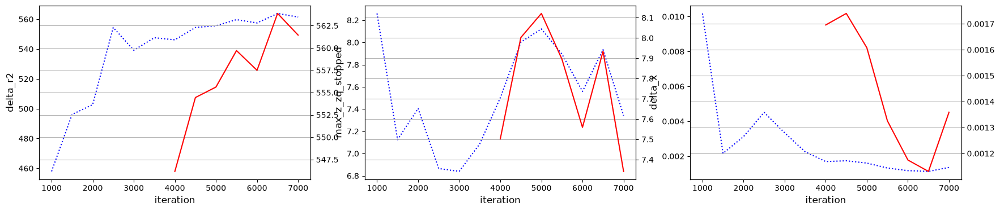

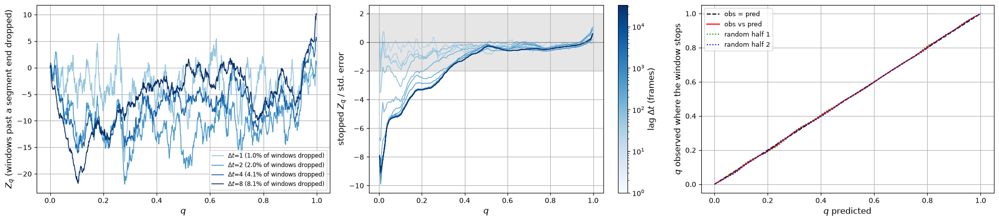

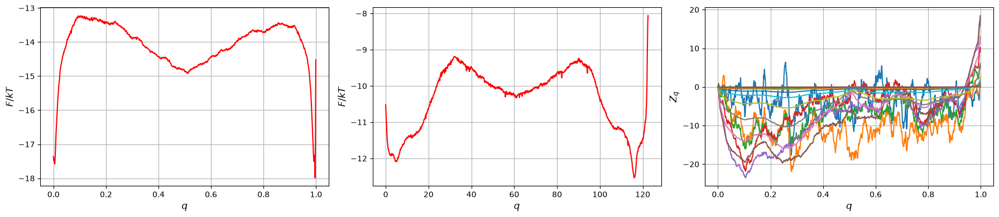

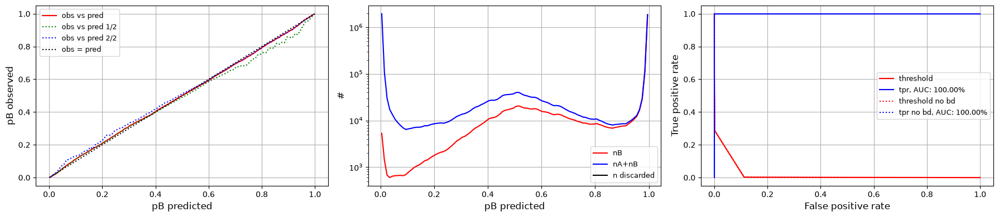

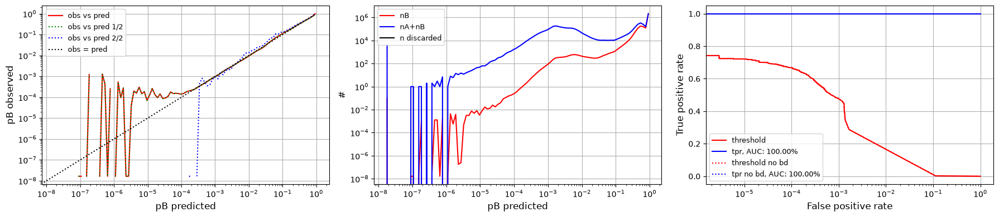

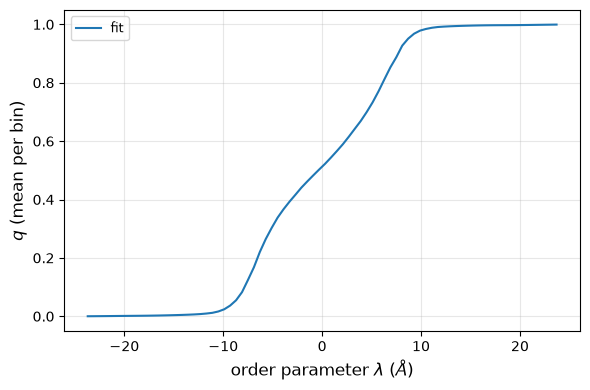

7000 iterations (main, envelope 0.01) 
#=7500, dr2=563.052, zqs_z=7.99557, sdzqs=7.20872, |dx|=0.000934466, time=12.6497
#=8000, dr2=563.077, zqs_z=7.94608, sdzqs=7.2814, |dx|=0.000896727, time=25.0143
#=8500, dr2=566.716, zqs_z=7.9476, sdzqs=7.52996, |dx|=0.000781926, time=44.8522
#=9000, dr2=567.802, zqs_z=7.40909, sdzqs=7.31722, |dx|=0.000709667, time=66.1662
#=9500, dr2=563.405, zqs_z=7.27354, sdzqs=7.18345, |dx|=0.00100407, time=79.2199
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it9500 ---


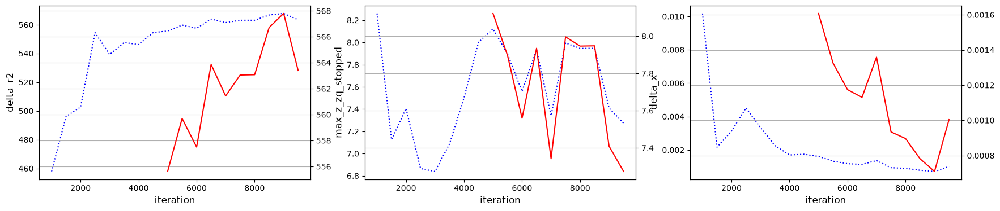

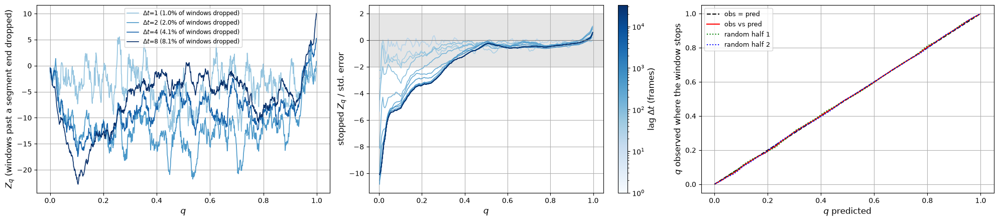

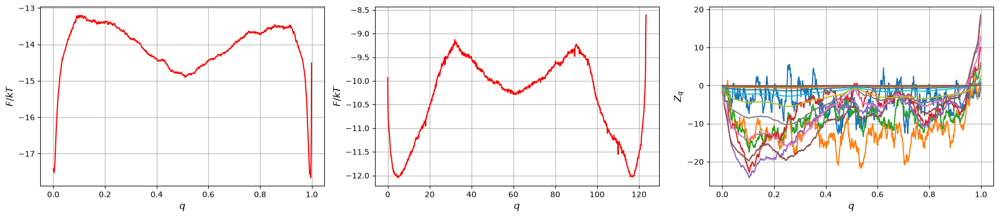

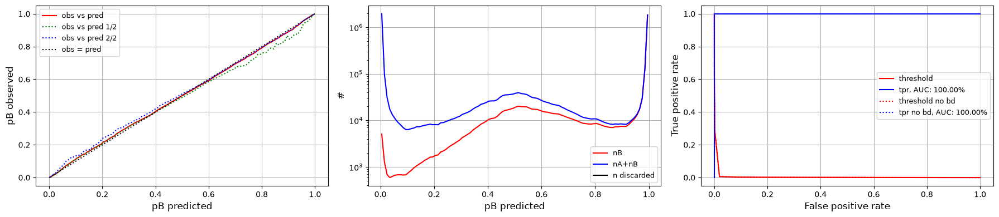

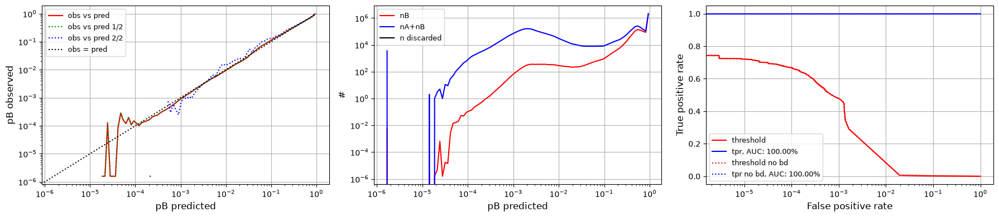

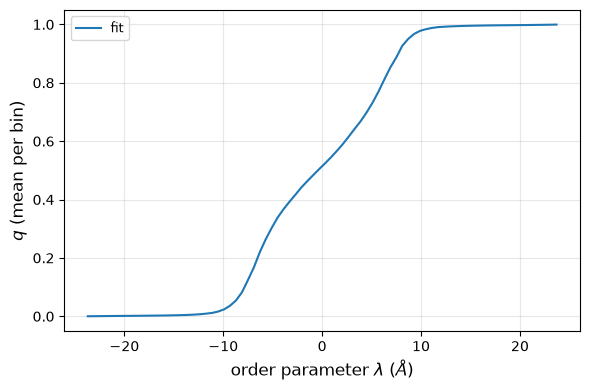

9500 iterations (main, envelope 0.01) 
#=10000, dr2=565.924, zqs_z=8.02164, sdzqs=7.00615, |dx|=0.00083249, time=19.7098
#=10500, dr2=564.357, zqs_z=7.61374, sdzqs=7.1759, |dx|=0.000716996, time=34.5762
#=11000, dr2=568.593, zqs_z=7.43033, sdzqs=7.06384, |dx|=0.000635268, time=56.3484
#=11500, dr2=566.449, zqs_z=7.70097, sdzqs=7.04496, |dx|=0.000657133, time=70.1703
#=12000, dr2=568.803, zqs_z=7.61534, sdzqs=6.78701, |dx|=0.000903515, time=91.0906
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it12000 ---


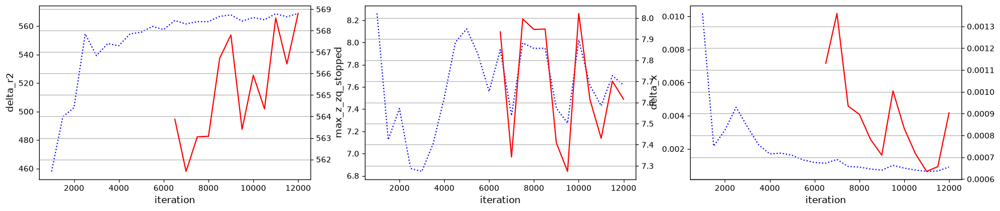

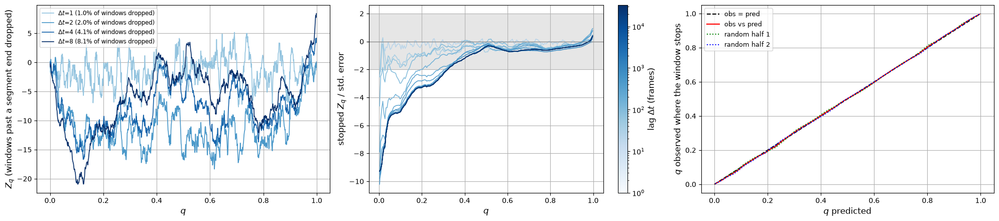

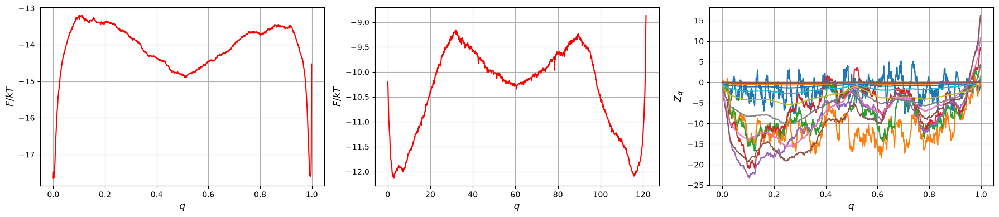

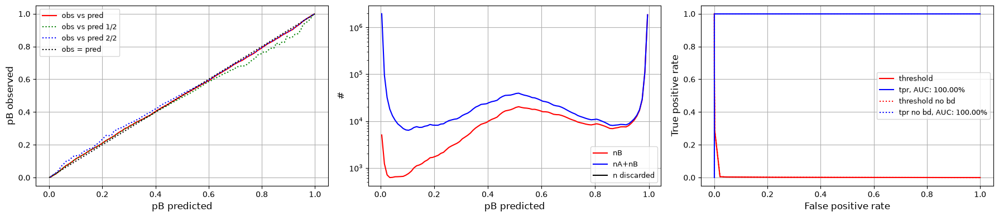

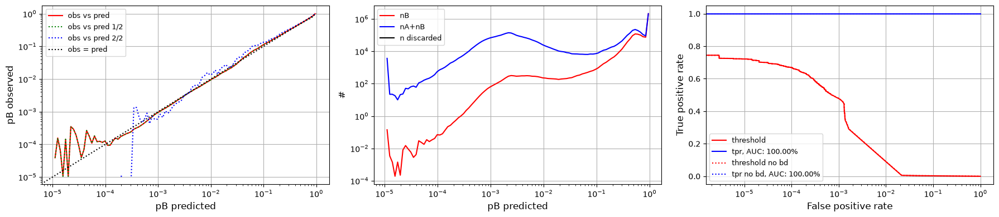

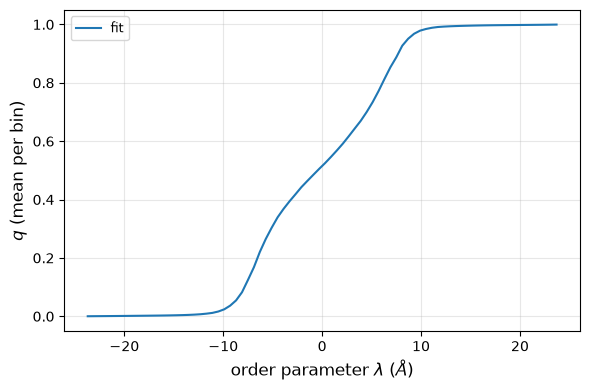

12000 iterations (main, envelope 0.01) 
#=12500, dr2=564.58, zqs_z=7.6732, sdzqs=6.97486, |dx|=0.00063111, time=12.516
#=13000, dr2=567.602, zqs_z=7.28102, sdzqs=6.93437, |dx|=0.000565901, time=33.0146
#=13500, dr2=567.615, zqs_z=7.66037, sdzqs=6.82124, |dx|=0.000677225, time=51.7717
#=14000, dr2=567.67, zqs_z=7.77311, sdzqs=7.03543, |dx|=0.000575306, time=63.2344
#=14500, dr2=564.69, zqs_z=7.53045, sdzqs=7.19488, |dx|=0.000511693, time=75.8272
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it14500 ---


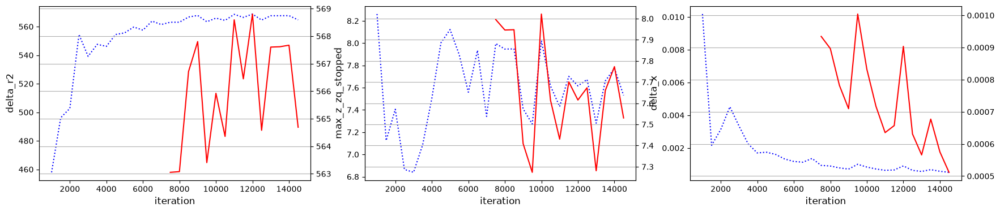

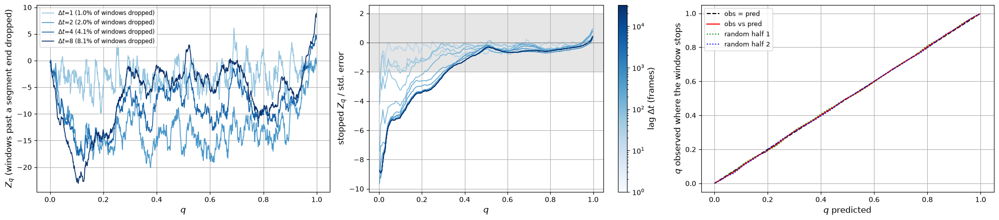

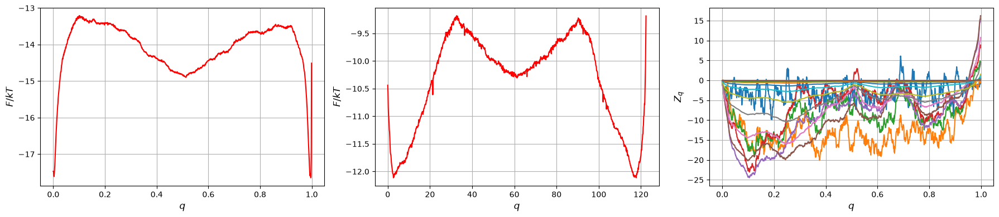

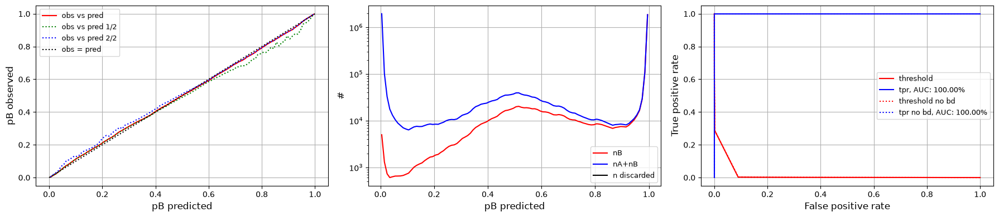

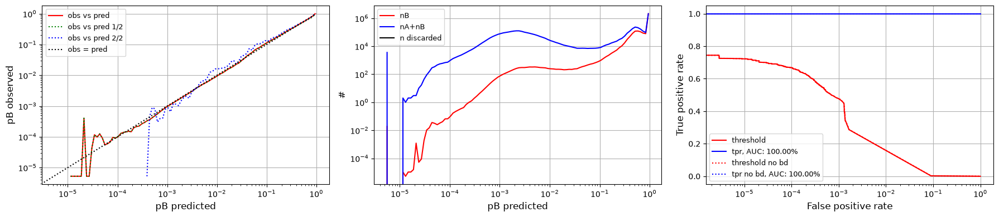

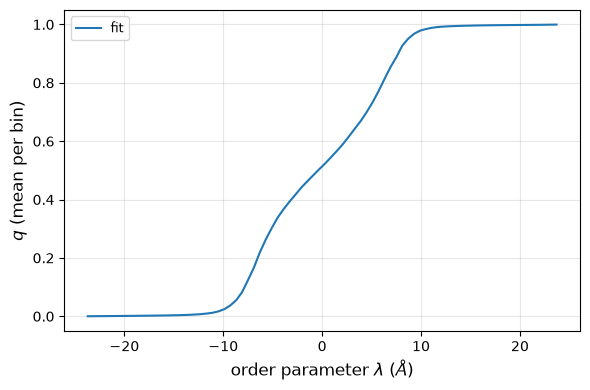

14500 iterations (main, envelope 0.01) 
#=15000, dr2=565.751, zqs_z=7.38655, sdzqs=6.98274, |dx|=0.000476351, time=20.035
#=15500, dr2=565.486, zqs_z=7.55531, sdzqs=6.83133, |dx|=0.000570734, time=34.156
#=16000, dr2=567.139, zqs_z=7.52736, sdzqs=7.05459, |dx|=0.000473699, time=55.283
#=16500, dr2=567.902, zqs_z=7.66447, sdzqs=7.05477, |dx|=0.000547729, time=69.6986
#=17000, dr2=566.165, zqs_z=7.4466, sdzqs=6.7602, |dx|=0.000547871, time=89.3382
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it17000 ---


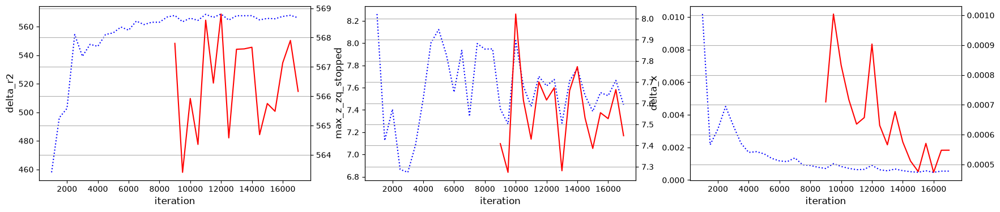

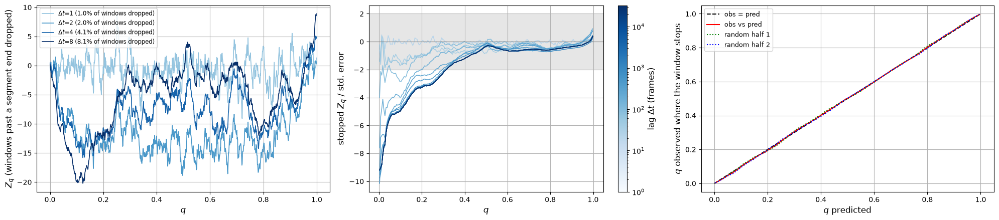

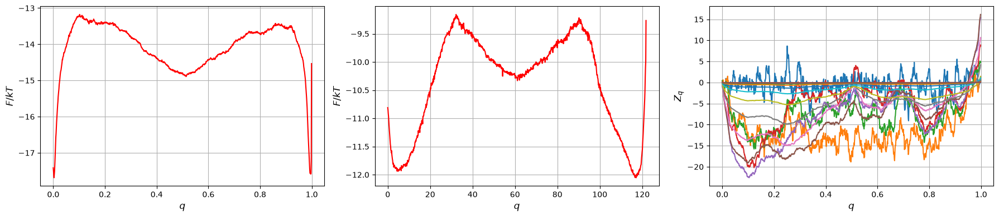

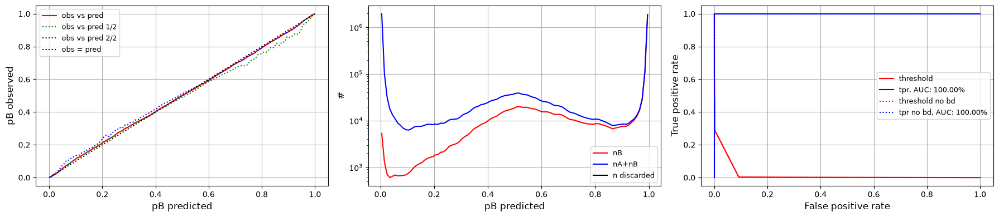

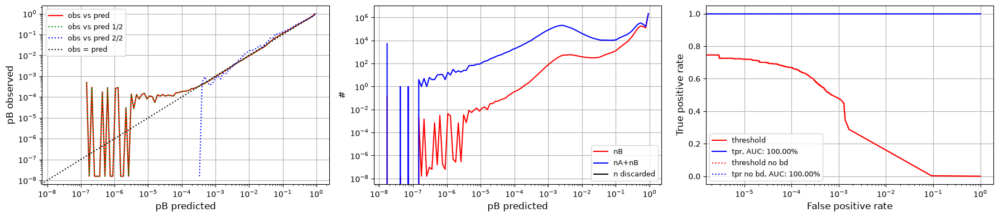

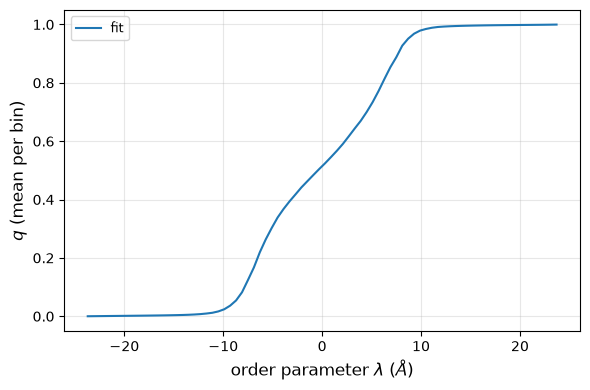

17000 iterations (main, envelope 0.01) 
#=17500, dr2=566.818, zqs_z=7.59638, sdzqs=6.84858, |dx|=0.00044403, time=12.9349
#=18000, dr2=567.468, zqs_z=7.5799, sdzqs=6.74807, |dx|=0.000442166, time=33.8817
#=18500, dr2=567.46, zqs_z=7.80483, sdzqs=6.66783, |dx|=0.000482864, time=53.2428
#=19000, dr2=566.746, zqs_z=7.81927, sdzqs=6.7518, |dx|=0.000323893, time=68.7389
#=19500, dr2=568.828, zqs_z=7.51849, sdzqs=6.7422, |dx|=0.000419995, time=89.7463
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it19500 ---


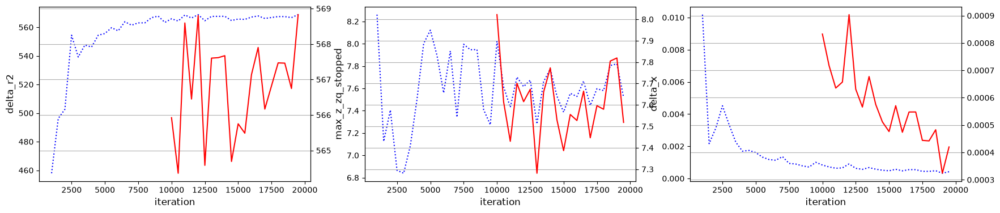

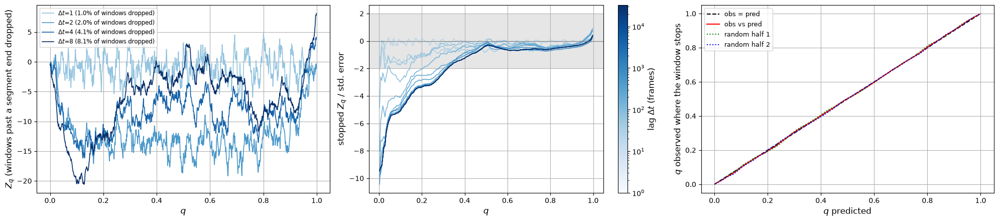

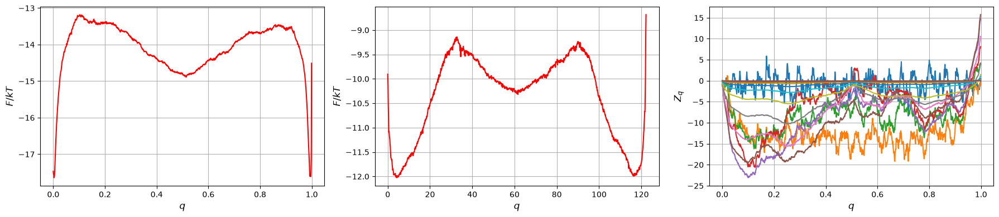

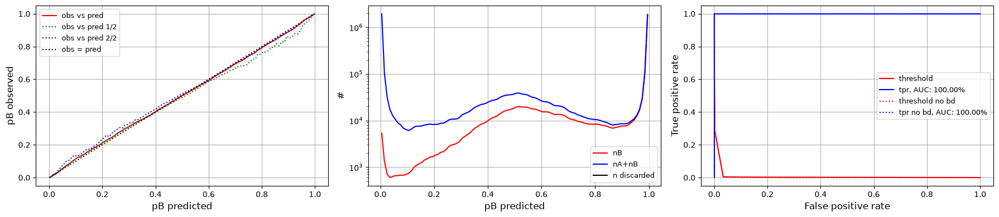

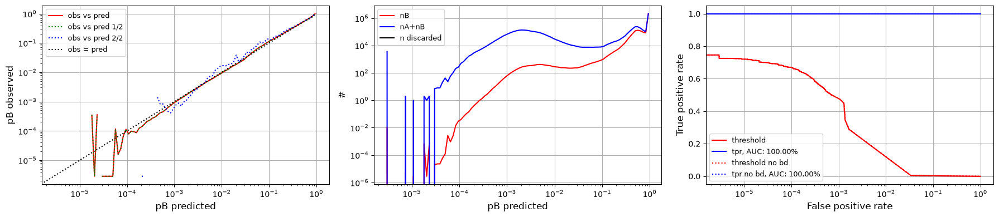

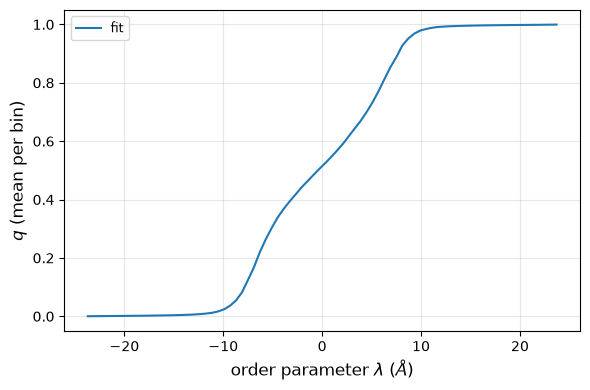

19500 iterations (main, envelope 0.01) 
#=20000, dr2=567.62, zqs_z=7.56869, sdzqs=6.93006, |dx|=0.000412534, time=11.8914
#=20500, dr2=566.35, zqs_z=7.41342, sdzqs=6.94508, |dx|=0.000357285, time=22.7867
#=21000, dr2=563.99, zqs_z=7.60065, sdzqs=6.872, |dx|=0.000445527, time=33.6819
#=21500, dr2=566.455, zqs_z=7.39896, sdzqs=6.89164, |dx|=0.000346213, time=44.5479
#=22000, dr2=567.418, zqs_z=7.48136, sdzqs=6.78598, |dx|=0.000351567, time=62.7789
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it22000 ---


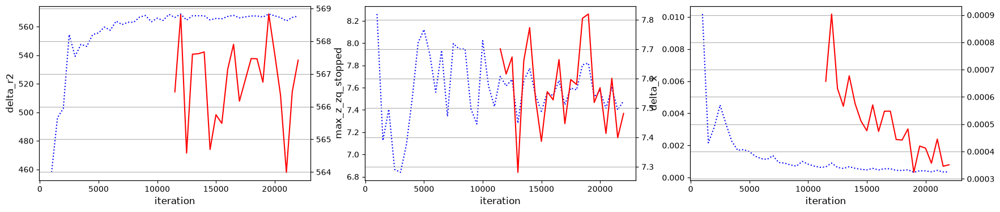

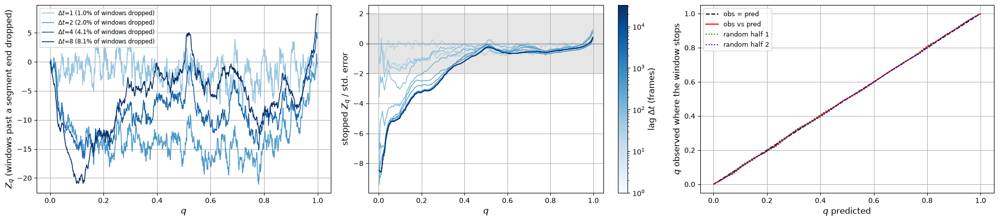

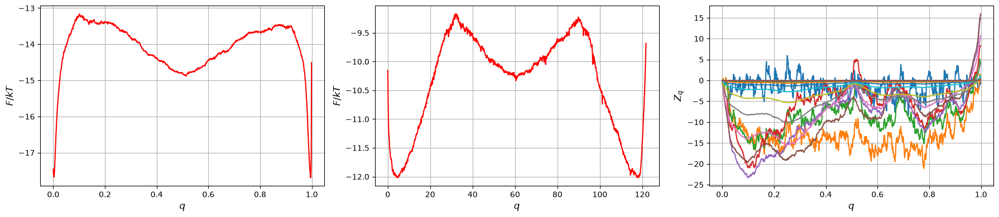

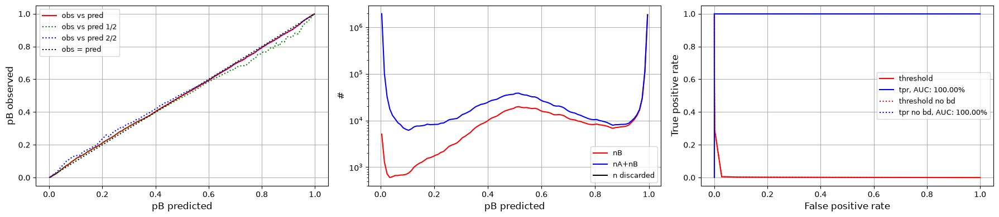

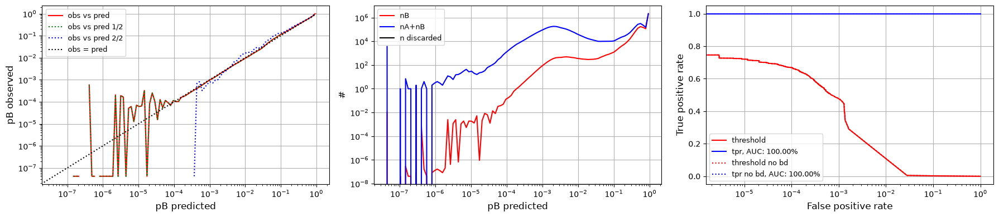

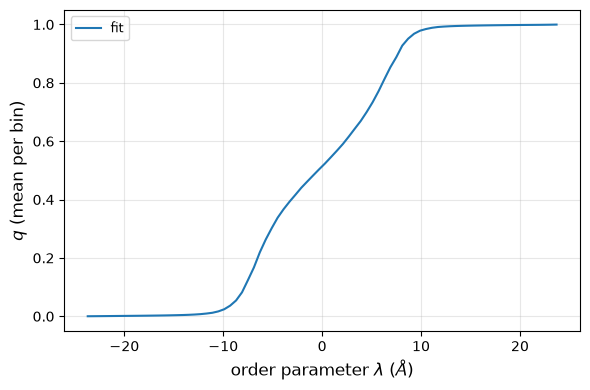

22000 iterations (main, envelope 0.01) 
#=22500, dr2=565.349, zqs_z=7.5063, sdzqs=6.89661, |dx|=0.000543425, time=14.2486
#=23000, dr2=569.642, zqs_z=7.4153, sdzqs=6.75045, |dx|=0.000611418, time=34.2262
#=23500, dr2=568.862, zqs_z=7.45107, sdzqs=6.85689, |dx|=0.000411421, time=54.7867
#=24000, dr2=567.875, zqs_z=7.16255, sdzqs=6.96313, |dx|=0.000627725, time=68.1184
#=24500, dr2=566.68, zqs_z=6.91198, sdzqs=6.90851, |dx|=0.000651723, time=89.2445
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it24500 ---


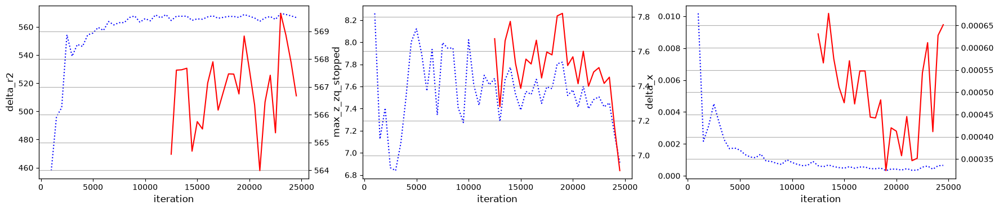

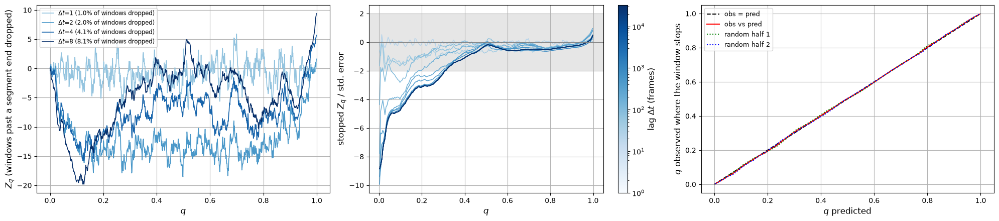

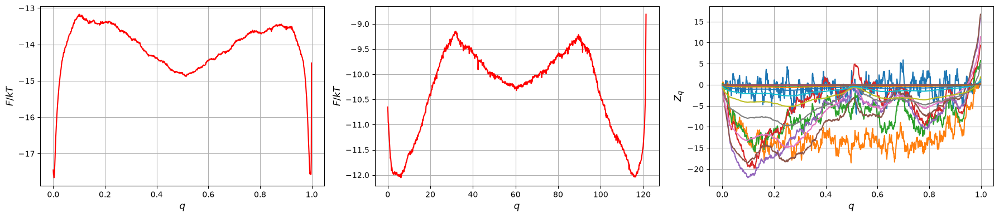

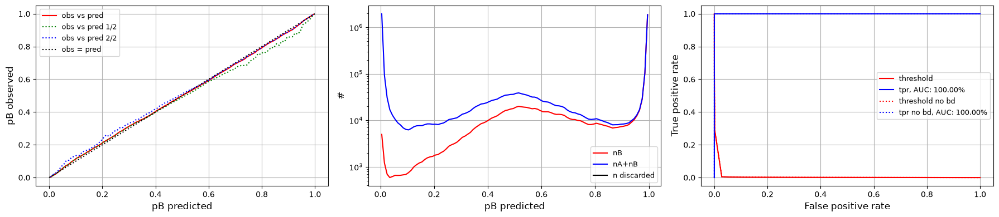

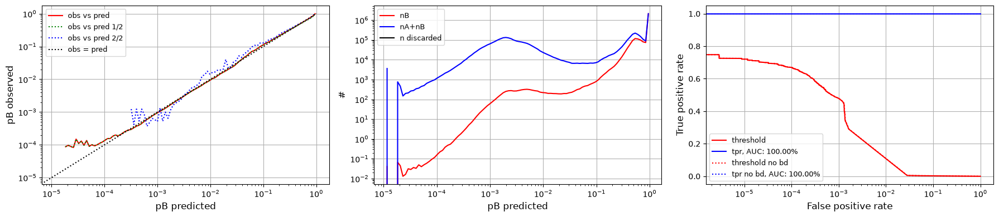

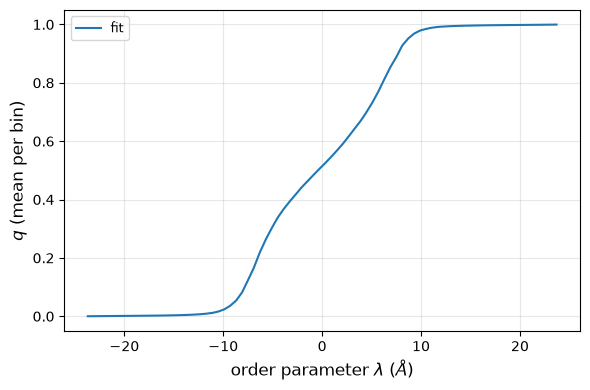

24500 iterations (main, envelope 0.01) 
#=25000, dr2=568.368, zqs_z=6.89379, sdzqs=6.93485, |dx|=0.000485736, time=15.3371
#=25500, dr2=567.333, zqs_z=7.34094, sdzqs=6.94541, |dx|=0.000402692, time=36.3973
#=26000, dr2=566.287, zqs_z=7.36441, sdzqs=6.96545, |dx|=0.000541212, time=49.9185
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124_0/it26000 ---


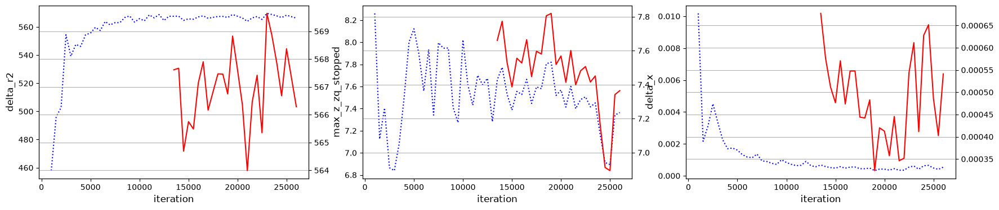

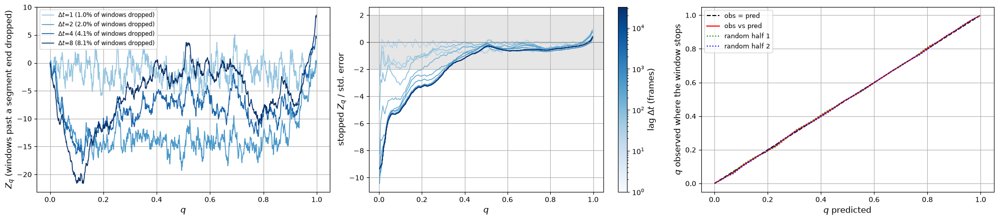

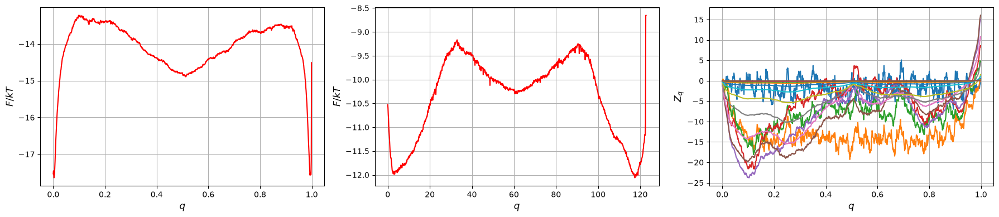

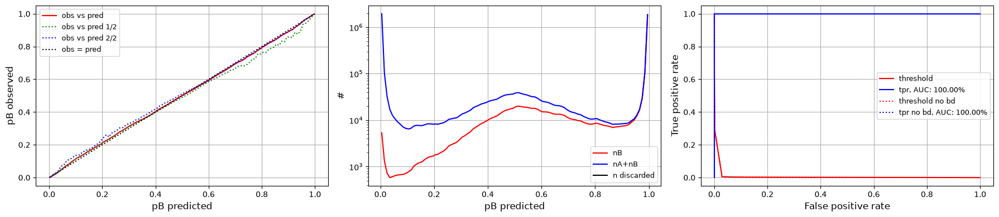

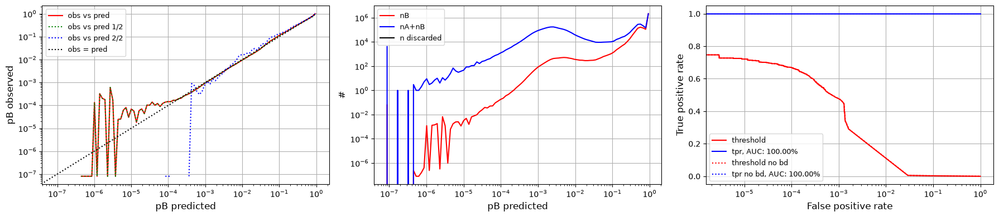

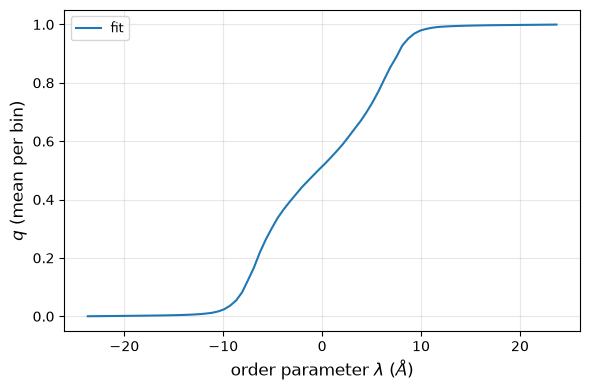

26000 iterations (main, envelope 0.01) 


In [11]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}      # weighting -> final q per seed, exact committor, fit time, zqs_z history

history=[0,1,2]
yr_type=['y(t-d),r(t-d)']

for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist0124_{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            delta_r2_max_change_allowed=10000,max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t)',
                            gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj_hist0124.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

===== fit, weighting rejections, seed 2 =====
#=500, dr2=420.592, zqs_z=21.2143, sdzqs=33.2211, |dx|=0.424817, time=19.2195
#=1000, dr2=499.273, zqs_z=8.36994, sdzqs=15.3241, |dx|=0.0192044, time=43.3116
#=1500, dr2=540.325, zqs_z=8.10411, sdzqs=14.1293, |dx|=0.0026222, time=67.2805
#=2000, dr2=553.202, zqs_z=9.53023, sdzqs=12.2314, |dx|=0.0022965, time=81.0587
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it2000 ---


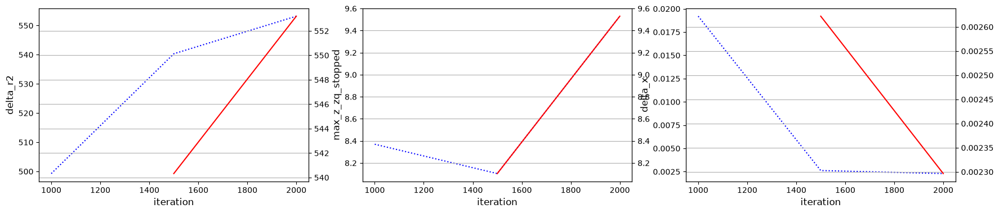

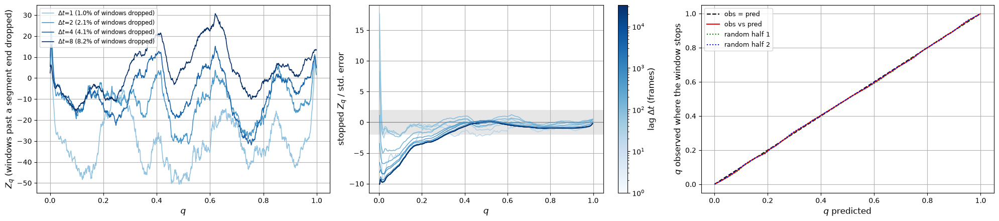

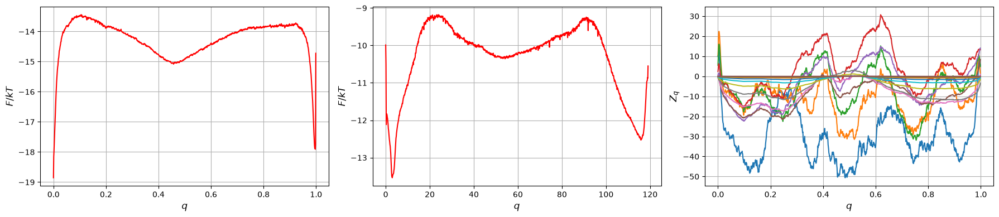

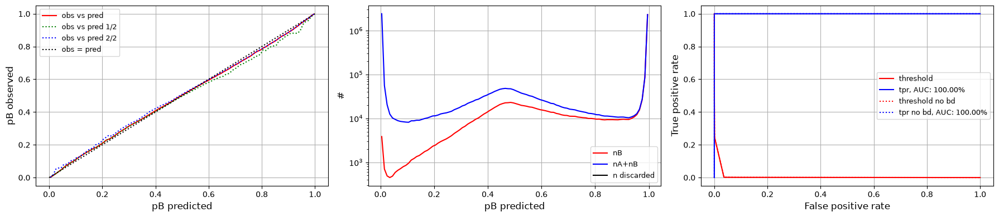

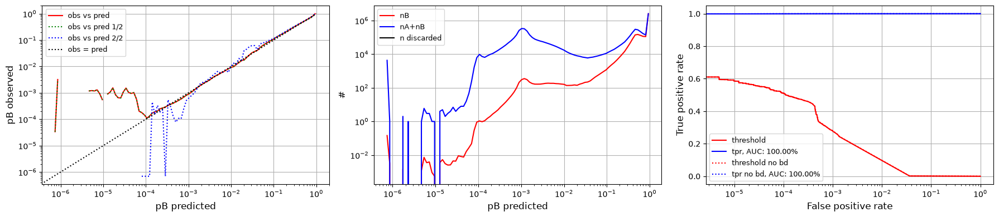

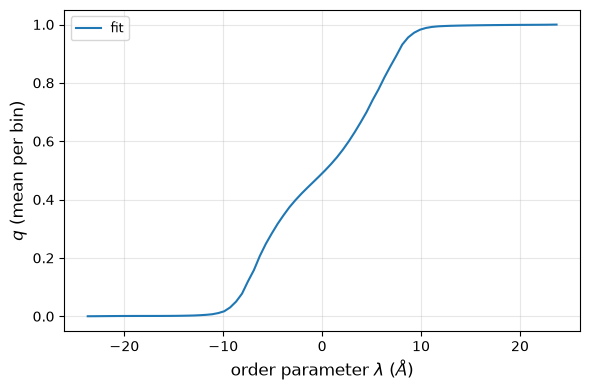

2000 iterations (warm-up, envelope 1) 
#=2500, dr2=602.277, zqs_z=8.58881, sdzqs=12.0175, |dx|=0.00384299, time=23.9558
#=3000, dr2=603.467, zqs_z=8.06052, sdzqs=10.0731, |dx|=0.00471398, time=48.0189
#=3500, dr2=602.335, zqs_z=8.79921, sdzqs=12.5172, |dx|=0.0058799, time=65.1705
#=4000, dr2=594.453, zqs_z=8.58482, sdzqs=10.6927, |dx|=0.00435791, time=80.0422
#=4500, dr2=622.423, zqs_z=8.23049, sdzqs=8.10624, |dx|=0.00317814, time=104.077
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it4500 ---


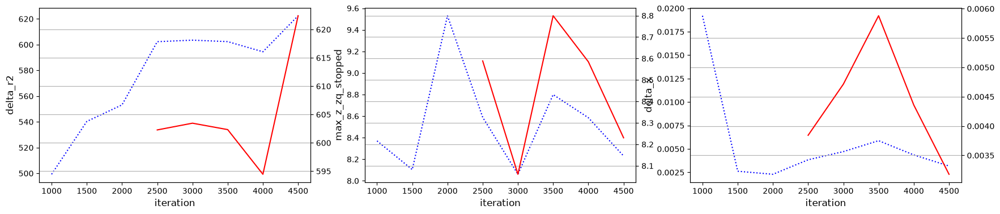

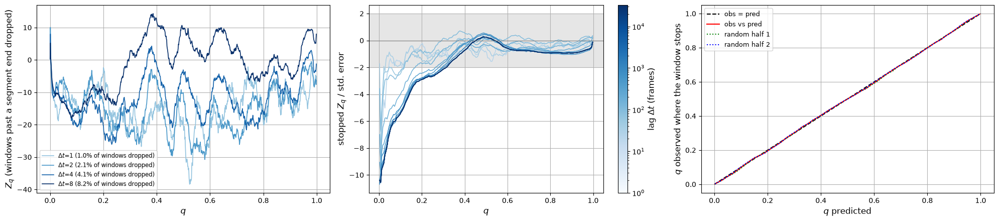

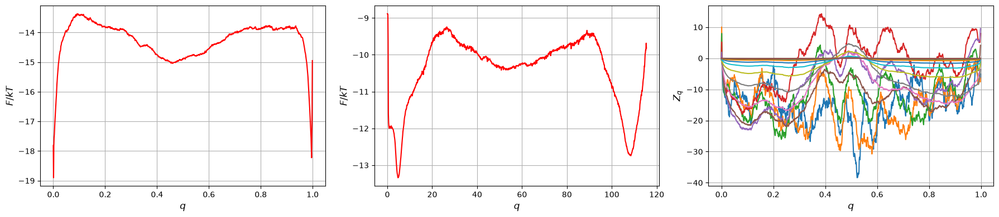

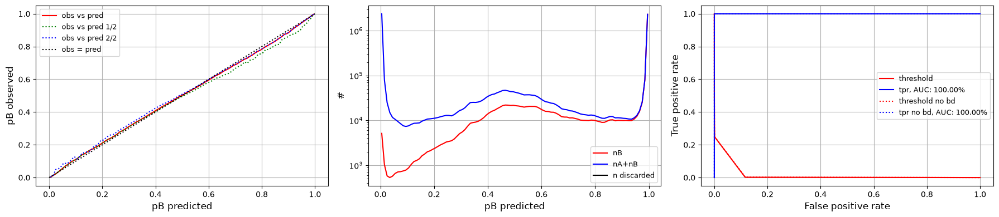

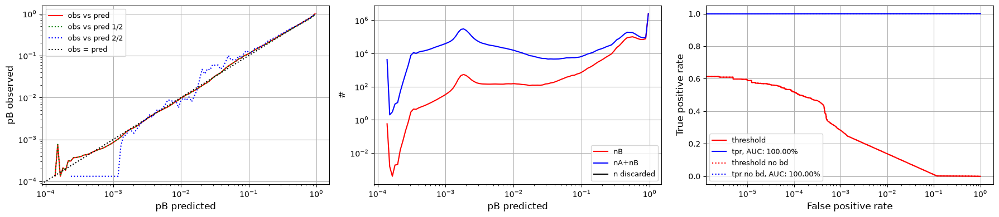

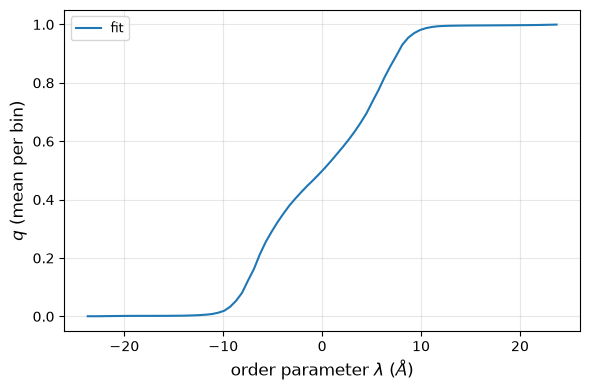

4500 iterations (main, envelope 0.01) 
#=5000, dr2=631.455, zqs_z=7.1138, sdzqs=7.36952, |dx|=0.00251898, time=22.761
#=5500, dr2=622.851, zqs_z=8.06492, sdzqs=10.8336, |dx|=0.00467992, time=36.5385
#=6000, dr2=627.134, zqs_z=7.14236, sdzqs=11.0094, |dx|=0.00584566, time=59.3442
#=6500, dr2=635.955, zqs_z=8.68178, sdzqs=6.5786, |dx|=0.00292056, time=83.434
#=7000, dr2=625.64, zqs_z=7.61156, sdzqs=5.98336, |dx|=0.00289311, time=106.269
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it7000 ---


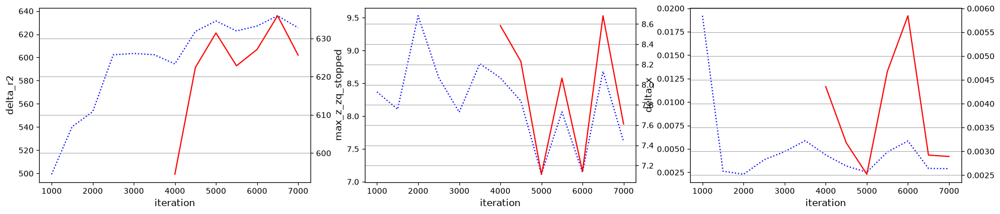

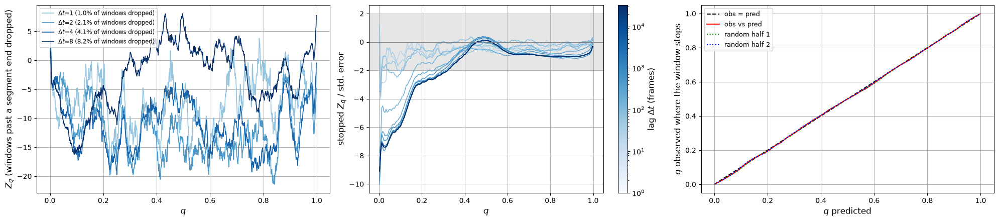

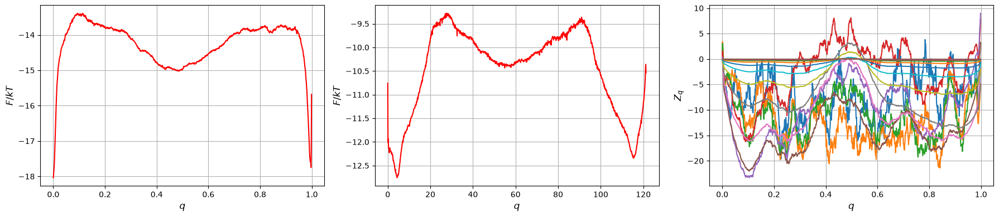

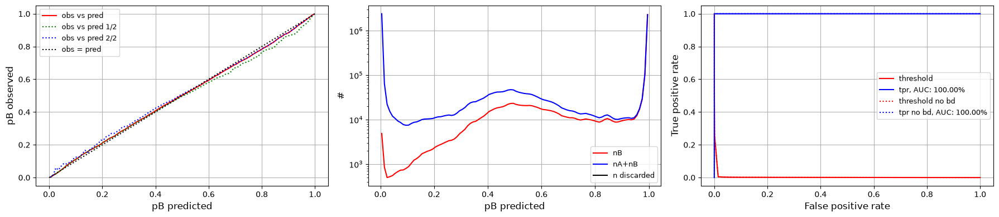

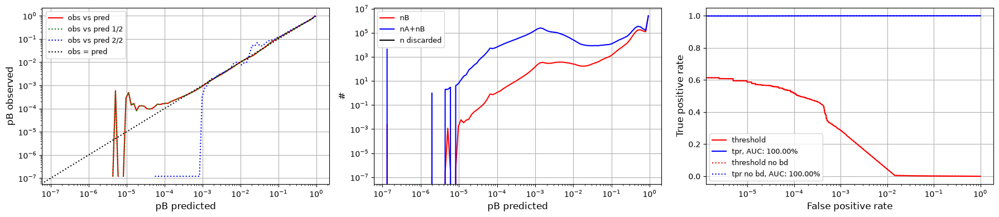

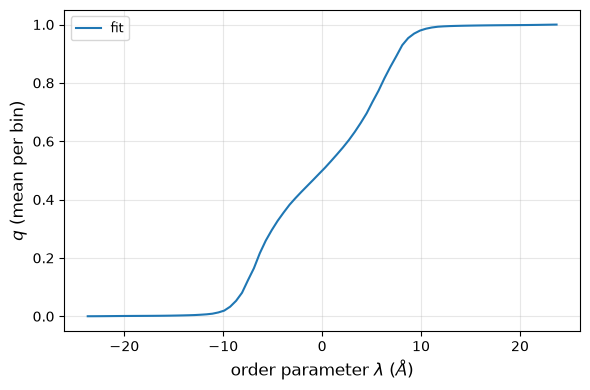

7000 iterations (main, envelope 0.01) 
#=7500, dr2=626.993, zqs_z=6.94887, sdzqs=7.32191, |dx|=0.00143455, time=14.4754
#=8000, dr2=623.326, zqs_z=7.68282, sdzqs=6.49203, |dx|=0.00148703, time=28.3104
#=8500, dr2=626.84, zqs_z=7.68245, sdzqs=6.71636, |dx|=0.00146316, time=44.1044
#=9000, dr2=632.591, zqs_z=7.4765, sdzqs=6.92483, |dx|=0.00137863, time=68.3465
#=9500, dr2=627.155, zqs_z=8.09846, sdzqs=6.25337, |dx|=0.00128107, time=92.5804
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it9500 ---


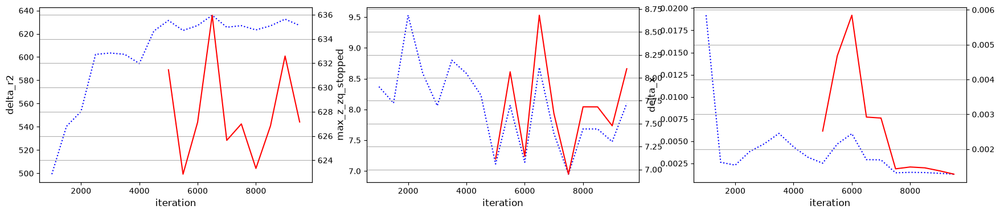

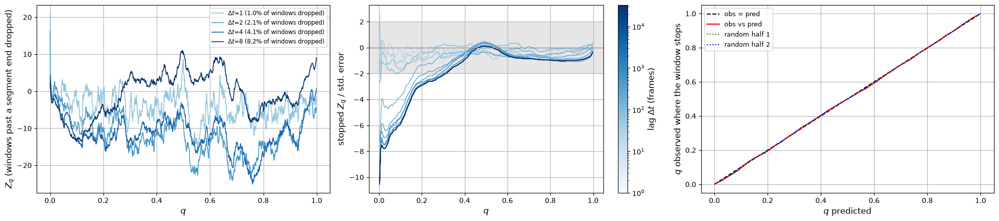

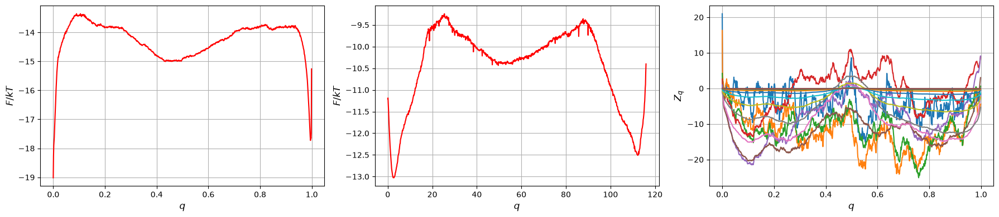

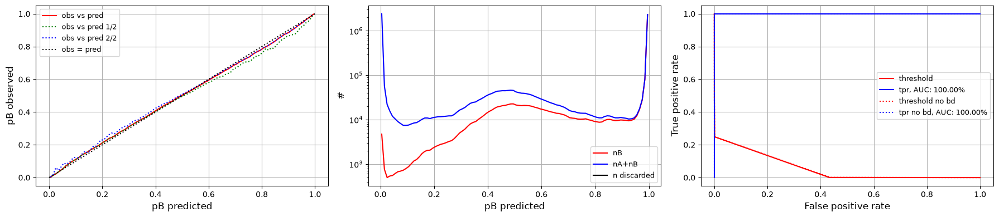

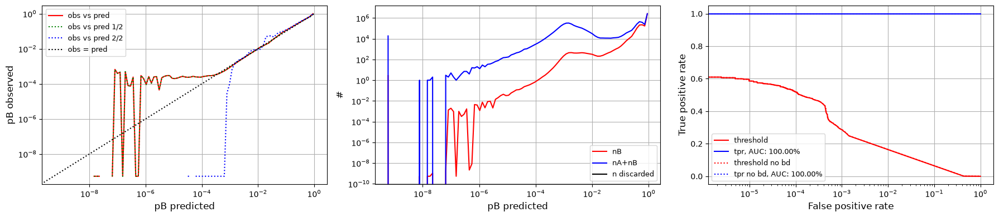

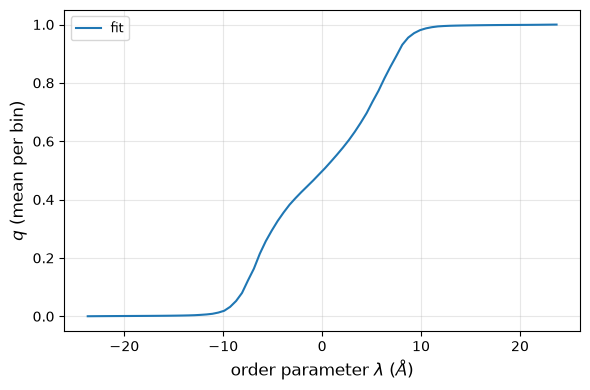

9500 iterations (main, envelope 0.01) 
#=10000, dr2=631.415, zqs_z=7.49921, sdzqs=6.85871, |dx|=0.00118238, time=13.7566
#=10500, dr2=630.019, zqs_z=7.54984, sdzqs=6.98736, |dx|=0.00138539, time=37.4801
#=11000, dr2=631.071, zqs_z=7.93505, sdzqs=6.5927, |dx|=0.00155526, time=61.5419
#=11500, dr2=626.221, zqs_z=9.65078, sdzqs=7.46124, |dx|=0.00235536, time=83.4695
#=12000, dr2=632.371, zqs_z=7.94505, sdzqs=7.71415, |dx|=0.00318915, time=97.46
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it12000 ---


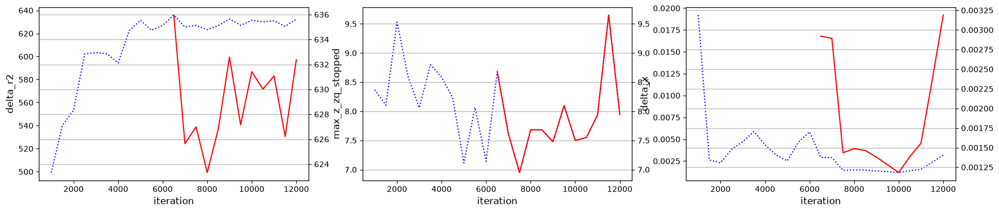

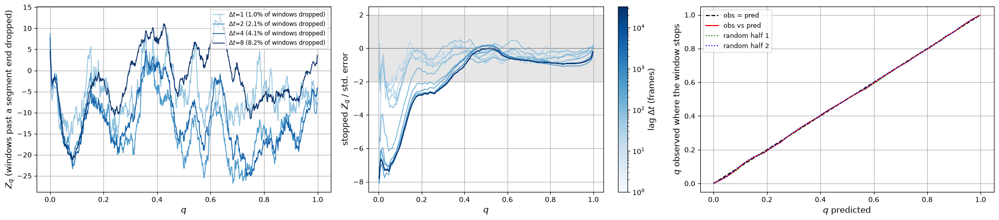

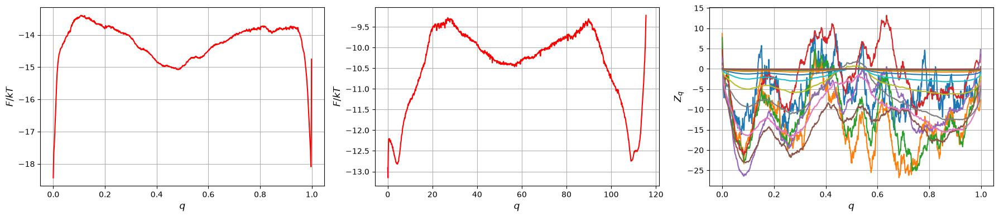

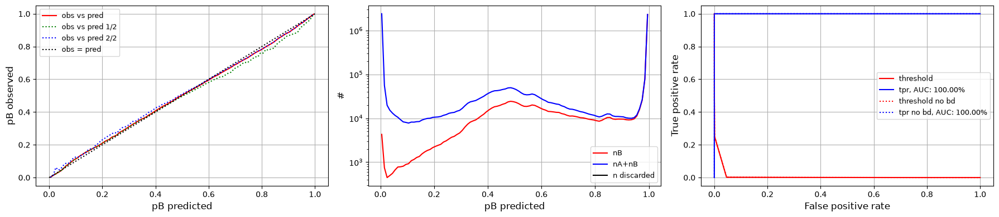

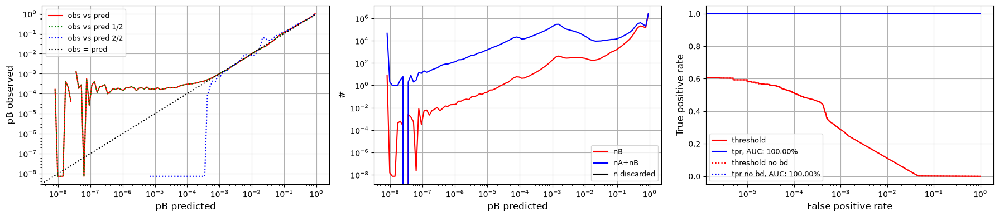

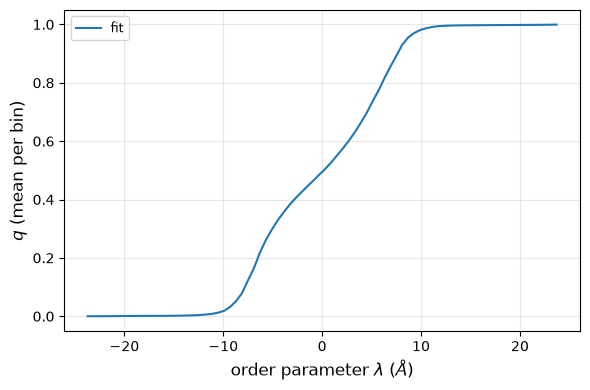

12000 iterations (main, envelope 0.01) 
#=12500, dr2=624.464, zqs_z=8.04369, sdzqs=6.50005, |dx|=0.00257905, time=23.9658
#=13000, dr2=633.701, zqs_z=8.14487, sdzqs=6.68601, |dx|=0.0017439, time=47.9415
#=13500, dr2=628.98, zqs_z=7.7387, sdzqs=6.34754, |dx|=0.00123826, time=61.8007
#=14000, dr2=624.598, zqs_z=7.56953, sdzqs=5.96026, |dx|=0.00138626, time=82.4243
#=14500, dr2=583.495, zqs_z=8.14413, sdzqs=18.4825, |dx|=0.00458648, time=106.401
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it14500 ---


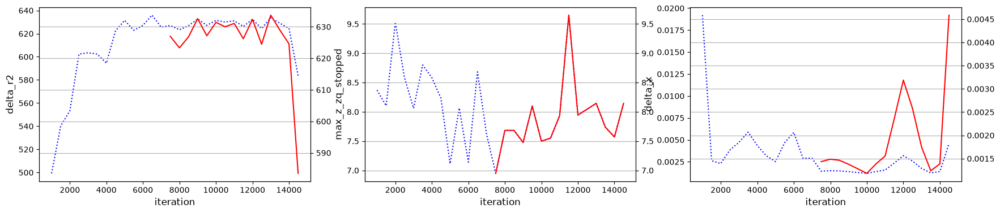

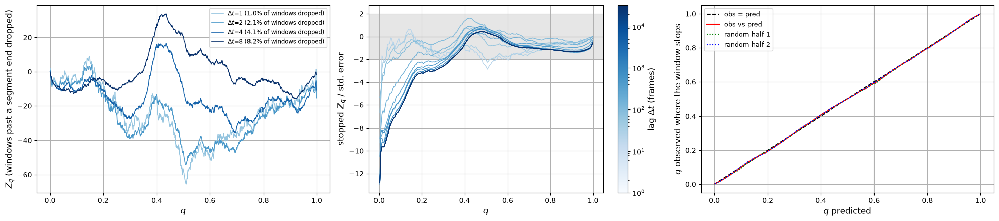

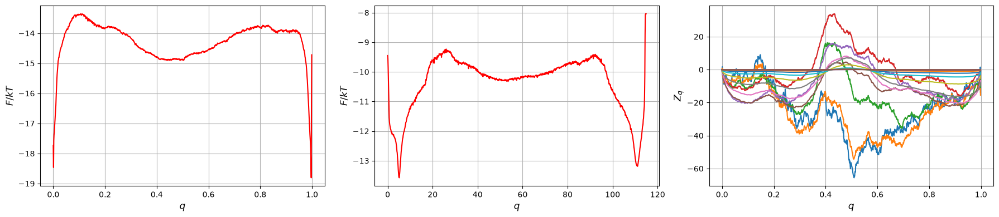

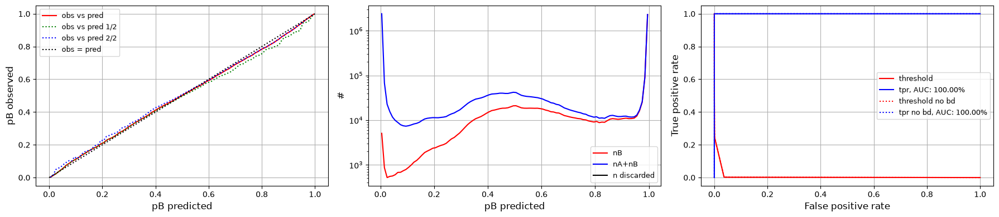

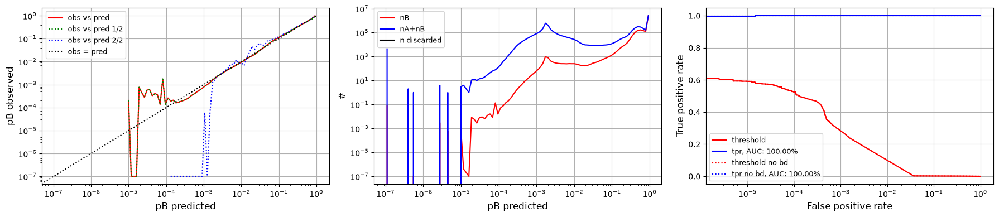

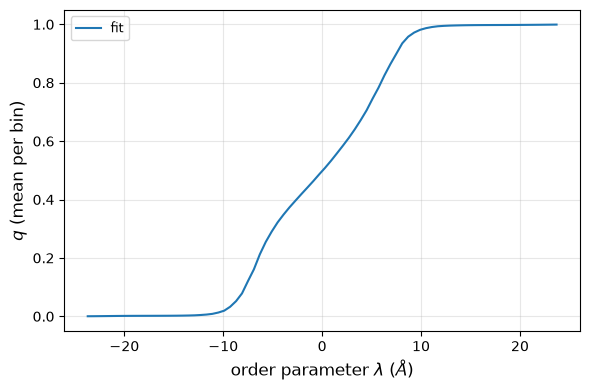

14500 iterations (main, envelope 0.01) 
#=15000, dr2=621.965, zqs_z=5.62892, sdzqs=9.42723, |dx|=0.00540839, time=17.0123
#=15500, dr2=639.041, zqs_z=8.5877, sdzqs=8.64912, |dx|=0.00478377, time=33.0323
#=16000, dr2=634.419, zqs_z=7.52101, sdzqs=6.99315, |dx|=0.00193361, time=57.0858
#=16500, dr2=640.892, zqs_z=7.77846, sdzqs=8.1062, |dx|=0.00236797, time=81.1731
#=17000, dr2=657.847, zqs_z=6.77958, sdzqs=11.63, |dx|=0.00586369, time=97.5182
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it17000 ---


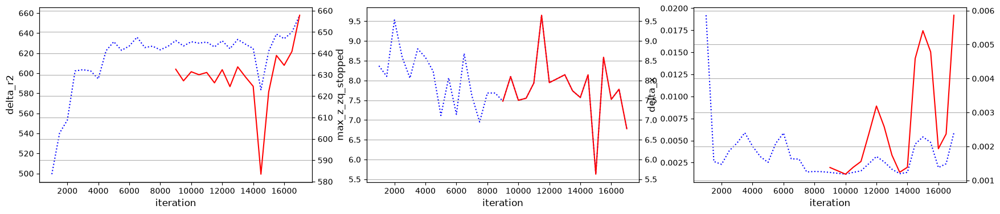

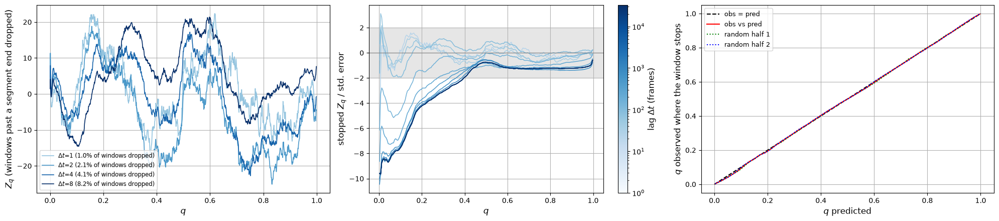

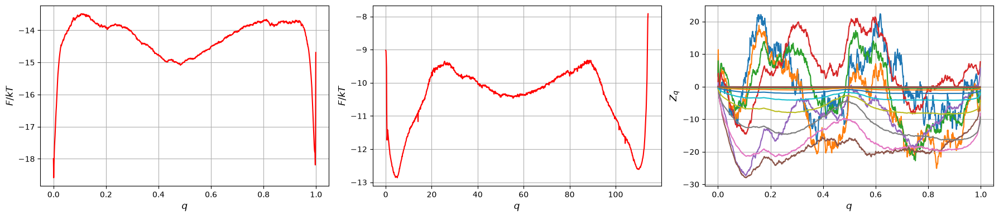

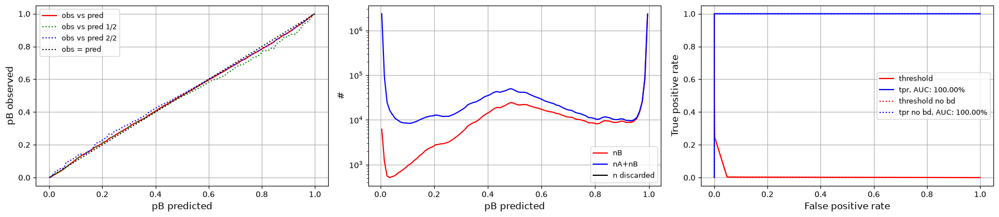

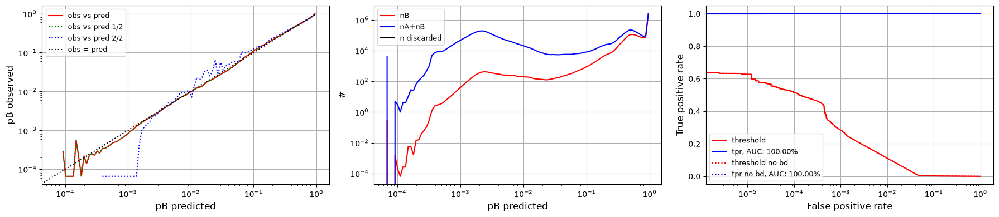

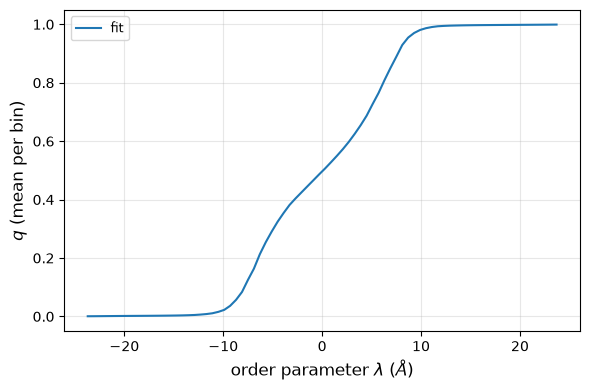

17000 iterations (main, envelope 0.01) 
#=17500, dr2=617.377, zqs_z=7.89318, sdzqs=9.37983, |dx|=0.00567536, time=13.737
#=18000, dr2=627.466, zqs_z=9.07835, sdzqs=6.56364, |dx|=0.00360563, time=28.636
#=18500, dr2=635.778, zqs_z=5.98617, sdzqs=5.69658, |dx|=0.00174303, time=49.911
#=19000, dr2=635.089, zqs_z=6.70536, sdzqs=5.78023, |dx|=0.00177011, time=74.0111
#=19500, dr2=632.192, zqs_z=6.84126, sdzqs=5.87679, |dx|=0.00159065, time=97.3348
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it19500 ---


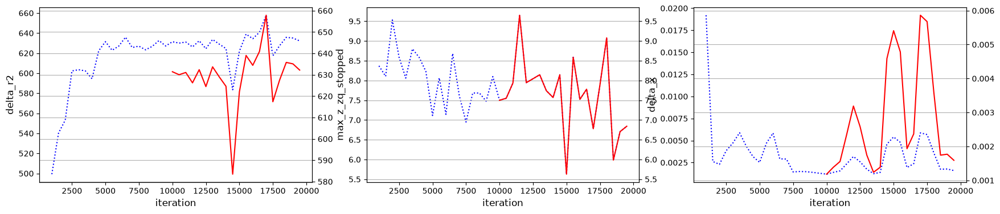

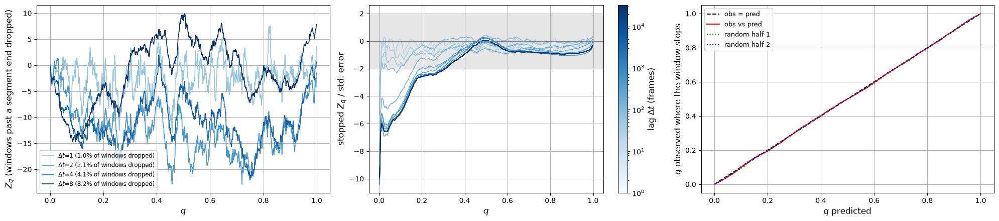

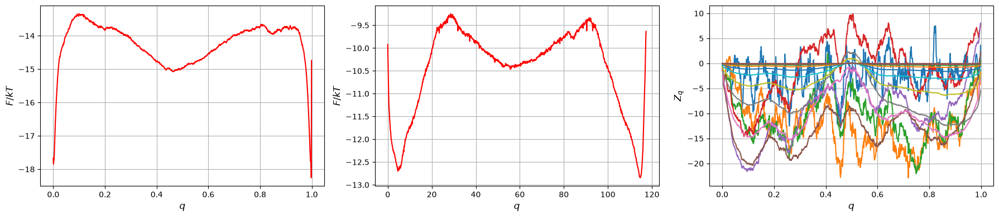

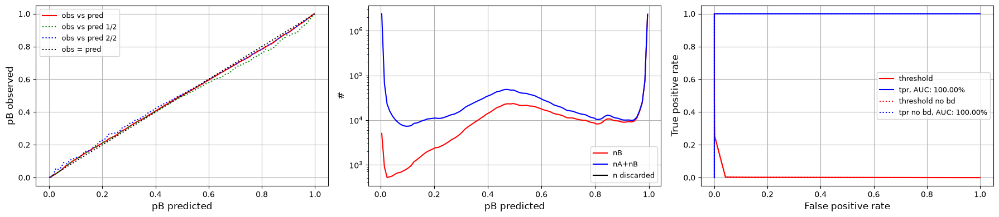

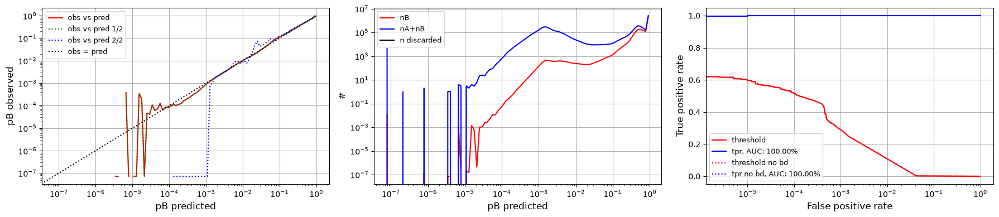

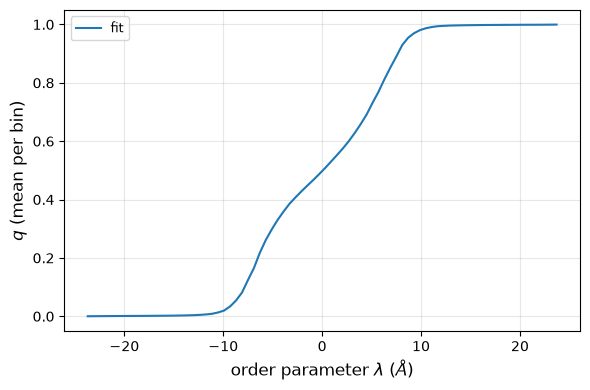

19500 iterations (main, envelope 0.01) 
#=20000, dr2=635.934, zqs_z=6.5367, sdzqs=6.29397, |dx|=0.000981722, time=17.7536
#=20500, dr2=630.557, zqs_z=7.00421, sdzqs=5.8289, |dx|=0.000889714, time=41.823
#=21000, dr2=631.712, zqs_z=6.66633, sdzqs=5.86038, |dx|=0.00102014, time=65.9012
#=21500, dr2=633.227, zqs_z=6.67857, sdzqs=5.5039, |dx|=0.0010338, time=80.5906
#=22000, dr2=632.891, zqs_z=6.7487, sdzqs=5.60963, |dx|=0.000974717, time=99.5452
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it22000 ---


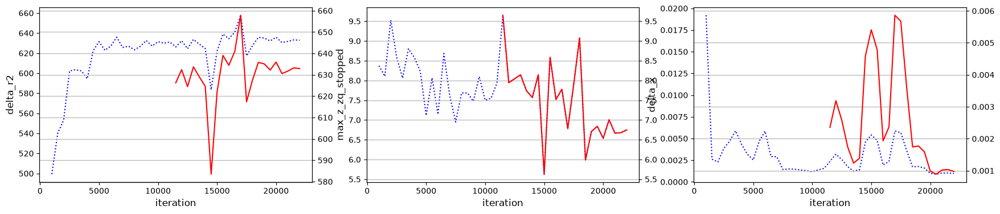

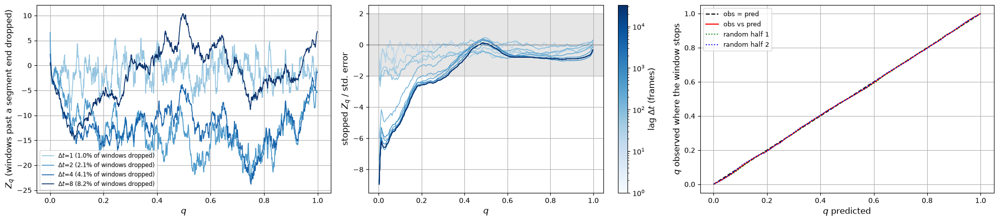

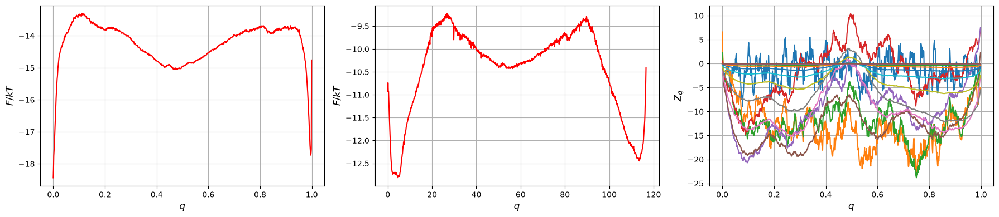

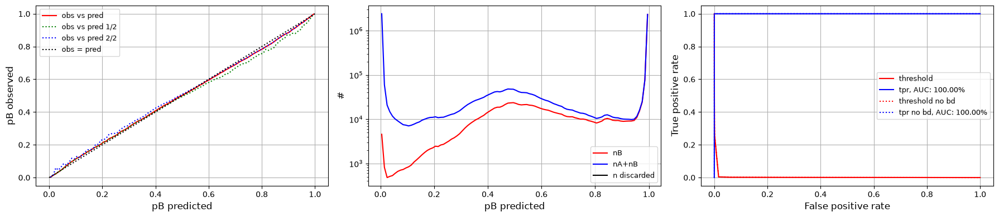

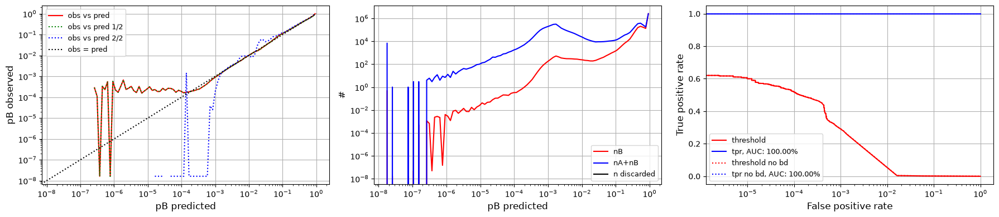

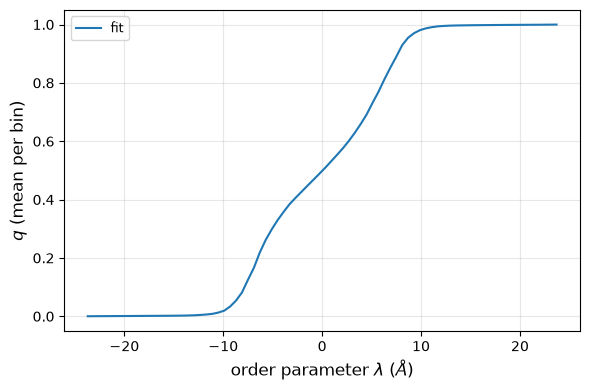

22000 iterations (main, envelope 0.01) 
#=22500, dr2=629.91, zqs_z=6.59417, sdzqs=5.6314, |dx|=0.000801117, time=23.7402
#=23000, dr2=632.506, zqs_z=6.47256, sdzqs=5.59334, |dx|=0.000801948, time=42.3257
#=23500, dr2=632.017, zqs_z=6.57354, sdzqs=5.72372, |dx|=0.000703919, time=56.9695
#=24000, dr2=631.89, zqs_z=6.73628, sdzqs=5.95623, |dx|=0.000882364, time=81.0052
#=24500, dr2=628.605, zqs_z=6.29294, sdzqs=5.88996, |dx|=0.000855554, time=105.193
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it24500 ---


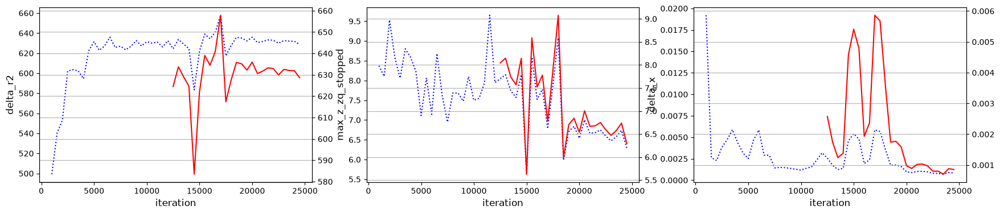

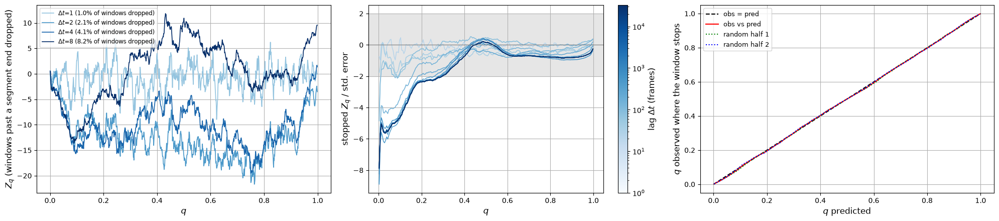

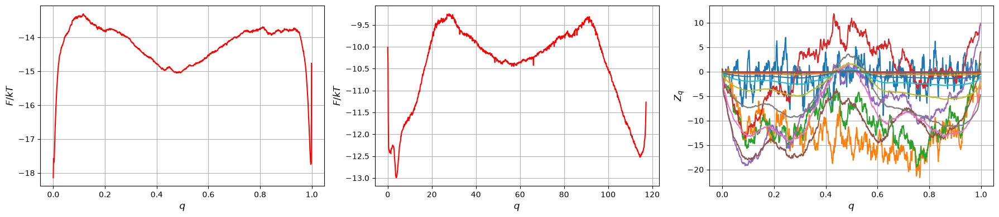

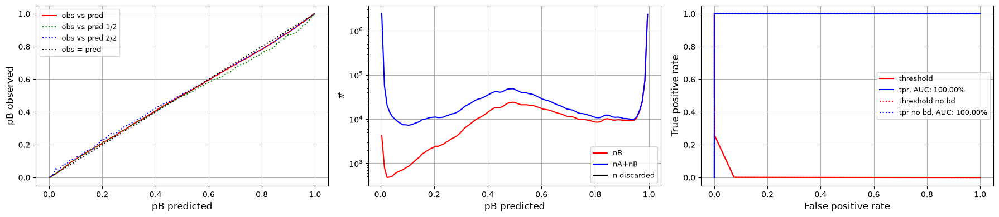

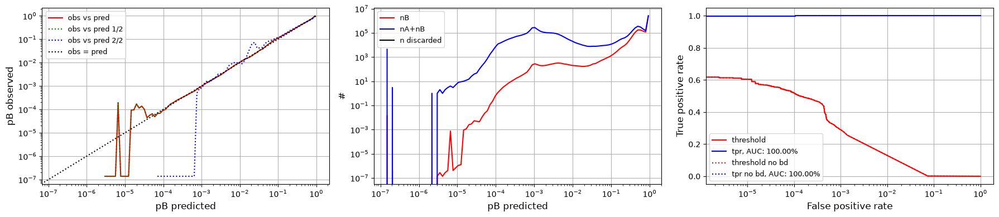

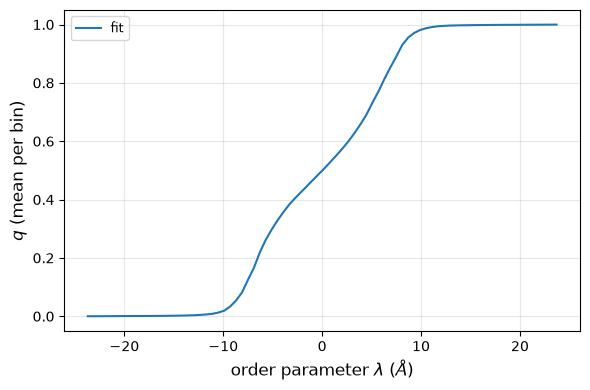

24500 iterations (main, envelope 0.01) 
#=25000, dr2=629.055, zqs_z=6.29001, sdzqs=5.63373, |dx|=0.00114972, time=13.6876
#=25500, dr2=632.646, zqs_z=6.63965, sdzqs=5.62326, |dx|=0.00113827, time=37.5475
#=26000, dr2=631.52, zqs_z=6.43886, sdzqs=5.58238, |dx|=0.000665457, time=61.5837
#=26500, dr2=630.499, zqs_z=6.27686, sdzqs=5.66596, |dx|=0.000618731, time=83.4638
#=27000, dr2=629.657, zqs_z=6.7095, sdzqs=5.70509, |dx|=0.000563457, time=97.4205
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it27000 ---


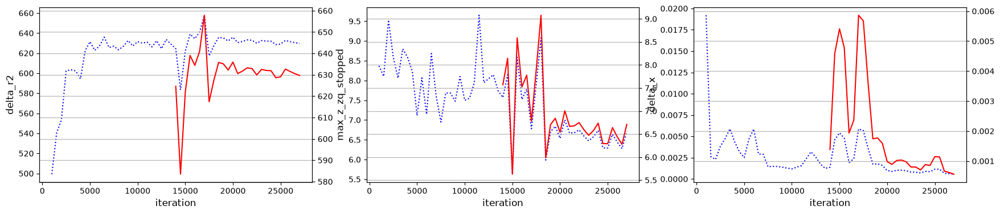

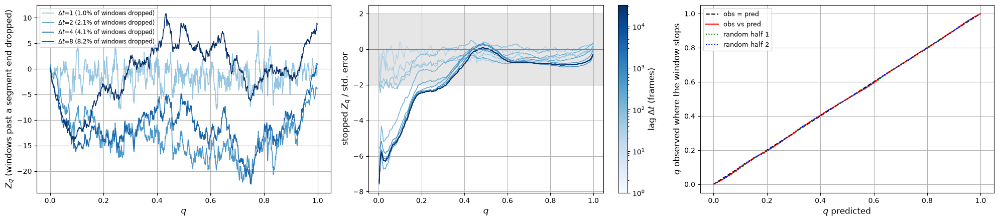

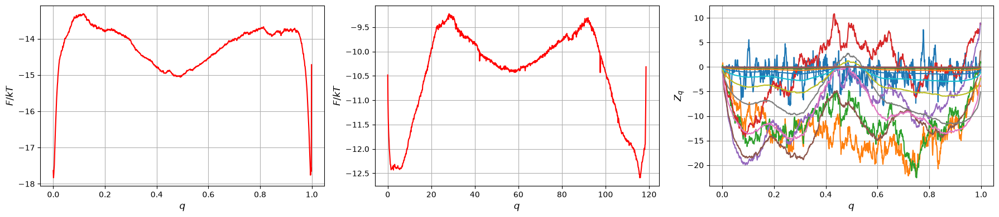

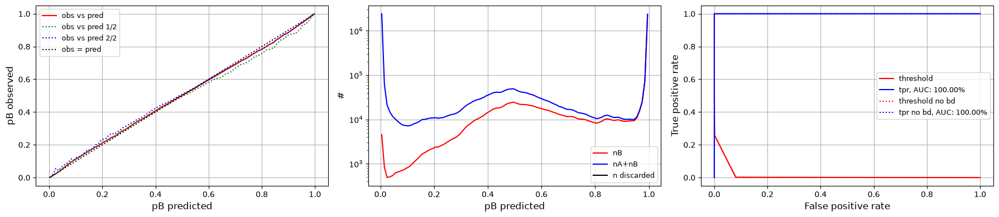

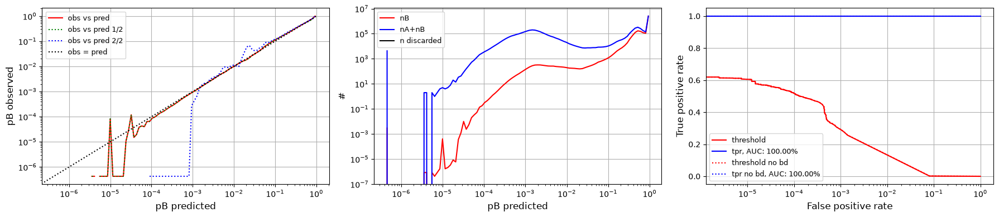

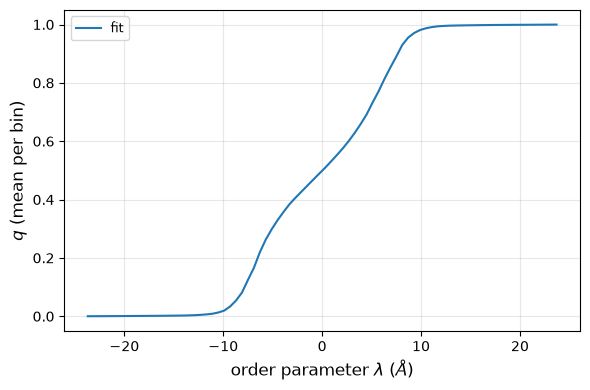

27000 iterations (main, envelope 0.01) 
#=27500, dr2=630.3, zqs_z=6.38458, sdzqs=5.70694, |dx|=0.000423733, time=13.3217
#=28000, dr2=630.267, zqs_z=6.52929, sdzqs=5.71978, |dx|=0.000597461, time=29.4715
#=28500, dr2=628.994, zqs_z=6.27579, sdzqs=5.89676, |dx|=0.00128868, time=53.5733
#=29000, dr2=631.816, zqs_z=6.23691, sdzqs=5.58163, |dx|=0.00141748, time=77.5944
#=29500, dr2=630.111, zqs_z=6.33219, sdzqs=6.02296, |dx|=0.00113122, time=94.6582
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it29500 ---


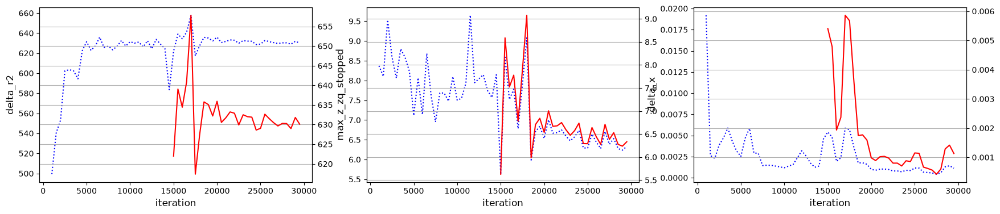

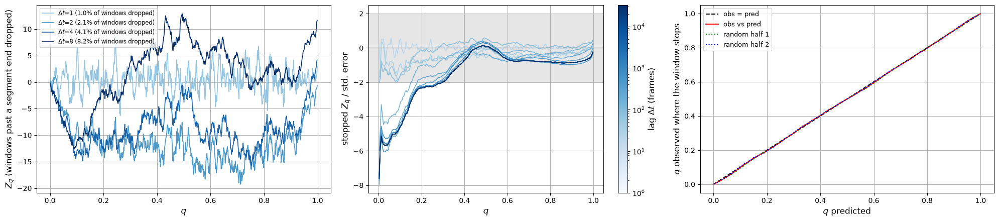

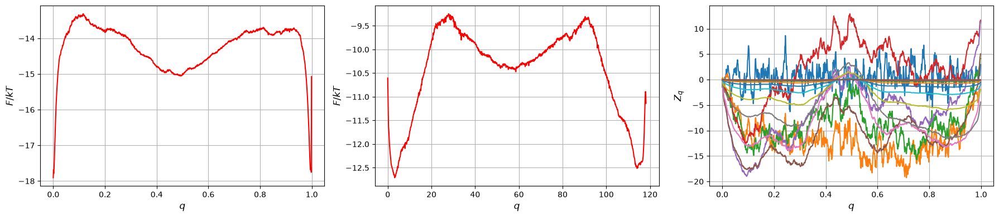

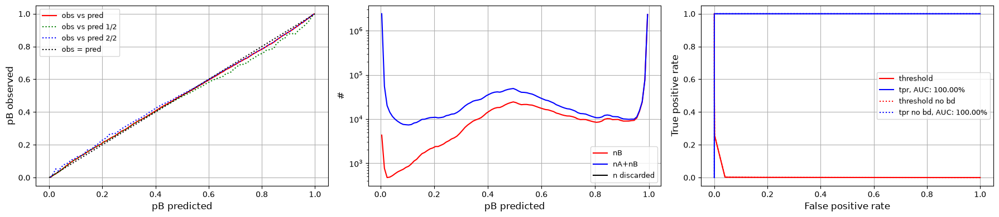

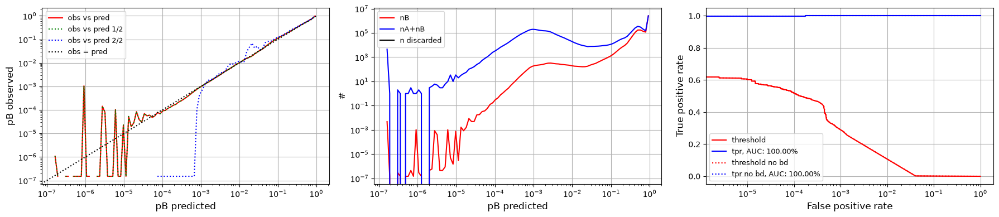

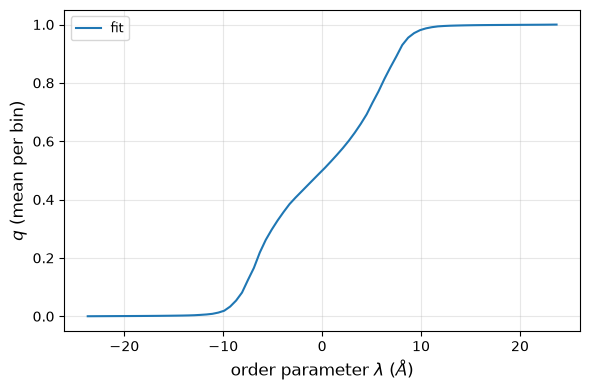

29500 iterations (main, envelope 0.01) 
#=30000, dr2=630.223, zqs_z=6.48181, sdzqs=5.48078, |dx|=0.000890516, time=23.2425
#=30500, dr2=628.754, zqs_z=6.58656, sdzqs=5.44609, |dx|=0.000587477, time=47.5151
#=31000, dr2=627.364, zqs_z=6.58606, sdzqs=5.85465, |dx|=0.000989882, time=69.4671
#=31500, dr2=627.346, zqs_z=6.26327, sdzqs=5.84004, |dx|=0.000873449, time=83.4893
#=32000, dr2=628.79, zqs_z=6.08473, sdzqs=5.50285, |dx|=0.000642265, time=107.564
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it32000 ---


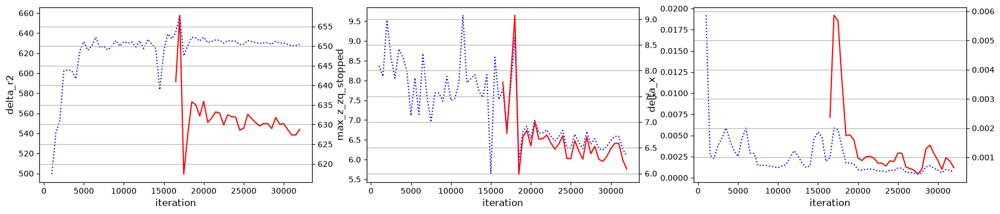

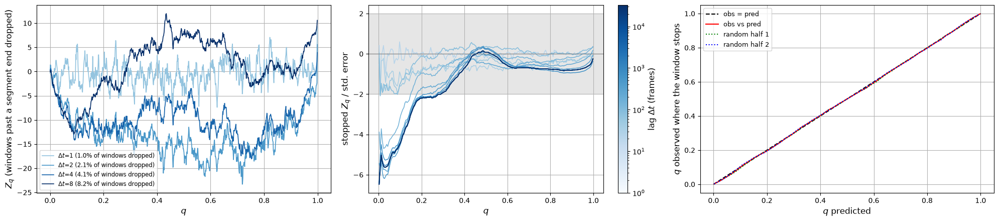

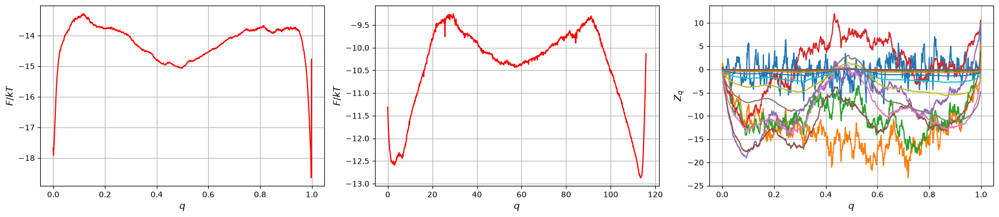

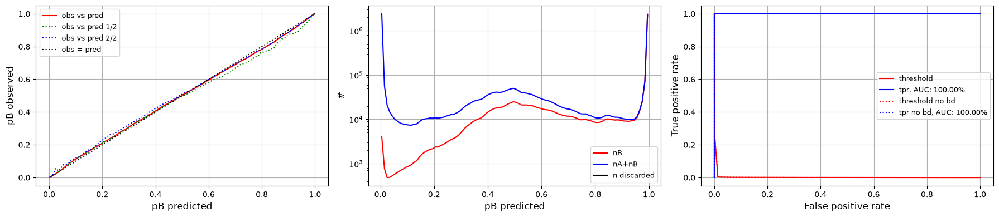

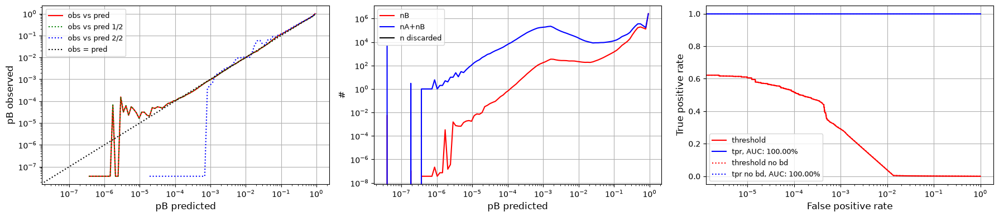

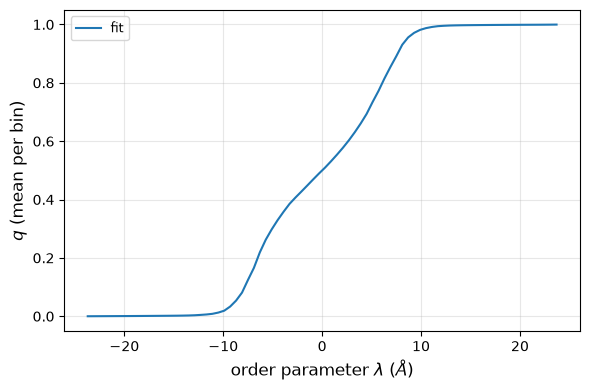

32000 iterations (main, envelope 0.01) 
#=32500, dr2=628.456, zqs_z=6.24032, sdzqs=5.77211, |dx|=0.000560394, time=23.315
#=33000, dr2=627.321, zqs_z=6.20221, sdzqs=5.5729, |dx|=0.000500381, time=37.3471
#=33500, dr2=627.696, zqs_z=6.57678, sdzqs=5.9567, |dx|=0.000469503, time=57.8609
#=34000, dr2=627.52, zqs_z=6.26034, sdzqs=5.72551, |dx|=0.00052153, time=81.9289
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/it34000 ---


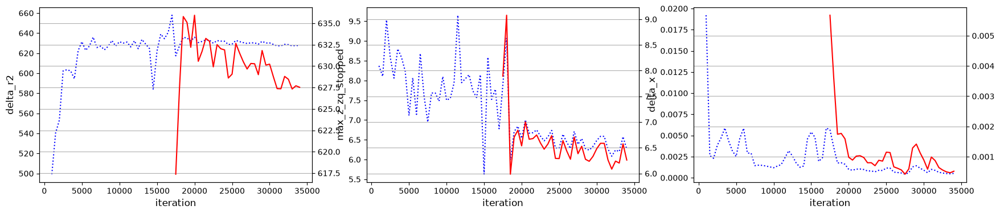

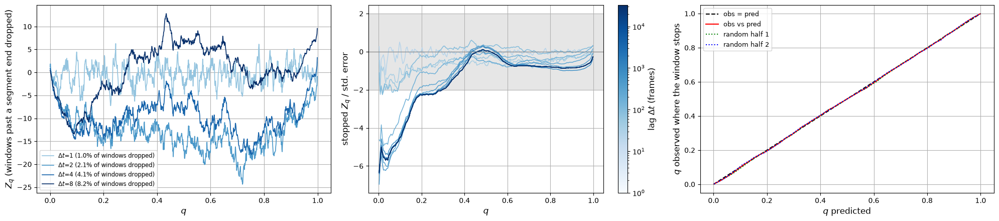

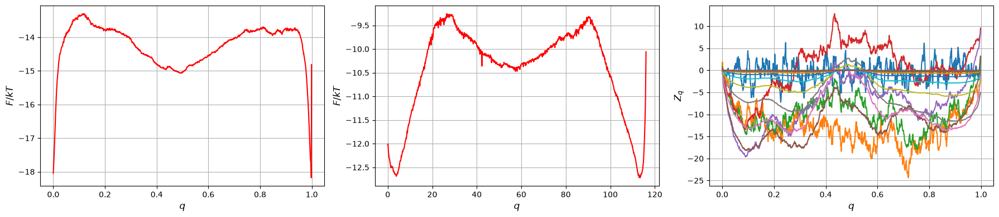

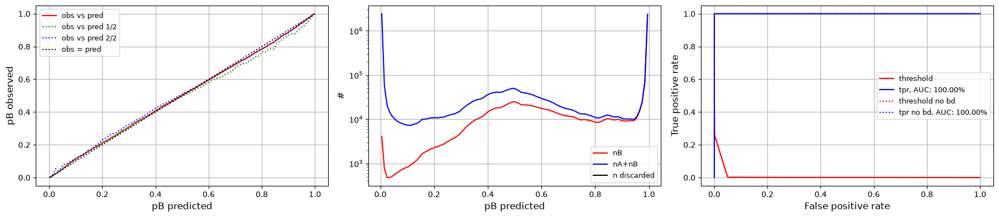

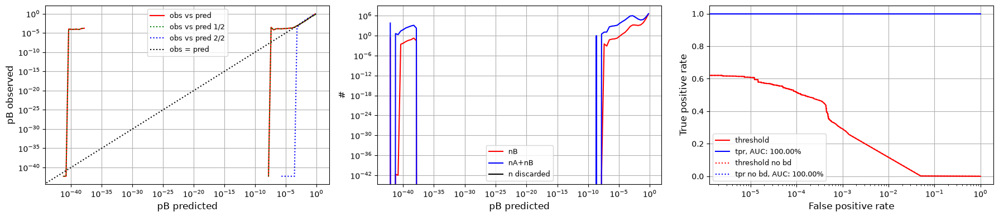

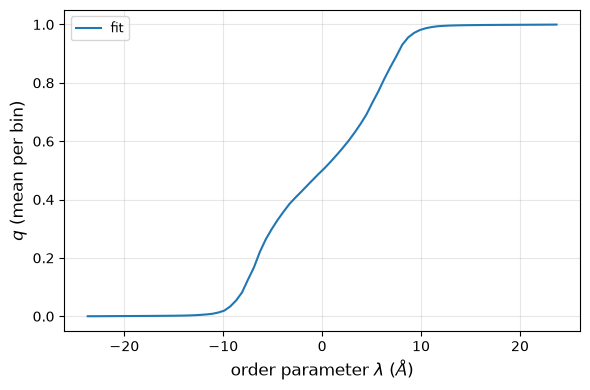

34000 iterations (main, envelope 0.01) 


In [9]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}      # weighting -> final q per seed, exact committor, fit time, zqs_z history

history=[0,1,2,4]
yr_type=['y(t-d),r(t-d)']

for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seedhist0124yr_{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t0)',
                            delta_r2_max_change_allowed=10000,max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y,
                            history_delta_t=history, history_type=yr_type, history_shift_type='r(t0)',
                            gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj_hist0124.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        #del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

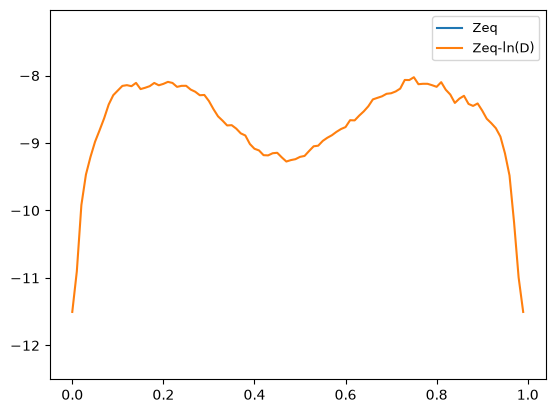

In [10]:
def comp_Zeq(r_traj, nbins=100, i_traj=None, w_traj=None, start=0, end=-1):
    r_traj = cp.asarray(r_traj)  # removed * w_traj here
    r_min = cp.min(r_traj)
    r_max = cp.max(r_traj)
    bin_edges = cp.linspace(r_min, r_max, nbins + 1)
 
    delta_r = r_traj[1:] - r_traj[:-1]
    It = cp.asarray(i_traj[1:] == i_traj[:-1])
    if w_traj is not None:
        It = It * cp.asarray(w_traj)[:-1]  # apply path weights to the step mask instead

    bin_indices_r = cp.searchsorted(bin_edges, r_traj, side='right') - 1
    bin_indices_r = cp.clip(bin_indices_r, 0, len(bin_edges) - 2)
    hist = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It * delta_r)[start:end]
    hist2 = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It * delta_r**2)[start:end]
    n = cp.bincount(bin_indices_r[:-1], minlength=nbins + 1, weights=It)[start:end]
    n += 1
    drift = (hist / n)
    D = (hist2 / n - drift**2) / 2 + 1e-5
    Zc1 = cp.cumsum(drift / D) * (bin_edges[1] - bin_edges[0])
    return bin_edges[start:end], Zc1, D

bins, zeq, D = comp_Zeq(q.r_traj, i_traj=q.i_traj, w_traj=d.path_weights)
plt.plot(bins.get(), zeq.get(), label='Zeq')
plt.plot(bins.get(), (-zeq +cp.log(D)).get(), label='Zeq-ln(D)')
plt.ylim((-zeq +cp.log(D)).get().min()-1,(-zeq +cp.log(D)).get().max()+1)
plt.legend()

0.2


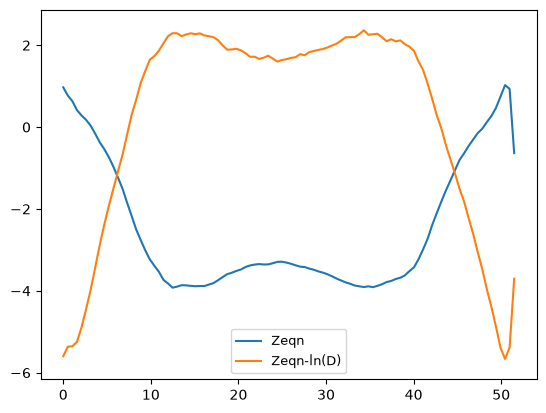

In [12]:
dt=0.2
print(dt)
qn_traj = optimalrcs.plots.transform_q2qn(q.r_traj, i_traj=q.i_traj, t_traj=q.t_traj, w_traj=cp.asarray(d.path_weights), dt_sim=dt)

binsn, zeqn, Dn = comp_Zeq(qn_traj, i_traj=q.i_traj, w_traj=d.path_weights)
plt.plot(binsn.get(), zeqn.get(), label='Zeqn')
plt.plot(binsn.get(), (-zeqn + cp.log(Dn)).get(), label='Zeqn-ln(D)')
x= binsn.get()
plt.ylim((-zeqn + cp.log(Dn)).get().min()-0.5,(-zeqn + cp.log(Dn)).get().max()+0.5)
plt.legend()

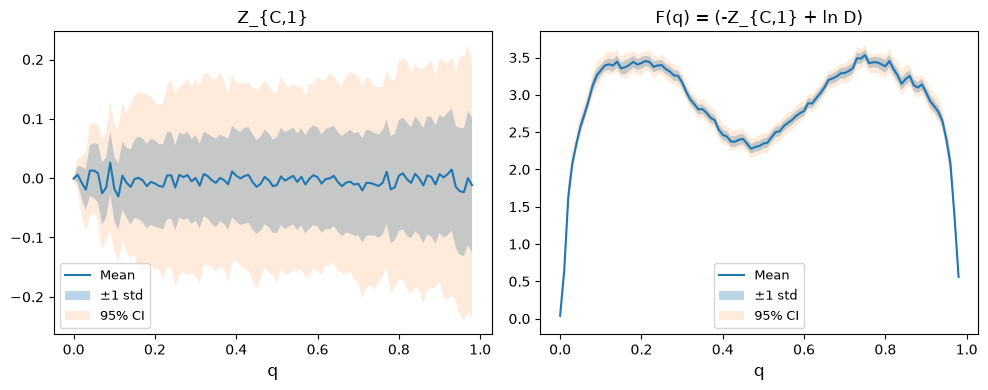

In [13]:
def bootstrap_Zeq(r_traj, i_traj, w_traj, n_boot=50, nbins=100, start=0, end=-1):
    i_gpu = cp.asarray(i_traj)
    _, inv = cp.unique(i_gpu, return_inverse=True)
    n_segs = int(inv.max()) + 1

    bins, _, _ = comp_Zeq(r_traj, nbins=nbins, i_traj=i_traj, w_traj=w_traj, start=start, end=end)
    zeq_boots, feq_boots = [], []

    for _ in range(n_boot):
        # Draw Poisson(1) multiplicity per trajectory piece and broadcast to frames
        seg_mult = cp.random.poisson(1.0, size=n_segs)
        w_boot = cp.asarray(w_traj) * seg_mult[inv]

        _, z_b, D_b = comp_Zeq(r_traj, nbins=nbins, i_traj=i_traj, w_traj=w_boot, start=start, end=end)
        f_b = -(z_b - cp.log(D_b))
        zeq_boots.append(z_b.get())
        feq_boots.append((f_b - cp.nanmin(f_b)).get())

    zeq_boots = np.array(zeq_boots)
    feq_boots = np.array(feq_boots)

    x = bins.get()[:-1]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for axis, data, title in [(ax[0], zeq_boots[:, :-1], 'Z_{C,1}'), (ax[1], feq_boots[:, :-1], 'F(q) = (-Z_{C,1} + ln D)')]:
        mean = np.nanmean(data, axis=0)
        std = np.nanstd(data, axis=0)
        axis.plot(x, mean, label='Mean')
        axis.fill_between(x, mean - std, mean + std, alpha=0.3, label='±1 std')
        axis.fill_between(x, np.nanpercentile(data, 2.5, axis=0), np.nanpercentile(data, 97.5, axis=0), alpha=0.15, label='95% CI')
        axis.set_title(title)
        axis.legend()

    ax[0].set_xlabel("q")
    ax[1].set_xlabel("q")
    plt.tight_layout()
    plt.show()

bootstrap_Zeq(q.r_traj, q.i_traj, d.path_weights, n_boot=100)

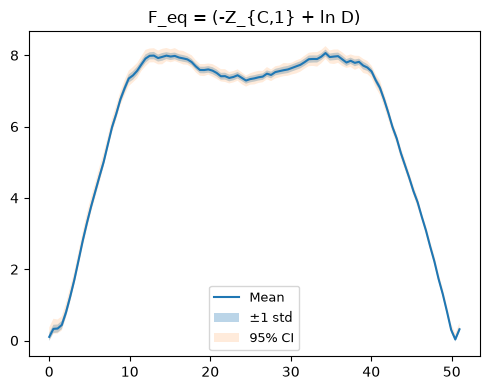

In [14]:
def bootstrap_Zeq(r_traj, i_traj, w_traj, n_boot=50, nbins=100, start=0, end=-1):
    i_gpu = cp.asarray(i_traj)
    _, inv = cp.unique(i_gpu, return_inverse=True)
    n_segs = int(inv.max()) + 1

    bins, _, _ = comp_Zeq(r_traj, nbins=nbins, i_traj=i_traj, w_traj=w_traj, start=start, end=end)
    zeq_boots, feq_boots = [], []

    for _ in range(n_boot):
        # Draw Poisson(1) multiplicity per trajectory piece and broadcast to frames
        seg_mult = cp.random.poisson(1.0, size=n_segs)
        w_boot = cp.asarray(w_traj) * seg_mult[inv]

        _, z_b, D_b = comp_Zeq(r_traj, nbins=nbins, i_traj=i_traj, w_traj=w_boot, start=start, end=end)
        f_b = -(z_b - cp.log(D_b))
        zeq_boots.append(z_b.get())
        feq_boots.append((f_b - cp.nanmin(f_b)).get())

    zeq_boots = np.array(zeq_boots)
    feq_boots = np.array(feq_boots)

    x = bins.get()[:-1]
    fig, ax = plt.subplots(1, 1, figsize=(5, 4))
    for axis, data, title in [(ax, feq_boots[:, :-1], 'F_eq = (-Z_{C,1} + ln D)'),]:
        mean = np.nanmean(data, axis=0)
        std = np.nanstd(data, axis=0)
        #if title != 'Z_{C,1}':
        #    plt.plot(x, mean[2] + 0.5 * (1 - np.cos(2 * np.pi * (x - x.min()) / (x.max() - x.min()))), c="red",lw=0.8)
        axis.plot(x, mean, label='Mean')
        axis.fill_between(x, mean - std, mean + std, alpha=0.3, label='±1 std')
        axis.fill_between(x, np.nanpercentile(data, 2.5, axis=0), np.nanpercentile(data, 97.5, axis=0), alpha=0.15, label='95% CI')
        
        axis.set_title(title)
        axis.legend()

    plt.tight_layout()
    plt.show()

bootstrap_Zeq(qn_traj, q.i_traj, d.path_weights, n_boot=100)

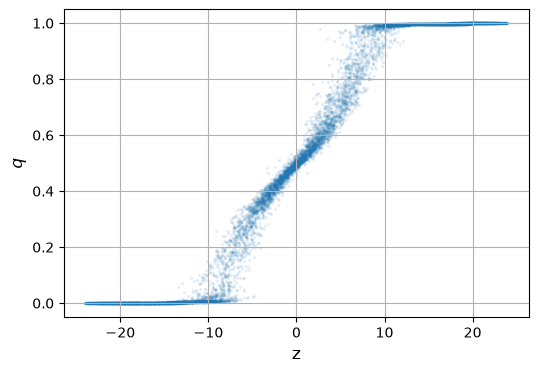

In [15]:
z_np = cp.asnumpy(datas['rejections'].lam)             # your distance / z CV array
q_np = cp.asnumpy(q.r_traj)      # fitted committor
m = ~cp.asnumpy(b_all)           # optional mask (exclude A/B basins)

idx = np.random.choice(np.where(m)[0], size=min(15000, m.sum()), replace=False)

plt.figure(figsize=(6, 4))
plt.scatter(z_np[idx], q_np[idx], s=2, alpha=0.08, rasterized=True)
plt.xlabel('z')
plt.ylabel('$q$')
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.show()

In [22]:
def crossing_prob_q_natural(q_nat, F_kbt, s_A, s_0, s_B):
    """
    Compute the 1D diffusive crossing probability P(reach s_B before s_A | start at s_0)
    on F(q_natural) in k_B T units.
    """
    m = np.isfinite(q_nat) & np.isfinite(F_kbt)
    s = np.asarray(q_nat[m], dtype=float)
    F = np.asarray(F_kbt[m], dtype=float)

    # Shift by max(F) in [s_A, s_B] to prevent exp() overflow
    win = (s >= s_A) & (s <= s_B)
    F_shift = F - np.max(F[win])

    def integral_expF(lo, hi):
        grid = np.linspace(lo, hi, 2000)
        F_interp = np.interp(grid, s, F_shift)
        return np.trapezoid(np.exp(F_interp), grid)

    num = integral_expF(s_A, s_0)
    den = integral_expF(s_A, s_B)
    return num / den

def rate_q_natural(q_nat, F_kbt, D0=1.0, q_min_A=None, q_max_A=None):
    """
    Compute Kramers / MFPT rate k_AB on a 1D profile F(q_natural) in k_B T units
    with constant diffusivity D0.
    
    Parameters
    ----------
    q_nat : 1D array
        Grid points in the natural coordinate (where D is constant).
    F_kbt : 1D array
        Free energy F(q_nat) in units of k_B T.
    D0 : float
        Constant diffusivity in q_natural units (length^2 / time).
    q_min_A, q_max_A : float, optional
        Integration bounds defining basin A. Defaults to [q_nat[0], argmax(F)].
    """
    m = np.isfinite(q_nat) & np.isfinite(F_kbt)
    q = np.asarray(q_nat[m], dtype=float)
    F = np.asarray(F_kbt[m], dtype=float)

    # Shift F by its maximum for numerical stability (cancels in Z_A * Z_barrier)
    F_shift = F - np.max(F)

    # Basin A partition function Z_A = \int_A exp(-F) dq
    i_peak = np.argmax(F_shift)
    lo = q[0] if q_min_A is None else q_min_A
    hi = q[i_peak] if q_max_A is None else q_max_A
    mask_A = (q >= lo) & (q <= hi)
    Z_A = np.trapezoid(np.exp(-F_shift[mask_A]), q[mask_A])

    # Barrier resistance integral \int_{q_A}^{q_B} exp(+F) dq
    # Integrate between the two basin minima (or across the full profile)
    i_min_A = np.argmin(F_shift[:i_peak + 1])
    i_min_B = i_peak + np.argmin(F_shift[i_peak:])
    R_AB = np.trapezoid(np.exp(F_shift[i_min_A:i_min_B + 1]), q[i_min_A:i_min_B + 1])

    k_AB = D0 / (Z_A * R_AB)
    return k_AB, 1.0 / k_AB  # rate, MFPT


qn = cp.asarray(qn_traj)
t  = cp.asarray(q.t_traj)
w_all = cp.asarray(d.path_weights, dtype=float)[:-1]

ds = qn[1:] - qn[:-1]
dt_step = t[1:] - t[:-1]

valid = (cp.asarray(q.i_traj[1:] == q.i_traj[:-1])
         & (dt_step > 0)
         & cp.isfinite(ds)
         & cp.isfinite(w_all))

w_v = w_all[valid]
D0 = float(cp.sum(w_v * (ds[valid] ** 2) / dt_step[valid]) / (2.0 * cp.sum(w_v)))
print(f"D0 = {D0:.6f}, valid steps = {int(cp.sum(valid))}/{len(ds)}")

dt_unit = float(cp.median(dt_step[valid]))
print(f"Median step in q.t_traj = {dt_unit}")

# 1. Free energy profile on qn_traj
qn_bins, zeq_qn, _ = comp_Zeq(qn_traj, nbins=100, i_traj=q.i_traj, w_traj=d.path_weights)
qn_mid = cp.asnumpy(0.5 * (qn_bins[:-1] + qn_bins[1:]))
F_qn = cp.asnumpy(-zeq_qn[:-1])  # since D(qn) is constant, -ln D0 is just an additive constant

# 2. Kramers rate using empirical D0 = 0.007401
k_AB, mfpt = rate_q_natural(qn_mid, F_qn, D0=D0)
print(f"k_AB = {k_AB:.4e} per [unit of q.t_traj]")
print(f"k_AB = {k_AB/0.02/1e-12:.4e} per second")

# 1. Measure s_A (at lambda_A) and the actual first-crossing positions s_0 just past lambda_A
z_np = cp.asnumpy(datas['rejections'].lam)
qn_np = cp.asnumpy(qn_traj)
ok_np = cp.asnumpy(q.i_traj[1:] == q.i_traj[:-1])
w_np = cp.asnumpy(d.path_weights)[:-1]

# Frames that cross from z < lambda_A to z >= lambda_A in a single step
lambda_A = -23.9999
cross = ok_np & (z_np[:-1] < lambda_A) & (z_np[1:] >= lambda_A)

s_A = np.average(qn_np[:-1][cross], weights=w_np[cross])
s_0 = np.average(qn_np[1:][cross], weights=w_np[cross])
s_B = np.nanmax(qn_np)  # or mean qn at z >= lambda_B

# 2. Evaluate the 1D crossing probability from that first-crossing distribution
P_cross = crossing_prob_q_natural(qn_mid, F_qn, s_A=s_A, s_0=s_0, s_B=s_B)
print(f"s_A = {s_A:.4f}, s_0 = {s_0:.4f} -> P_A(B | lambda_0=lambda_A) = {P_cross:.4e}")

D0 = 0.006665, valid steps = 5634601/5690325
Median step in q.t_traj = 1.0
k_AB = 5.7675e-06 per [unit of q.t_traj]
k_AB = 2.8838e+08 per second
s_A = 0.0059, s_0 = 0.0080 -> P_A(B | lambda_0=lambda_A) = 1.8264e-06


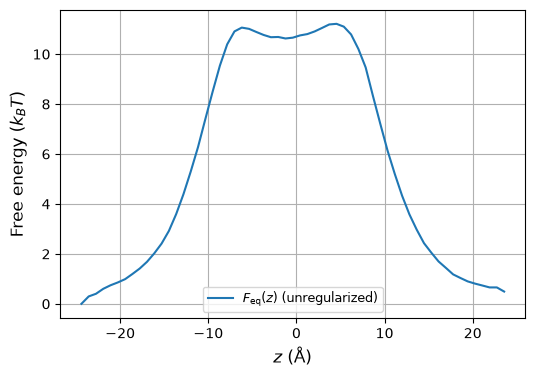

In [16]:
def comp_Zeq_unreg(r_traj, nbins=60, i_traj=None, w_traj=None, min_count=20):
    r = cp.asarray(r_traj)
    edges = cp.linspace(r.min(), r.max(), nbins + 1)
    dr = r[1:] - r[:-1]

    ok = cp.ones(len(dr), dtype=bool)
    if i_traj is not None:
        i = cp.asarray(i_traj)
        ok &= (i[1:] == i[:-1])

    w = ok.astype(float) if w_traj is None else cp.asarray(w_traj, dtype=float)[:-1] * ok
    b = cp.clip(cp.searchsorted(edges, r, side='right') - 1, 0, nbins - 1)[:-1]

    n  = cp.bincount(b, weights=w, minlength=nbins)
    s1 = cp.bincount(b, weights=w * dr, minlength=nbins)
    s2 = cp.bincount(b, weights=w * (dr ** 2), minlength=nbins)

    m = n >= min_count
    n_safe = cp.where(m, n, 1.0)
    drift = s1 / n_safe
    D = cp.where(m, (s2 / n_safe - drift ** 2) / 2.0, cp.nan)

    integrand = cp.where(m, drift / D, 0.0)
    zeq = cp.where(m, cp.cumsum(integrand) * (edges[1] - edges[0]), cp.nan)
    return 0.5 * (edges[:-1] + edges[1:]), zeq, D

z_mid, zeq_z, D_z = comp_Zeq_unreg(datas['rejections'].lam, nbins=60, i_traj=q.i_traj, w_traj=d.path_weights, min_count=20)
Fz_direct = -(zeq_z - cp.log(D_z))
Fz_direct -= cp.nanmin(Fz_direct[:-1])

plt.figure(figsize=(6, 4))
plt.plot(z_mid.get()[:-1], Fz_direct.get()[:-1], label='$F_{\\mathrm{eq}}(z)$ (unregularized)')
plt.xlabel('$z$ (Å)')
plt.ylabel('Free energy ($k_B T$)')
plt.legend()
plt.grid(True)
plt.show()

## 7. Results

**Table:** per weighting and seed, the data size, the final and lowest `zqs_z` of the run (its own data; about 2 or less is consistent), and with the exact committor the path-weighted RMS of fit − exact over the frames with 0.05 < q_exact < 0.95 and over the bins in that range.

**Committor along λ:** the path-weighted mean q per λ bin of every fit, the exact committor averaged the same way (dashed), and fit − exact.

,,paths,pieces,frames,zqs_z_final,zqs_z_min,fit_minutes
weighting,seed,,,,,,
rejections,2,27219,66874,6837312,6.2603,5.6289,24.9356


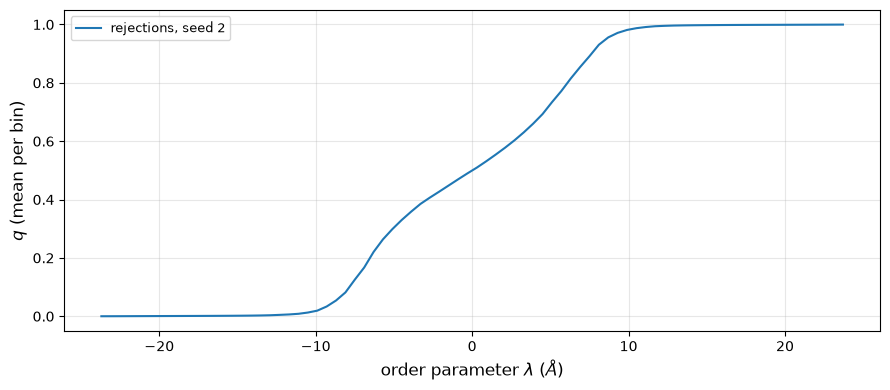

In [17]:
rows, profiles = [], {}
for name, fit in fits.items():
    d = datas[name]
    fr = ~(d.boundary0 | d.boundary1)
    edges = edges_for(d)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    qe = fit['q_exact']
    for s, r in fit['r'].items():
        row = dict(weighting=name, seed=s, paths=len(np.unique(d.group_traj)), pieces=int(d.i_traj.max() + 1),
                   frames=len(r), zqs_z_final=fit['zqs_z'][-1], zqs_z_min=fit['zqs_z'][1:].min(),
                   fit_minutes=fit['t_fit'] / 60 / len(fit['r']))
        profiles[(name, s)] = bm(d.path_weights * r) / w_mean
        if qe is not None:
            t = fr & (qe > 0.05) & (qe < 0.95)
            row['rms_frames'] = np.sqrt(np.sum(d.path_weights[t] * (r[t] - qe[t]) ** 2) / np.sum(d.path_weights[t]))
            pe = bm(d.path_weights * qe) / w_mean
            tb = (pe > 0.05) & (pe < 0.95)
            row['rms_bins_lambda'] = np.sqrt(np.nanmean((profiles[(name, s)] - pe)[tb] ** 2))
            profiles[('exact', name)] = pe
        rows.append(row)
summary = pd.DataFrame(rows).set_index(['weighting', 'seed'])
os.makedirs(OUT, exist_ok=True)
summary.to_csv(f'{OUT}/summary.csv')
display(summary.round(4))

edges = edges_for(data)
mid = (edges[0][1:] + edges[0][:-1]) / 2
has_exact = any(k[0] == 'exact' for k in profiles)
fig, axes = plt.subplots(2 if has_exact else 1, 1, figsize=(9, 7 if has_exact else 4), sharex=True, squeeze=False)
for (name, s), P in profiles.items():
    if name == 'exact':
        continue
    axes[0, 0].plot(mid, P, label=f'{name}, seed {s}')
    if has_exact:
        axes[1, 0].plot(mid, P - profiles[('exact', name)], label=f'{name}, seed {s}')
if has_exact:
    axes[0, 0].plot(mid, profiles[('exact', next(iter(fits)))], 'k--', label='exact')
    axes[1, 0].axhline(0, color='k', lw=0.8)
    axes[1, 0].set(ylabel='fit $-$ exact')
    axes[1, 0].grid(alpha=0.3)
axes[0, 0].set(ylabel='$q$ (mean per bin)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)
axes[-1, 0].set(xlabel=XLABEL)
fig.tight_layout()
fig.savefig(f'{OUT}/profiles.png', dpi=110)
plt.show()

**How q depends on every CV.** For every fit, the path-weighted mean q per bin of each CV (over the frames outside A and B) and the share of the variance of q that this CV alone explains, η² = Var(E[q | CV bin]) / Var(q). A CV with a high η² is closely related to the committor; a CV with a flat mean q does not matter by itself (it can still matter together with the others). The mean q curves are the committor averaged over all the other CVs at fixed value of this one, so they show where the CV acts, not a fit as a function of it alone.

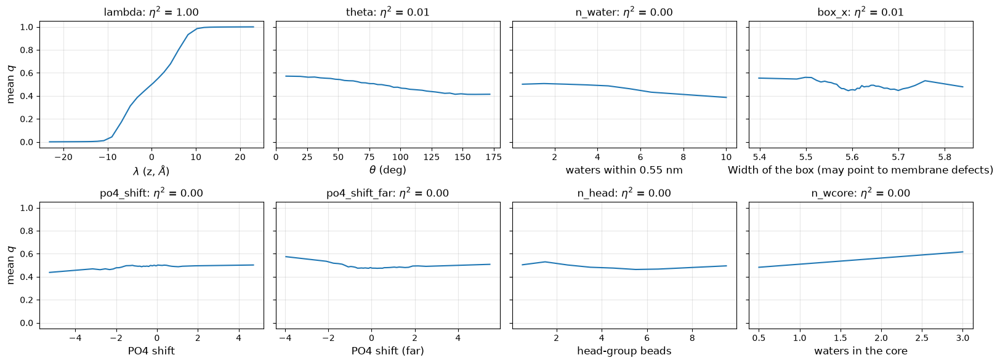

,eta2
lambda,0.996
theta,0.013
box_x,0.005
n_water,0.005
n_wcore,0.003
po4_shift_far,0.002
n_head,0.002
po4_shift,0.001


In [18]:
name0 = next(iter(fits))
d = datas[name0]
r0 = next(iter(fits[name0]['r'].values()))
fr = ~(d.boundary0 | d.boundary1)
w = d.path_weights
names = getattr(d, 'cv_names', [f'cv{j}' for j in range(d.X.shape[1])])
n_cv = d.X.shape[1]
ncol = 4
nrow = int(np.ceil(n_cv / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), squeeze=False, sharey=True)
q_mean = np.sum(w[fr] * r0[fr]) / np.sum(w[fr])
q_var = np.sum(w[fr] * (r0[fr] - q_mean) ** 2) / np.sum(w[fr])
eta = {}
for j, (ax, n) in enumerate(zip(axes.ravel(), names)):
    x = d.X[fr, j]; ww = w[fr]; qq = r0[fr]
    edges_j = np.quantile(x, np.linspace(0, 1, 41))                       # bins of equal frame count
    edges_j = np.unique(edges_j)
    bi = np.clip(np.digitize(x, edges_j) - 1, 0, len(edges_j) - 2)
    wb = np.bincount(bi, ww, len(edges_j) - 1)
    qb = np.bincount(bi, ww * qq, len(edges_j) - 1) / np.maximum(wb, 1e-300)
    eta[n] = np.sum(wb * (qb - q_mean) ** 2) / np.sum(wb) / q_var
    ax.plot((edges_j[1:] + edges_j[:-1]) / 2, qb)
    ax.set(xlabel=CV_LABELS.get(n, n) if 'CV_LABELS' in globals() else n, title=f'{n}: $\\eta^2$ = {eta[n]:.2f}')
    ax.grid(alpha=0.3)
for ax in axes.ravel()[n_cv:]:
    ax.axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel('mean $q$')
fig.tight_layout()
fig.savefig(f'{OUT}/q_vs_cvs.png', dpi=110)
plt.show()
display(pd.Series(eta, name='eta2').sort_values(ascending=False).round(3).to_frame())


## 8. Save

Every fit's q per frame with its frames, in the format of `load_tis_data_cupy.py`'s `committor.npz` (`r`, `lam`, `X_all`, `i_traj`, `t_traj`, `group_traj`, `path_weights`, `boundary0`, `boundary1`), as `<OUT>/<weighting>/seed<s>/committor.npz`. (`run_seeds` also saved each final q alone as `q_traj.npy`.)

In [21]:
for name, fit in fits.items():
    d = datas[name]
    for s, r in fit['r'].items():
        path = f'{folder}/committor.npz'
        np.savez(path, r=r, lam=d.lam, X_all=d.X_all, i_traj=d.i_traj, t_traj=d.t_traj, group_traj=d.group_traj,
                 path_weights=d.path_weights, boundary0=d.boundary0, boundary1=d.boundary1,
                 weighting=name, tis_dir=TIS_DIR)
        print('saved', path)

saved /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/cg_permeation/infretis_staple/CG_P2P5/rejections/seedhist0124yr_2/committor.npz
